In [ ]:
!nvidia-smi

Mon Oct 12 16:01:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

drive_project = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

zip_path = (
    drive_project
    / "localization_yolo_dataset.zip"
)

print("GOOGLE DRIVE DATASET CHECK")
print("==========================")

print("Project folder exists:", drive_project.exists())
print("ZIP exists:", zip_path.exists())

if zip_path.exists():
    size_gb = zip_path.stat().st_size / (1024 ** 3)

    print(f"ZIP size: {size_gb:.3f} GB")
    print("ZIP path:")
    print(zip_path)

GOOGLE DRIVE DATASET CHECK
Project folder exists: True
ZIP exists: True
ZIP size: 1.567 GB
ZIP path:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/localization_yolo_dataset.zip


In [ ]:
import zipfile
from pathlib import Path

extract_root = Path(
    "/content/localization_yolo_dataset"
)

extract_root.mkdir(
    parents=True,
    exist_ok=True
)

print("Extracting dataset...")

with zipfile.ZipFile(
    zip_path,
    "r"
) as zf:
    zf.extractall(extract_root)

print("\nEXTRACTION COMPLETE")
print("===================")

print("Location:")
print(extract_root)

print("\nChecking folders:")

print(
    "Train images:",
    len(list(
        (extract_root / "images" / "train").glob("*")
    ))
)

print(
    "Validation images:",
    len(list(
        (extract_root / "images" / "validation").glob("*")
    ))
)

print(
    "Test images:",
    len(list(
        (extract_root / "images" / "test").glob("*")
    ))
)

print(
    "data.yaml exists:",
    (extract_root / "data.yaml").exists()
)

Extracting dataset...

EXTRACTION COMPLETE
Location:
/content/localization_yolo_dataset

Checking folders:
Train images: 5124
Validation images: 640
Test images: 641
data.yaml exists: True


In [ ]:
from pathlib import Path

data_yaml = (
    extract_root
    / "data.yaml"
)

yaml_content = f"""path: {extract_root}
train: images/train
val: images/validation
test: images/test

names:
  0: license_plate
"""

data_yaml.write_text(
    yaml_content,
    encoding="utf-8"
)

print("COLAB DATA.YAML UPDATED")
print("=======================")

print(data_yaml.read_text(
    encoding="utf-8"
))

COLAB DATA.YAML UPDATED
path: /content/localization_yolo_dataset
train: images/train
val: images/validation
test: images/test

names:
  0: license_plate



In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.9 MB/s eta 0:00:00


In [ ]:
import torch
import ultralytics

print("YOLO ENVIRONMENT CHECK")
print("======================")

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO ENVIRONMENT CHECK
Ultralytics: 8.4.175
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU count: 1


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("MODEL LOADED SUCCESSFULLY")
print("=========================")

print("Model:")
print(model.model_name)

print("\nTask:")
print(model.task)

print("\nDataset:")
print(data_yaml)

MODEL LOADED SUCCESSFULLY
Model:
yolo11n.pt

Task:
detect

Dataset:
/content/localization_yolo_dataset/data.yaml


In [ ]:
sanity_results = model.train(
    data=str(data_yaml),
    epochs=1,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/runs",
    name="localization_sanity",
    pretrained=True,
    verbose=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/localization_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=localization_sanity, nbs=64, nms=None, opset=

In [ ]:
import shutil
from pathlib import Path

sanity_source = Path(
    "/content/runs/localization_sanity"
)

sanity_backup = (
    drive_project
    / "training_results"
    / "localization_sanity"
)

sanity_backup.parent.mkdir(
    parents=True,
    exist_ok=True
)

if sanity_backup.exists():
    shutil.rmtree(sanity_backup)

shutil.copytree(
    sanity_source,
    sanity_backup
)

print("SANITY RESULTS BACKED UP")
print("========================")

print("Google Drive location:")
print(sanity_backup)

print(
    "\nbest.pt exists:",
    (sanity_backup / "weights" / "best.pt").exists()
)

print(
    "last.pt exists:",
    (sanity_backup / "weights" / "last.pt").exists()
)

SANITY RESULTS BACKED UP
Google Drive location:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_sanity

best.pt exists: True
last.pt exists: True


In [ ]:
from ultralytics import YOLO

localization_model = YOLO(
    "yolo11n.pt"
)

localization_results = localization_model.train(
    data=str(data_yaml),
    epochs=50,
    patience=10,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    pretrained=True,
    optimizer="auto",
    project="/content/runs",
    name="localization_yolo11n",
    save=True,
    plots=True,
    verbose=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/localization_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=localization_yolo11n, nbs=64, nms=None, opse

In [ ]:
import shutil
from pathlib import Path

training_source = Path(
    "/content/runs/localization_yolo11n"
)

training_backup = (
    drive_project
    / "training_results"
    / "localization_yolo11n"
)

training_backup.parent.mkdir(
    parents=True,
    exist_ok=True
)

if training_backup.exists():
    shutil.rmtree(training_backup)

shutil.copytree(
    training_source,
    training_backup
)

best_model = (
    training_backup
    / "weights"
    / "best.pt"
)

last_model = (
    training_backup
    / "weights"
    / "last.pt"
)

print("LOCALIZATION TRAINING BACKED UP")
print("================================")

print("Google Drive:")
print(training_backup)

print("\nbest.pt exists:", best_model.exists())
print("last.pt exists:", last_model.exists())

if best_model.exists():
    print(
        "best.pt size:",
        f"{best_model.stat().st_size / (1024 ** 2):.2f} MB"
    )

LOCALIZATION TRAINING BACKED UP
Google Drive:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_yolo11n

best.pt exists: True
last.pt exists: True
best.pt size: 5.24 MB


In [ ]:
from ultralytics import YOLO

best_model_path = (
    "/content/drive/MyDrive/"
    "Bangladesh_License_Plate_Recognition/"
    "training_results/localization_yolo11n/"
    "weights/best.pt"
)

test_model = YOLO(best_model_path)

test_results = test_model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/runs",
    name="localization_test",
    plots=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 56.8±27.2 MB/s, size: 272.3 KB)
val: Scanning /content/localization_yolo_dataset/labels/test... 641 images, 172 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 641/641 414.5it/s 1.5s
val: New cache created: /content/localization_yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 4.0it/s 10.4s
                   all        641        485      0.983      0.971      0.991      0.788
Speed: 1.6ms preprocess, 4.8ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/runs/localization_test


In [ ]:
import shutil
from pathlib import Path

test_source = Path(
    "/content/runs/localization_test"
)

test_backup = (
    drive_project
    / "training_results"
    / "localization_test"
)

if test_backup.exists():
    shutil.rmtree(test_backup)

shutil.copytree(
    test_source,
    test_backup
)

print("TEST RESULTS BACKED UP")
print("======================")
print("Google Drive:")
print(test_backup)
print("\nBackup exists:", test_backup.exists())

TEST RESULTS BACKED UP
Google Drive:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_test

Backup exists: True


In [ ]:
from pathlib import Path

char_yolo = Path(
    "../dataset/yolo/Character Recognition"
)

total_size = sum(
    f.stat().st_size
    for f in char_yolo.rglob("*")
    if f.is_file()
)

print("Character YOLO dataset")
print("======================")
print("Exists:", char_yolo.exists())
print("Size MB:", round(total_size / (1024 ** 2), 2))
print("Size GB:", round(total_size / (1024 ** 3), 3))

for split in ["train", "validation", "test"]:
    images = list((char_yolo / "images" / split).glob("*"))
    labels = list((char_yolo / "labels" / split).glob("*.txt"))

    print(
        f"{split}:",
        len(images),
        "images |",
        len(labels),
        "labels"
    )

Character YOLO dataset
Exists: False
Size MB: 0.0
Size GB: 0.0
train: 0 images | 0 labels
validation: 0 images | 0 labels
test: 0 images | 0 labels


In [ ]:
from pathlib import Path

char_yolo = Path(
    r"D:\Documents\Ml project\Bangladesh_License_Plate_Recognition\dataset\yolo\Character Recognition"
)

print("Character YOLO dataset")
print("======================")
print("Exists:", char_yolo.exists())

if char_yolo.exists():
    total_size = sum(
        f.stat().st_size
        for f in char_yolo.rglob("*")
        if f.is_file()
    )

    print("Size MB:", round(total_size / (1024 ** 2), 2))
    print("Size GB:", round(total_size / (1024 ** 3), 3))

    for split in ["train", "validation", "test"]:
        images = [
            f for f in (char_yolo / "images" / split).iterdir()
            if f.is_file()
        ]

        labels = list(
            (char_yolo / "labels" / split).glob("*.txt")
        )

        print(
            f"{split}:",
            len(images),
            "images |",
            len(labels),
            "labels"
        )

Character YOLO dataset
Exists: False


In [ ]:
from pathlib import Path

character_zip = (
    Path("/content/drive/MyDrive/Bangladesh_License_Plate_Recognition")
    / "character_yolo_dataset.zip"
)

print("CHARACTER DATASET CHECK")
print("=======================")
print("ZIP exists:", character_zip.exists())

if character_zip.exists():
    print(
        "ZIP size MB:",
        round(character_zip.stat().st_size / (1024 ** 2), 2)
    )

CHARACTER DATASET CHECK
ZIP exists: True
ZIP size MB: 118.6


In [ ]:
import zipfile

print("CHARACTER ZIP VERIFICATION")
print("==========================")

with zipfile.ZipFile(character_zip, "r") as zf:
    bad_file = zf.testzip()
    files = zf.namelist()

print("ZIP integrity:", "PASS" if bad_file is None else f"FAIL: {bad_file}")

image_files = [
    f for f in files
    if f.startswith("images/") and not f.endswith("/")
]

label_files = [
    f for f in files
    if f.startswith("labels/") and f.endswith(".txt")
]

yaml_files = [
    f for f in files
    if f.endswith("data.yaml")
]

print("Images:", len(image_files))
print("Labels:", len(label_files))
print("data.yaml:", len(yaml_files))
print("Total files:", len(files))

CHARACTER ZIP VERIFICATION
ZIP integrity: PASS
Images: 4061
Labels: 4061
data.yaml: 1
Total files: 8123


In [ ]:
import zipfile
from pathlib import Path

character_root = Path(
    "/content/character_yolo_dataset"
)

character_root.mkdir(
    parents=True,
    exist_ok=True
)

with zipfile.ZipFile(character_zip, "r") as zf:
    zf.extractall(character_root)

print("CHARACTER DATASET EXTRACTED")
print("===========================")

for split in ["train", "validation", "test"]:
    images = [
        f for f in (character_root / "images" / split).iterdir()
        if f.is_file()
    ]

    labels = list(
        (character_root / "labels" / split).glob("*.txt")
    )

    print(
        f"{split}:",
        len(images),
        "images |",
        len(labels),
        "labels"
    )

print(
    "\ndata.yaml exists:",
    (character_root / "data.yaml").exists()
)

CHARACTER DATASET EXTRACTED
train: 3480 images | 3480 labels
validation: 363 images | 363 labels
test: 218 images | 218 labels

data.yaml exists: True


In [ ]:
character_yaml = character_root / "data.yaml"

character_yaml.write_text(
"""path: /content/character_yolo_dataset
train: images/train
val: images/validation
test: images/test

names:
  0: "0"
  1: "1"
  2: "2"
  3: "3"
  4: "4"
  5: "5"
  6: "6"
  7: "7"
  8: "8"
  9: "9"
  10: "ba"
  11: "ca"
  12: "chattogram"
  13: "da"
  14: "dhaka"
  15: "ga"
  16: "gha"
  17: "ha"
  18: "ja"
  19: "jashore"
  20: "ka"
  21: "kha"
  22: "khulna"
  23: "metro"
  24: "na"
  25: "ta"
  26: "va"
""",
    encoding="utf-8"
)

print("CHARACTER YAML UPDATED")
print("======================")
print(character_yaml.read_text())

CHARACTER YAML UPDATED
path: /content/character_yolo_dataset
train: images/train
val: images/validation
test: images/test

names:
  0: "0"
  1: "1"
  2: "2"
  3: "3"
  4: "4"
  5: "5"
  6: "6"
  7: "7"
  8: "8"
  9: "9"
  10: "ba"
  11: "ca"
  12: "chattogram"
  13: "da"
  14: "dhaka"
  15: "ga"
  16: "gha"
  17: "ha"
  18: "ja"
  19: "jashore"
  20: "ka"
  21: "kha"
  22: "khulna"
  23: "metro"
  24: "na"
  25: "ta"
  26: "va"



In [ ]:
from ultralytics import YOLO

character_model = YOLO("yolo11n.pt")

character_sanity_results = character_model.train(
    data=str(character_yaml),
    epochs=1,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    pretrained=True,
    project="/content/runs",
    name="character_sanity",
    save=True,
    plots=True,
    verbose=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/character_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=character_sanity, nbs=64, nms=None, opset=None, 

In [ ]:
import shutil
from pathlib import Path

character_sanity_source = Path(
    "/content/runs/character_sanity"
)

character_sanity_backup = (
    drive_project
    / "training_results"
    / "character_sanity"
)

if character_sanity_backup.exists():
    shutil.rmtree(character_sanity_backup)

shutil.copytree(
    character_sanity_source,
    character_sanity_backup
)

print("CHARACTER SANITY BACKED UP")
print("==========================")
print("Google Drive:")
print(character_sanity_backup)

print(
    "\nbest.pt exists:",
    (character_sanity_backup / "weights" / "best.pt").exists()
)

print(
    "last.pt exists:",
    (character_sanity_backup / "weights" / "last.pt").exists()
)

CHARACTER SANITY BACKED UP
Google Drive:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/character_sanity

best.pt exists: True
last.pt exists: True


In [ ]:
from ultralytics import YOLO

character_model = YOLO("yolo11n.pt")

character_results = character_model.train(
    data=str(character_yaml),
    epochs=80,
    patience=15,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    pretrained=True,
    optimizer="auto",
    project="/content/runs",
    name="character_yolo11n",
    save=True,
    plots=True,
    verbose=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/character_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=character_yolo11n, nbs=64, nms=None, opset=None

In [ ]:
import shutil
from pathlib import Path

character_training_source = Path(
    "/content/runs/character_yolo11n"
)

character_training_backup = (
    drive_project
    / "training_results"
    / "character_yolo11n"
)

if character_training_backup.exists():
    shutil.rmtree(character_training_backup)

shutil.copytree(
    character_training_source,
    character_training_backup
)

best_character_model = (
    character_training_backup
    / "weights"
    / "best.pt"
)

last_character_model = (
    character_training_backup
    / "weights"
    / "last.pt"
)

print("CHARACTER TRAINING BACKED UP")
print("============================")
print("Google Drive:")
print(character_training_backup)

print(
    "\nbest.pt exists:",
    best_character_model.exists()
)

print(
    "last.pt exists:",
    last_character_model.exists()
)

if best_character_model.exists():
    print(
        "best.pt size:",
        f"{best_character_model.stat().st_size / (1024 ** 2):.2f} MB"
    )

CHARACTER TRAINING BACKED UP
Google Drive:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/character_yolo11n

best.pt exists: True
last.pt exists: True
best.pt size: 5.26 MB


In [ ]:
from ultralytics import YOLO

character_test_model = YOLO(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/character_yolo11n/weights/best.pt"
)

character_test_results = character_test_model.val(
    data=str(character_yaml),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    project="/content/runs",
    name="character_test",
    plots=True
)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,603,369 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 214.1±33.2 MB/s, size: 11.6 KB)
val: Scanning /content/character_yolo_dataset/labels/test... 218 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 218/218 1.3Kit/s 0.2s
val: New cache created: /content/character_yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 2.9it/s 4.8s
                   all        218       1921      0.933      0.918      0.944      0.708
                     0        107        153       0.98      0.993      0.993      0.732
                     1        169        281      0.989      0.986      0.994      0.736
                     2        112        145      0.994      0.979      0.995      0.744
                     3        100        125      0.984

In [ ]:
import shutil
from pathlib import Path

character_test_source = Path(
    "/content/runs/character_test"
)

character_test_backup = (
    drive_project
    / "training_results"
    / "character_test"
)

if character_test_backup.exists():
    shutil.rmtree(character_test_backup)

shutil.copytree(
    character_test_source,
    character_test_backup
)

print("CHARACTER TEST RESULTS BACKED UP")
print("=================================")

print(character_test_backup)

print(
    "\nBackup exists:",
    character_test_backup.exists()
)

CHARACTER TEST RESULTS BACKED UP
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/character_test

Backup exists: True


In [ ]:
from pathlib import Path

localization_best = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/"
    "training_results/localization_yolo11n/weights/best.pt"
)

character_best = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/"
    "training_results/character_yolo11n/weights/best.pt"
)

print("FINAL MODEL CHECK")
print("=================")

print("Localization model:")
print(localization_best)
print("Exists:", localization_best.exists())

print("\nCharacter Recognition model:")
print(character_best)
print("Exists:", character_best.exists())

if localization_best.exists() and character_best.exists():
    print("\n✅ BOTH FINAL MODELS ARE READY")
else:
    print("\n❌ ONE OR MORE MODELS ARE MISSING")

FINAL MODEL CHECK
Localization model:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_yolo11n/weights/best.pt
Exists: True

Character Recognition model:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/character_yolo11n/weights/best.pt
Exists: True

✅ BOTH FINAL MODELS ARE READY


In [ ]:
from ultralytics import YOLO

localization_model = YOLO(str(localization_best))
character_model = YOLO(str(character_best))

print("MODELS LOADED")
print("=============")

print(
    "Localization classes:",
    localization_model.names
)

print(
    "Character classes:",
    character_model.names
)

print("\n✅ BOTH MODELS LOADED SUCCESSFULLY")

MODELS LOADED
Localization classes: {0: 'license_plate'}
Character classes: {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: 'ba', 11: 'ca', 12: 'chattogram', 13: 'da', 14: 'dhaka', 15: 'ga', 16: 'gha', 17: 'ha', 18: 'ja', 19: 'jashore', 20: 'ka', 21: 'kha', 22: 'khulna', 23: 'metro', 24: 'na', 25: 'ta', 26: 'va'}

✅ BOTH MODELS LOADED SUCCESSFULLY


Saving ee40ef56a767f6a396e53052e219147a.jpg to ee40ef56a767f6a396e53052e219147a (1).jpg
TEST IMAGE
File: ee40ef56a767f6a396e53052e219147a (1).jpg
Size: (4032, 3024)
Mode: RGB


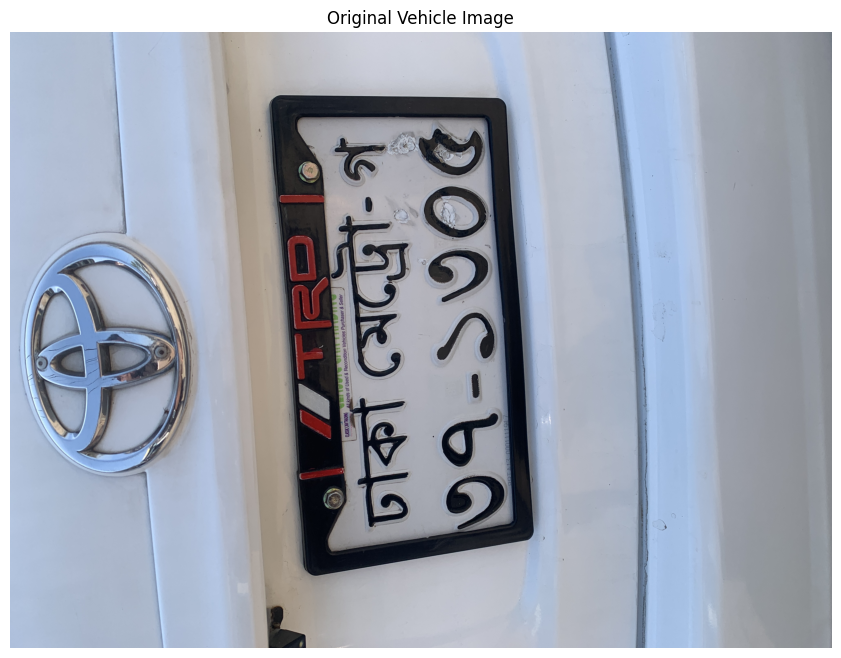

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

uploaded = files.upload()

vehicle_image_path = Path(next(iter(uploaded)))

vehicle_image = Image.open(vehicle_image_path)

print("TEST IMAGE")
print("==========")
print("File:", vehicle_image_path)
print("Size:", vehicle_image.size)
print("Mode:", vehicle_image.mode)

plt.figure(figsize=(12, 8))
plt.imshow(vehicle_image)
plt.axis("off")
plt.title("Original Vehicle Image")
plt.show()


image 1/1 /content/ee40ef56a767f6a396e53052e219147a (1).jpg: 640x480 3 license_plates, 9.5ms
Speed: 2.8ms preprocess, 9.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)
LOCALIZATION RESULT
Detected plates: 3
Plate 1:
Box: [     438.73      1441.5      2224.4      2664.9]
Confidence: 0.657
Plate 2:
Box: [     482.04      1462.3      1818.5      2531.1]
Confidence: 0.5437
Plate 3:
Box: [     721.04      1413.2      2695.6      2515.4]
Confidence: 0.3914


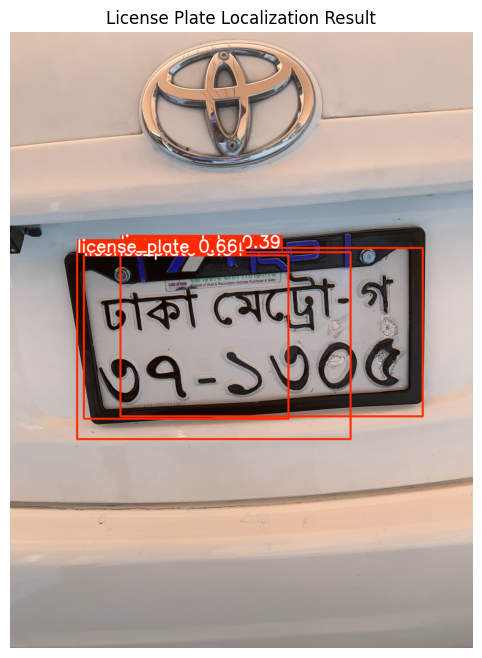

In [ ]:
import matplotlib.pyplot as plt

results = localization_model.predict(
    source=str(vehicle_image_path),
    conf=0.25,
    device=0
)

result = results[0]

print("LOCALIZATION RESULT")
print("==================")

print("Detected plates:", len(result.boxes))

if len(result.boxes) > 0:

    for i, box in enumerate(result.boxes):

        xyxy = box.xyxy[0].cpu().numpy()
        confidence = float(box.conf[0])

        print(
            f"Plate {i+1}:"
        )

        print(
            "Box:",
            xyxy
        )

        print(
            "Confidence:",
            round(confidence, 4)
        )

else:
    print("No plate detected")


annotated = result.plot()

plt.figure(figsize=(12,8))
plt.imshow(annotated)
plt.axis("off")
plt.title("License Plate Localization Result")
plt.show()

BEST PLATE DETECTION
Confidence: 0.657
Box: (438, 1441, 2224, 2664)
Crop size: (1786, 1223)


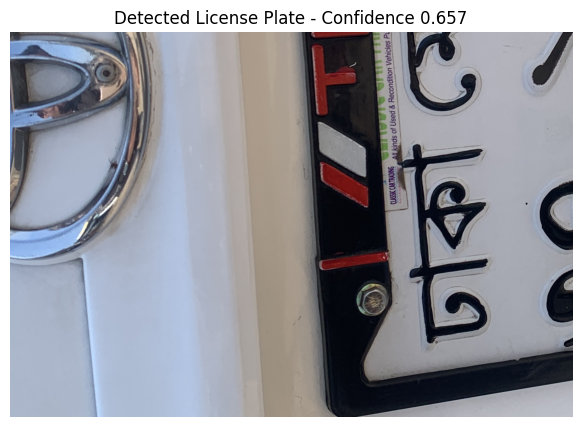

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

if len(result.boxes) == 0:
    print("❌ No license plate detected")

else:
    best_index = int(result.boxes.conf.argmax())

    best_box = result.boxes[best_index]

    x1, y1, x2, y2 = best_box.xyxy[0].cpu().numpy()

    confidence = float(best_box.conf[0])

    x1 = max(0, int(x1))
    y1 = max(0, int(y1))
    x2 = min(vehicle_image.width, int(x2))
    y2 = min(vehicle_image.height, int(y2))

    plate_crop = vehicle_image.crop(
        (x1, y1, x2, y2)
    )

    print("BEST PLATE DETECTION")
    print("====================")
    print("Confidence:", round(confidence, 4))
    print("Box:", (x1, y1, x2, y2))
    print("Crop size:", plate_crop.size)

    plt.figure(figsize=(10, 5))
    plt.imshow(plate_crop)
    plt.axis("off")
    plt.title(
        f"Detected License Plate - Confidence {confidence:.3f}"
    )
    plt.show()

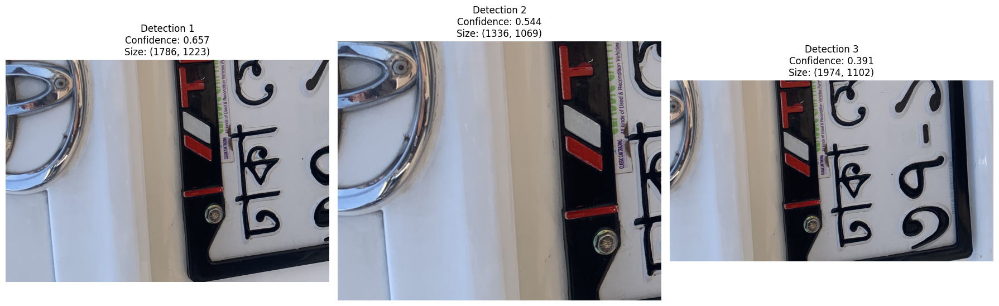

In [ ]:
import matplotlib.pyplot as plt

boxes = result.boxes

fig, axes = plt.subplots(
    1,
    len(boxes),
    figsize=(18, 6)
)

if len(boxes) == 1:
    axes = [axes]

for i, box in enumerate(boxes):

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    x1 = max(0, int(x1))
    y1 = max(0, int(y1))
    x2 = min(vehicle_image.width, int(x2))
    y2 = min(vehicle_image.height, int(y2))

    crop = vehicle_image.crop(
        (x1, y1, x2, y2)
    )

    conf = float(box.conf[0])

    axes[i].imshow(crop)
    axes[i].axis("off")
    axes[i].set_title(
        f"Detection {i+1}\nConfidence: {conf:.3f}\nSize: {crop.size}"
    )

plt.tight_layout()
plt.show()

ROTATED IMAGE
Original size: (4032, 3024)
Rotated size: (3024, 4032)


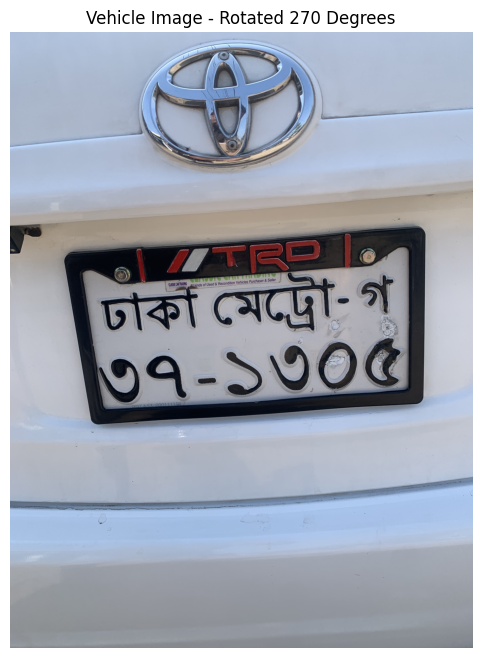

In [ ]:
rotated_vehicle_image = vehicle_image.rotate(
    270,
    expand=True
)

print("ROTATED IMAGE")
print("=============")
print("Original size:", vehicle_image.size)
print("Rotated size:", rotated_vehicle_image.size)

plt.figure(figsize=(12, 8))
plt.imshow(rotated_vehicle_image)
plt.axis("off")
plt.title("Vehicle Image - Rotated 270 Degrees")
plt.show()


0: 640x480 1 license_plate, 10.9ms
Speed: 2.7ms preprocess, 10.9ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 480)
ROTATED LOCALIZATION RESULT
Detected plates: 1

Plate 1
Box: [     438.73      1441.5      2224.4      2664.9]
Confidence: 0.657


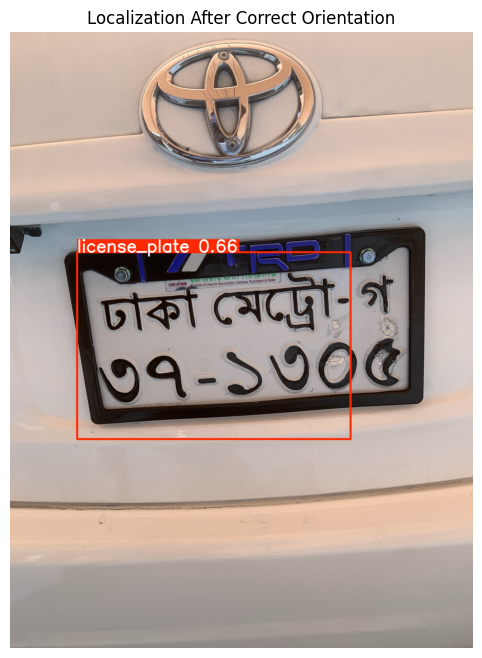

In [ ]:
rotated_results = localization_model.predict(
    source=rotated_vehicle_image,
    conf=0.25,
    iou=0.5,
    device=0
)

rotated_result = rotated_results[0]

print("ROTATED LOCALIZATION RESULT")
print("===========================")
print("Detected plates:", len(rotated_result.boxes))

for i, box in enumerate(rotated_result.boxes):
    xyxy = box.xyxy[0].cpu().numpy()
    confidence = float(box.conf[0])

    print(f"\nPlate {i+1}")
    print("Box:", xyxy)
    print("Confidence:", round(confidence, 4))

annotated = rotated_result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated)
plt.axis("off")
plt.title("Localization After Correct Orientation")
plt.show()

FINAL PLATE CROP
Box: (438, 1441, 2224, 2664)
Crop size: (1786, 1223)
Localization confidence: 0.657


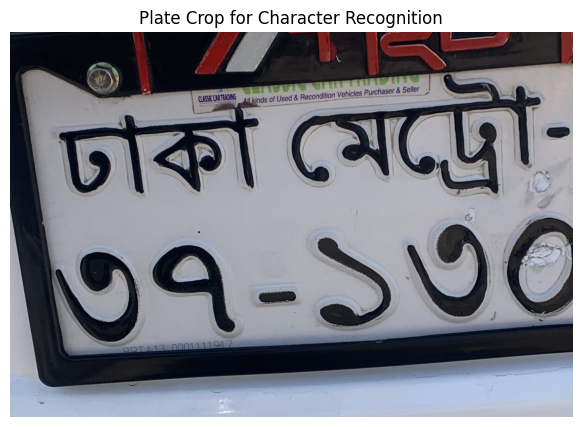

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

best_index = int(rotated_result.boxes.conf.argmax())
best_box = rotated_result.boxes[best_index]

x1, y1, x2, y2 = best_box.xyxy[0].cpu().numpy()

x1 = max(0, int(x1))
y1 = max(0, int(y1))
x2 = min(rotated_vehicle_image.width, int(x2))
y2 = min(rotated_vehicle_image.height, int(y2))

rotated_plate_crop = rotated_vehicle_image.crop(
    (x1, y1, x2, y2)
)

print("FINAL PLATE CROP")
print("================")
print("Box:", (x1, y1, x2, y2))
print("Crop size:", rotated_plate_crop.size)
print(
    "Localization confidence:",
    round(float(best_box.conf[0]), 4)
)

plt.figure(figsize=(10, 5))
plt.imshow(rotated_plate_crop)
plt.axis("off")
plt.title("Plate Crop for Character Recognition")
plt.show()


0: 448x640 1 0, 1 1, 2 3s, 1 7, 1 dhaka, 1 metro, 43.5ms
Speed: 11.2ms preprocess, 43.5ms inference, 6.8ms postprocess per image at shape (1, 3, 448, 640)
CHARACTER RECOGNITION RESULT
Detected objects: 7

Detection 1
Class: 3
Confidence: 0.91
Box: [160.9, 632.5, 447.3, 1020.9]

Detection 2
Class: metro
Confidence: 0.8966
Box: [853.2, 115.8, 1714.0, 552.0]

Detection 3
Class: 7
Confidence: 0.8957
Box: [435.2, 615.5, 748.5, 1007.6]

Detection 4
Class: 3
Confidence: 0.8859
Box: [1250.2, 548.7, 1558.5, 961.3]

Detection 5
Class: 1
Confidence: 0.8812
Box: [930.2, 595.7, 1251.6, 983.2]

Detection 6
Class: dhaka
Confidence: 0.8517
Box: [121.3, 228.7, 840.7, 578.6]

Detection 7
Class: 0
Confidence: 0.4301
Box: [1553.2, 543.0, 1786.0, 956.6]


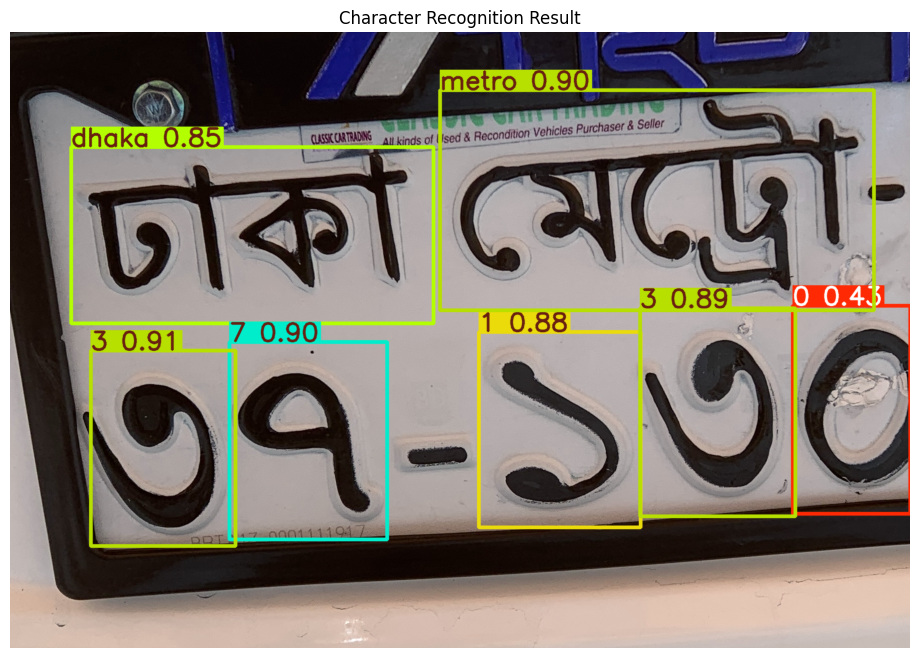

In [ ]:
character_results = character_model.predict(
    source=rotated_plate_crop,
    conf=0.25,
    iou=0.5,
    imgsz=640,
    device=0
)

character_result = character_results[0]

print("CHARACTER RECOGNITION RESULT")
print("============================")
print("Detected objects:", len(character_result.boxes))

for i, box in enumerate(character_result.boxes):

    class_id = int(box.cls[0])
    class_name = character_model.names[class_id]
    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nDetection {i+1}")
    print("Class:", class_name)
    print("Confidence:", round(confidence, 4))
    print("Box:", [round(float(v), 1) for v in xyxy])

annotated_characters = character_result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated_characters)
plt.axis("off")
plt.title("Character Recognition Result")
plt.show()


0: 672x960 1 1, 2 3s, 1 7, 1 dhaka, 53.2ms
Speed: 4.5ms preprocess, 53.2ms inference, 1.6ms postprocess per image at shape (1, 3, 672, 960)
CHARACTER RECOGNITION - 960
Detected objects: 5

Detection 1
Class: 1
Confidence: 0.6884
Box: [932.5, 604.0, 1236.0, 982.2]

Detection 2
Class: 3
Confidence: 0.6791
Box: [1274.5, 555.4, 1554.7, 948.1]

Detection 3
Class: 7
Confidence: 0.6422
Box: [435.4, 622.9, 738.3, 997.0]

Detection 4
Class: 3
Confidence: 0.5483
Box: [160.2, 636.2, 445.6, 1020.3]

Detection 5
Class: dhaka
Confidence: 0.5066
Box: [115.4, 226.1, 693.6, 577.3]


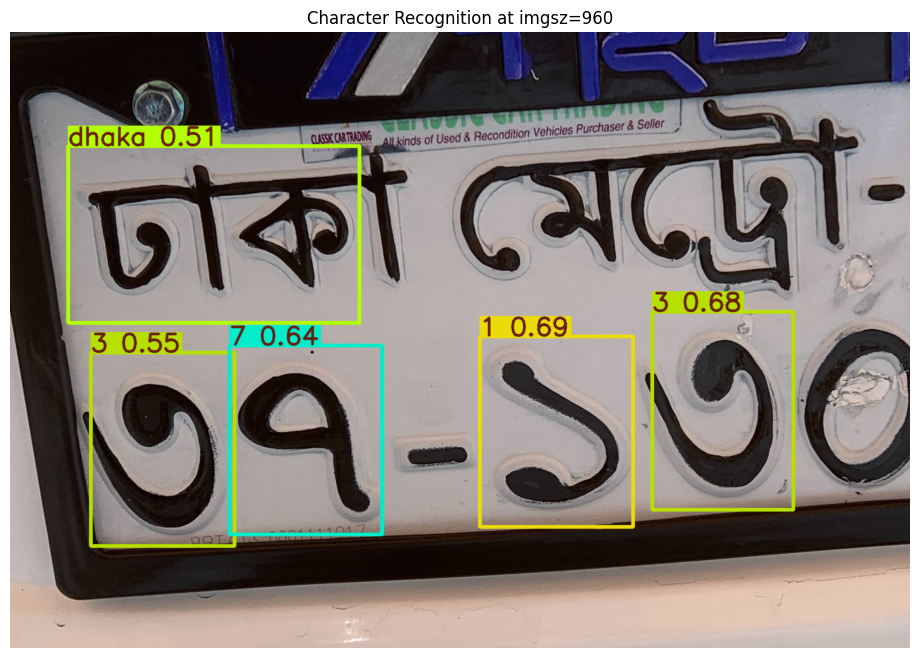

In [ ]:
character_results_960 = character_model.predict(
    source=rotated_plate_crop,
    conf=0.20,
    iou=0.5,
    imgsz=960,
    device=0
)

character_result_960 = character_results_960[0]

print("CHARACTER RECOGNITION - 960")
print("===========================")
print("Detected objects:", len(character_result_960.boxes))

for i, box in enumerate(character_result_960.boxes):

    class_id = int(box.cls[0])
    class_name = character_model.names[class_id]
    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nDetection {i+1}")
    print("Class:", class_name)
    print("Confidence:", round(confidence, 4))
    print(
        "Box:",
        [round(float(v), 1) for v in xyxy]
    )

annotated_960 = character_result_960.plot()

plt.figure(figsize=(14, 8))
plt.imshow(annotated_960)
plt.axis("off")
plt.title("Character Recognition at imgsz=960")
plt.show()

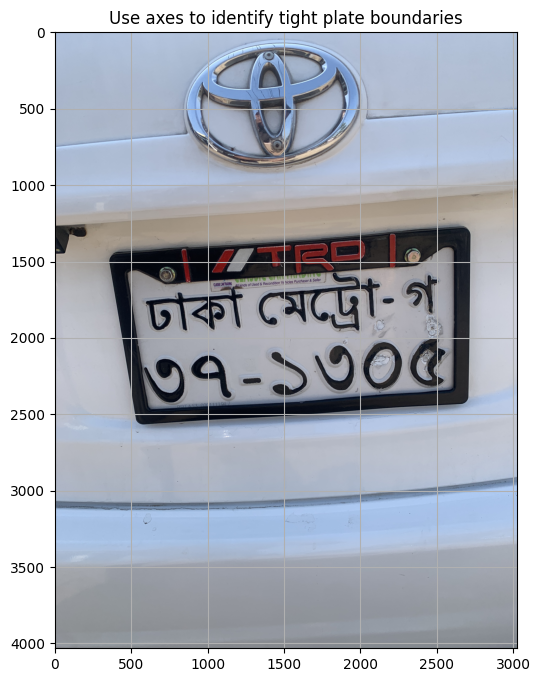

In [ ]:
plt.figure(figsize=(12, 8))
plt.imshow(rotated_vehicle_image)
plt.axis("on")
plt.grid()
plt.title("Use axes to identify tight plate boundaries")
plt.show()

TIGHT DIAGNOSTIC CROP
Crop size: (2350, 1250)


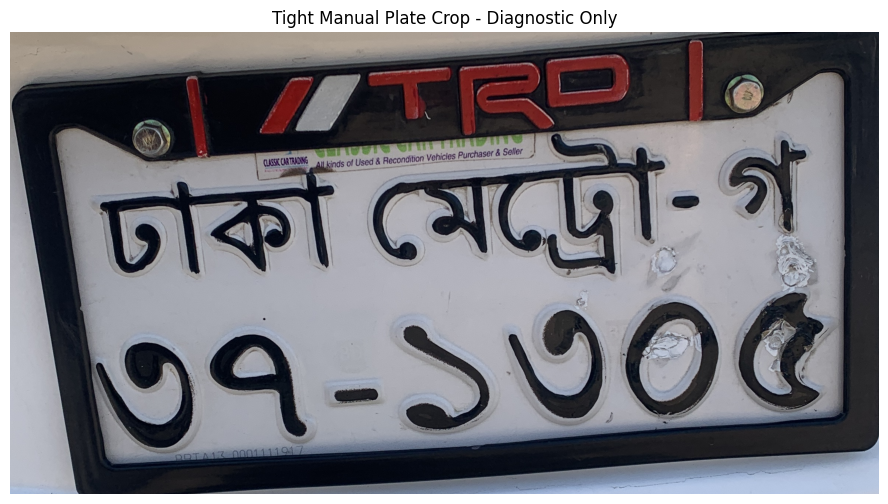

In [ ]:
tight_plate_crop = rotated_vehicle_image.crop(
    (350, 1300, 2700, 2550)
)

print("TIGHT DIAGNOSTIC CROP")
print("=====================")
print("Crop size:", tight_plate_crop.size)

plt.figure(figsize=(12, 6))
plt.imshow(tight_plate_crop)
plt.axis("off")
plt.title("Tight Manual Plate Crop - Diagnostic Only")
plt.show()


0: 352x640 1 0, 1 1, 2 3s, 1 5, 1 7, 1 dhaka, 1 ga, 1 metro, 65.4ms
Speed: 1.9ms preprocess, 65.4ms inference, 4.2ms postprocess per image at shape (1, 3, 352, 640)
TIGHT CROP CHARACTER RESULT
Detected objects: 9

Detection 1
Class: 1
Confidence: 0.9
Box: [1016.6, 732.0, 1335.9, 1135.2]

Detection 2
Class: 3
Confidence: 0.8986
Box: [1330.2, 686.7, 1645.7, 1106.1]

Detection 3
Class: metro
Confidence: 0.894
Box: [944.4, 251.0, 1796.7, 696.1]

Detection 4
Class: dhaka
Confidence: 0.8904
Box: [208.8, 346.8, 931.9, 718.0]

Detection 5
Class: 7
Confidence: 0.8851
Box: [525.4, 749.0, 836.3, 1146.2]

Detection 6
Class: 5
Confidence: 0.8762
Box: [1947.2, 656.4, 2232.6, 1092.2]

Detection 7
Class: 3
Confidence: 0.876
Box: [241.0, 767.2, 536.7, 1161.2]

Detection 8
Class: ga
Confidence: 0.81
Box: [1913.6, 247.3, 2199.3, 609.7]

Detection 9
Class: 0
Confidence: 0.7301
Box: [1640.1, 681.0, 1950.4, 1089.2]


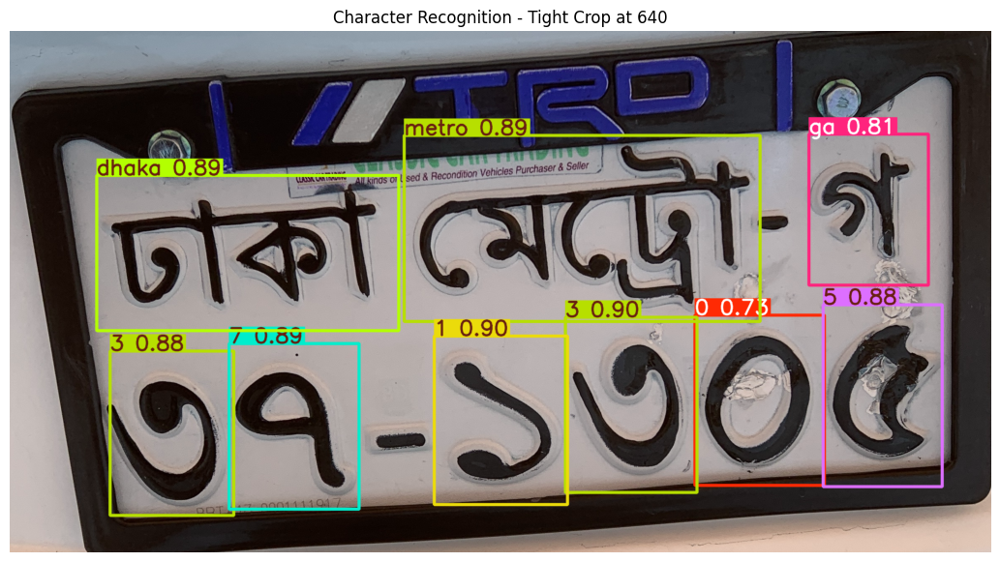

In [ ]:
tight_results = character_model.predict(
    source=tight_plate_crop,
    conf=0.20,
    iou=0.5,
    imgsz=640,
    device=0
)

tight_result = tight_results[0]

print("TIGHT CROP CHARACTER RESULT")
print("===========================")
print("Detected objects:", len(tight_result.boxes))

for i, box in enumerate(tight_result.boxes):

    class_id = int(box.cls[0])
    class_name = character_model.names[class_id]
    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nDetection {i+1}")
    print("Class:", class_name)
    print("Confidence:", round(confidence, 4))
    print(
        "Box:",
        [round(float(v), 1) for v in xyxy]
    )

tight_annotated = tight_result.plot()

plt.figure(figsize=(14, 7))
plt.imshow(tight_annotated)
plt.axis("off")
plt.title("Character Recognition - Tight Crop at 640")
plt.show()

In [ ]:
auto_w, auto_h = rotated_plate_crop.size
tight_w, tight_h = tight_plate_crop.size

auto_area = auto_w * auto_h
tight_area = tight_w * tight_h

print("CROP COMPARISON")
print("===============")

print("Automatic localization crop:")
print("Size:", rotated_plate_crop.size)
print("Area:", auto_area)

print("\nTight diagnostic crop:")
print("Size:", tight_plate_crop.size)
print("Area:", tight_area)

print(
    "\nAutomatic / Tight area ratio:",
    round(auto_area / tight_area, 3)
)

CROP COMPARISON
Automatic localization crop:
Size: (1786, 1223)
Area: 2184278

Tight diagnostic crop:
Size: (2350, 1250)
Area: 2937500

Automatic / Tight area ratio: 0.744


In [ ]:
auto_ratio = auto_w / auto_h
tight_ratio = tight_w / tight_h

print("BOUNDING BOX SHAPE COMPARISON")
print("=============================")

print(
    "Automatic crop aspect ratio:",
    round(auto_ratio, 3)
)

print(
    "Tight plate aspect ratio:",
    round(tight_ratio, 3)
)

print(
    "Width difference:",
    tight_w - auto_w,
    "pixels"
)

print(
    "Height difference:",
    tight_h - auto_h,
    "pixels"
)

BOUNDING BOX SHAPE COMPARISON
Automatic crop aspect ratio: 1.46
Tight plate aspect ratio: 1.88
Width difference: 564 pixels
Height difference: 27 pixels


EXPANDED AUTOMATIC CROP
Original box: (438, 1441, 2224, 2664)
Expanded box: (153, 1441, 2510, 2664)
Crop size: (2357, 1223)
Aspect ratio: 1.927


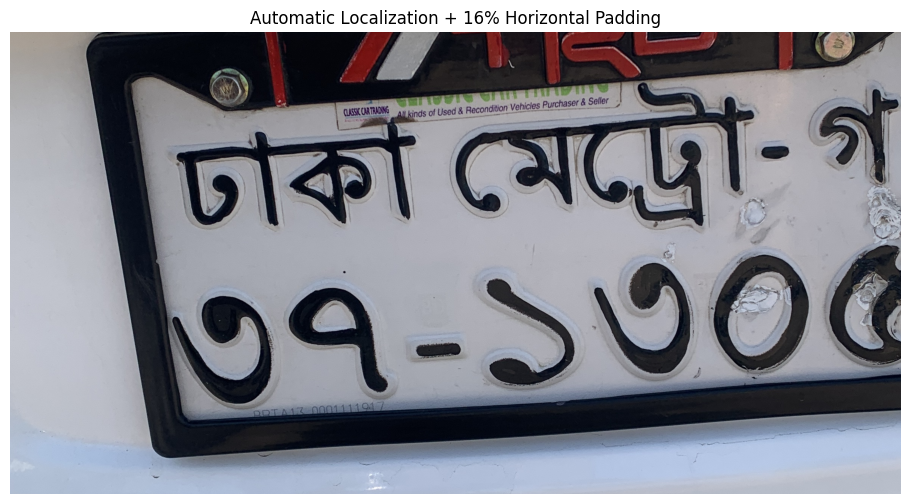

In [ ]:
x1, y1, x2, y2 = best_box.xyxy[0].cpu().numpy()

box_width = x2 - x1

horizontal_padding = 0.16 * box_width

expanded_x1 = max(
    0,
    int(x1 - horizontal_padding)
)

expanded_x2 = min(
    rotated_vehicle_image.width,
    int(x2 + horizontal_padding)
)

expanded_y1 = max(0, int(y1))
expanded_y2 = min(
    rotated_vehicle_image.height,
    int(y2)
)

expanded_plate_crop = rotated_vehicle_image.crop(
    (
        expanded_x1,
        expanded_y1,
        expanded_x2,
        expanded_y2
    )
)

print("EXPANDED AUTOMATIC CROP")
print("=======================")
print(
    "Original box:",
    (int(x1), int(y1), int(x2), int(y2))
)
print(
    "Expanded box:",
    (
        expanded_x1,
        expanded_y1,
        expanded_x2,
        expanded_y2
    )
)
print(
    "Crop size:",
    expanded_plate_crop.size
)
print(
    "Aspect ratio:",
    round(
        expanded_plate_crop.width /
        expanded_plate_crop.height,
        3
    )
)

plt.figure(figsize=(12, 6))
plt.imshow(expanded_plate_crop)
plt.axis("off")
plt.title("Automatic Localization + 16% Horizontal Padding")
plt.show()


0: 352x640 1 0, 1 1, 2 3s, 1 5, 1 7, 1 dhaka, 1 ga, 1 metro, 9.5ms
Speed: 1.9ms preprocess, 9.5ms inference, 1.6ms postprocess per image at shape (1, 3, 352, 640)
EXPANDED CROP CHARACTER RESULT
Detected objects: 9

Detection 1
Class: metro
Confidence: 0.9058
Box: [1143.0, 114.0, 1997.2, 553.7]

Detection 2
Class: dhaka
Confidence: 0.8951
Box: [404.9, 211.9, 1120.6, 580.1]

Detection 3
Class: 7
Confidence: 0.894
Box: [722.7, 617.4, 1034.8, 1007.2]

Detection 4
Class: 1
Confidence: 0.8926
Box: [1221.2, 595.3, 1529.1, 992.0]

Detection 5
Class: 3
Confidence: 0.887
Box: [1530.8, 548.3, 1838.8, 966.3]

Detection 6
Class: 3
Confidence: 0.885
Box: [436.9, 629.7, 732.0, 1015.6]

Detection 7
Class: 5
Confidence: 0.867
Box: [2148.4, 506.2, 2357.0, 950.3]

Detection 8
Class: 0
Confidence: 0.7932
Box: [1840.8, 540.6, 2149.6, 956.6]

Detection 9
Class: ga
Confidence: 0.7258
Box: [2105.5, 105.0, 2357.0, 472.9]


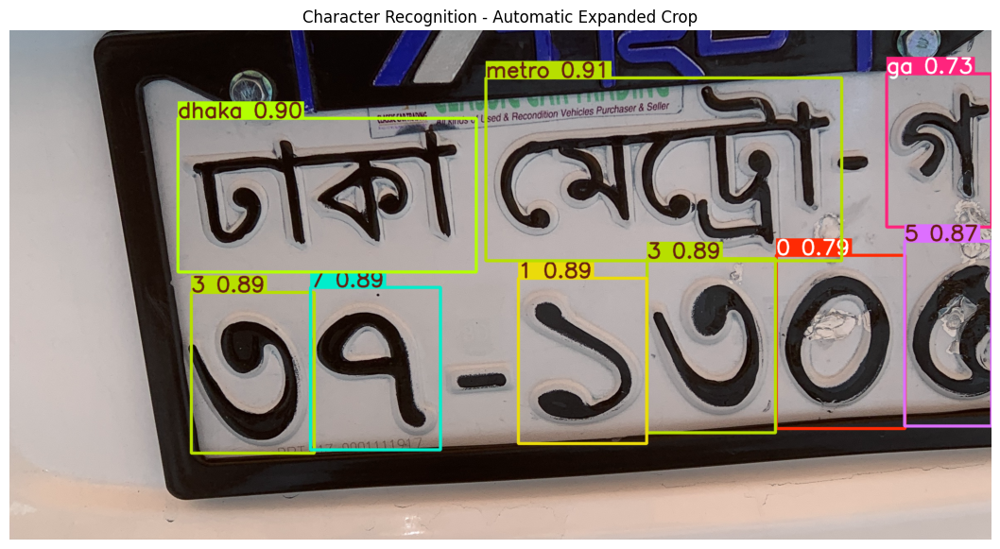

In [ ]:
expanded_results = character_model.predict(
    source=expanded_plate_crop,
    conf=0.20,
    iou=0.5,
    imgsz=640,
    device=0
)

expanded_result = expanded_results[0]

print("EXPANDED CROP CHARACTER RESULT")
print("==============================")
print("Detected objects:", len(expanded_result.boxes))

for i, box in enumerate(expanded_result.boxes):

    class_id = int(box.cls[0])
    class_name = character_model.names[class_id]
    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nDetection {i+1}")
    print("Class:", class_name)
    print("Confidence:", round(confidence, 4))
    print(
        "Box:",
        [round(float(v), 1) for v in xyxy]
    )

expanded_annotated = expanded_result.plot()

plt.figure(figsize=(14, 7))
plt.imshow(expanded_annotated)
plt.axis("off")
plt.title(
    "Character Recognition - Automatic Expanded Crop"
)
plt.show()

In [ ]:
detections = []

for box in expanded_result.boxes:

    class_id = int(box.cls[0])
    class_name = character_model.names[class_id]
    confidence = float(box.conf[0])

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    center_x = (x1 + x2) / 2
    center_y = (y1 + y2) / 2

    detections.append({
        "class": class_name,
        "confidence": confidence,
        "center_x": center_x,
        "center_y": center_y
    })

plate_height = expanded_plate_crop.height

row_threshold = plate_height * 0.48

top_row = [
    d for d in detections
    if d["center_y"] < row_threshold
]

bottom_row = [
    d for d in detections
    if d["center_y"] >= row_threshold
]

top_row.sort(
    key=lambda d: d["center_x"]
)

bottom_row.sort(
    key=lambda d: d["center_x"]
)

top_text = " ".join(
    d["class"] for d in top_row
)

bottom_text = "".join(
    d["class"] for d in bottom_row
)

print("PLATE RECONSTRUCTION")
print("====================")

print("Top row:")
print(top_text)

print("\nBottom row:")
print(bottom_text)

print("\nFinal:")
print(top_text, bottom_text)

PLATE RECONSTRUCTION
Top row:
dhaka metro ga

Bottom row:
371305

Final:
dhaka metro ga 371305


In [ ]:
from pathlib import Path
from PIL import Image

inference_dir = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/"
    "inference_tests/test_01"
)

inference_dir.mkdir(
    parents=True,
    exist_ok=True
)

expanded_plate_crop.save(
    inference_dir / "plate_crop.jpg"
)

Image.fromarray(expanded_annotated).save(
    inference_dir / "character_detection.jpg"
)

result_text = (
    f"Top row: {top_text}\n"
    f"Bottom row: {bottom_text}\n"
    f"Final: {top_text} {bottom_text}\n"
)

(
    inference_dir / "recognition.txt"
).write_text(
    result_text,
    encoding="utf-8"
)

print("TEST 01 SAVED")
print("=============")
print(inference_dir)

print(
    "\nplate_crop.jpg:",
    (inference_dir / "plate_crop.jpg").exists()
)

print(
    "character_detection.jpg:",
    (inference_dir / "character_detection.jpg").exists()
)

print(
    "recognition.txt:",
    (inference_dir / "recognition.txt").exists()
)

print("\nRecognized plate:")
print(top_text)
print(bottom_text)

TEST 01 SAVED
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/test_01

plate_crop.jpg: True
character_detection.jpg: True
recognition.txt: True

Recognized plate:
dhaka metro ga
371305


Saving images.jfif to images (1).jfif
TEST IMAGE 02
File: images (1).jfif
Size: (275, 183)
Mode: RGB


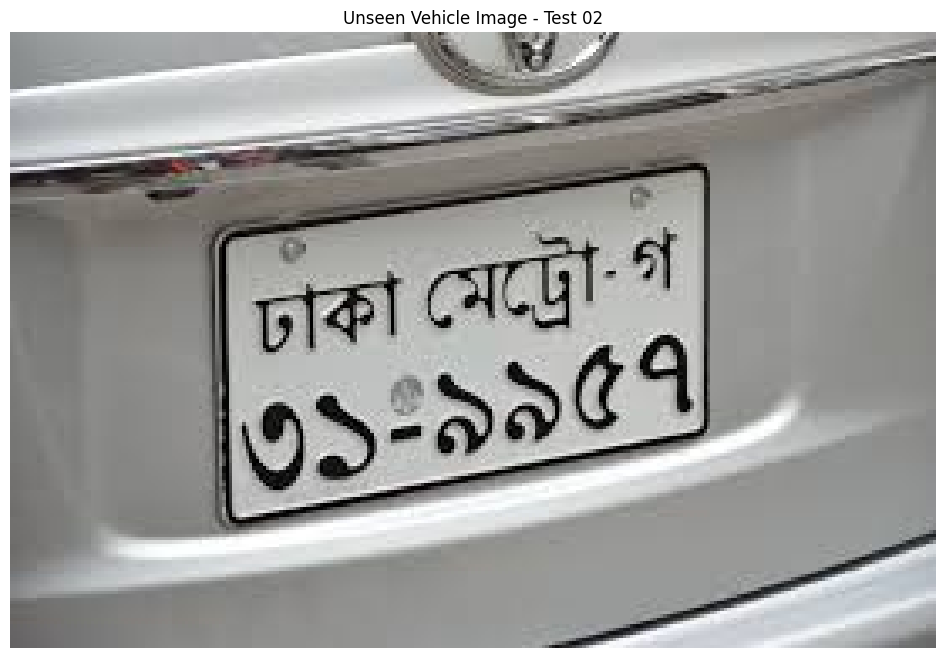

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

uploaded_02 = files.upload()

test02_path = Path(
    next(iter(uploaded_02.keys()))
)

test02_image = Image.open(test02_path).convert("RGB")

print("TEST IMAGE 02")
print("=============")
print("File:", test02_path)
print("Size:", test02_image.size)
print("Mode:", test02_image.mode)

plt.figure(figsize=(12, 8))
plt.imshow(test02_image)
plt.axis("off")
plt.title("Unseen Vehicle Image - Test 02")
plt.show()


0: 448x640 2 license_plates, 104.3ms
Speed: 8.6ms preprocess, 104.3ms inference, 14.2ms postprocess per image at shape (1, 3, 448, 640)
TEST 02 LOCALIZATION
Detected plates: 2

Plate 1
Confidence: 0.603
Box: [58.0, 50.0, 163.0, 151.0]

Plate 2
Confidence: 0.3372
Box: [82.7, 39.3, 214.4, 138.6]


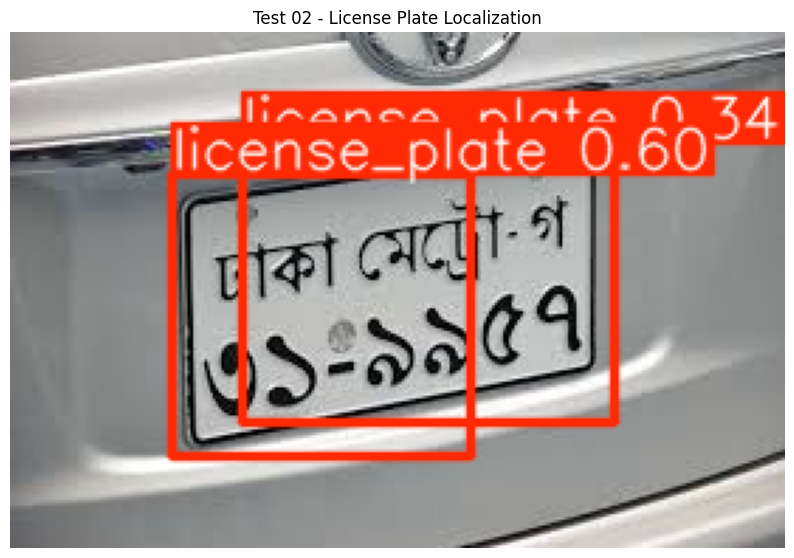

In [ ]:
test02_loc_results = localization_model.predict(
    source=test02_image,
    conf=0.25,
    iou=0.5,
    imgsz=640,
    device=0
)

test02_loc_result = test02_loc_results[0]

print("TEST 02 LOCALIZATION")
print("====================")
print("Detected plates:", len(test02_loc_result.boxes))

for i, box in enumerate(test02_loc_result.boxes):

    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nPlate {i+1}")
    print("Confidence:", round(confidence, 4))
    print(
        "Box:",
        [round(float(v), 1) for v in xyxy]
    )

annotated_test02 = test02_loc_result.plot()

plt.figure(figsize=(10, 7))
plt.imshow(annotated_test02)
plt.axis("off")
plt.title("Test 02 - License Plate Localization")
plt.show()

TEST 02 BEST DETECTION
Confidence: 0.603
Box: (57, 50, 163, 150)
Crop size: (106, 100)
Aspect ratio: 1.06


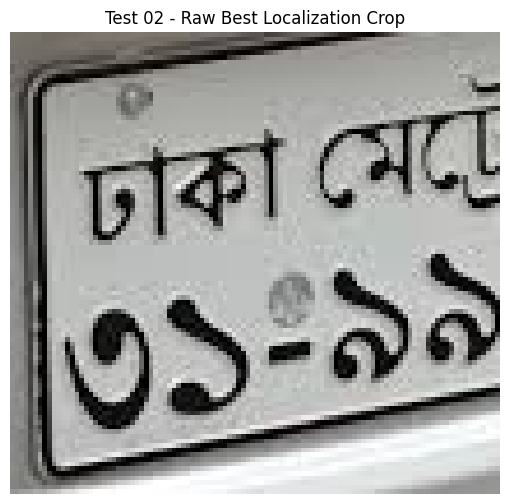

In [ ]:
if len(test02_loc_result.boxes) == 0:
    print("❌ No plate detected")

else:
    test02_best_index = int(
        test02_loc_result.boxes.conf.argmax()
    )

    test02_best_box = test02_loc_result.boxes[
        test02_best_index
    ]

    x1, y1, x2, y2 = (
        test02_best_box.xyxy[0].cpu().numpy()
    )

    confidence = float(
        test02_best_box.conf[0]
    )

    x1 = max(0, int(x1))
    y1 = max(0, int(y1))
    x2 = min(test02_image.width, int(x2))
    y2 = min(test02_image.height, int(y2))

    test02_raw_crop = test02_image.crop(
        (x1, y1, x2, y2)
    )

    print("TEST 02 BEST DETECTION")
    print("======================")
    print("Confidence:", round(confidence, 4))
    print("Box:", (x1, y1, x2, y2))
    print("Crop size:", test02_raw_crop.size)

    print(
        "Aspect ratio:",
        round(
            test02_raw_crop.width /
            test02_raw_crop.height,
            3
        )
    )

    plt.figure(figsize=(10, 6))
    plt.imshow(test02_raw_crop)
    plt.axis("off")
    plt.title("Test 02 - Raw Best Localization Crop")
    plt.show()

TEST 02 EXPANDED CROP
Original box: (57, 50, 163, 150)
Expanded box: (41, 50, 179, 150)
Crop size: (138, 100)
Aspect ratio: 1.38


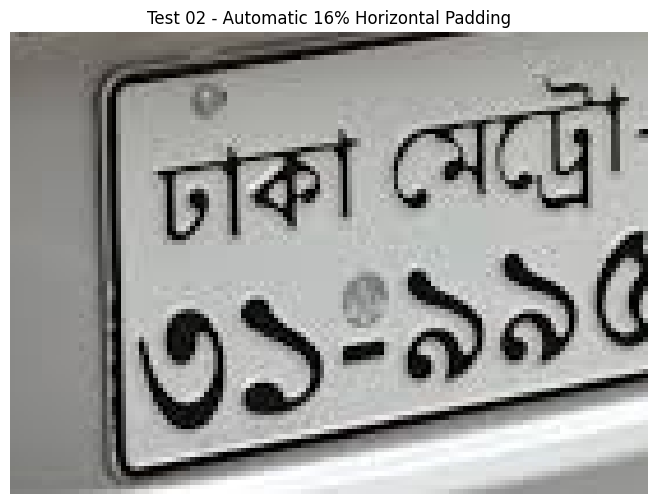

In [ ]:
x1, y1, x2, y2 = (
    test02_best_box.xyxy[0].cpu().numpy()
)

box_width = x2 - x1

padding = 0.16 * box_width

px1 = max(
    0,
    int(x1 - padding)
)

px2 = min(
    test02_image.width,
    int(x2 + padding)
)

py1 = max(0, int(y1))
py2 = min(
    test02_image.height,
    int(y2)
)

test02_expanded_crop = test02_image.crop(
    (px1, py1, px2, py2)
)

print("TEST 02 EXPANDED CROP")
print("=====================")

print(
    "Original box:",
    (int(x1), int(y1), int(x2), int(y2))
)

print(
    "Expanded box:",
    (px1, py1, px2, py2)
)

print(
    "Crop size:",
    test02_expanded_crop.size
)

print(
    "Aspect ratio:",
    round(
        test02_expanded_crop.width /
        test02_expanded_crop.height,
        3
    )
)

plt.figure(figsize=(10, 6))
plt.imshow(test02_expanded_crop)
plt.axis("off")
plt.title("Test 02 - Automatic 16% Horizontal Padding")
plt.show()

TEST 02 LOCALIZATION CANDIDATES

Detection 1
Confidence: 0.603
Box: (57, 50, 163, 150)
Size: (106, 100)
Aspect ratio: 1.06

Detection 2
Confidence: 0.3372
Box: (82, 39, 214, 138)
Size: (132, 99)
Aspect ratio: 1.333


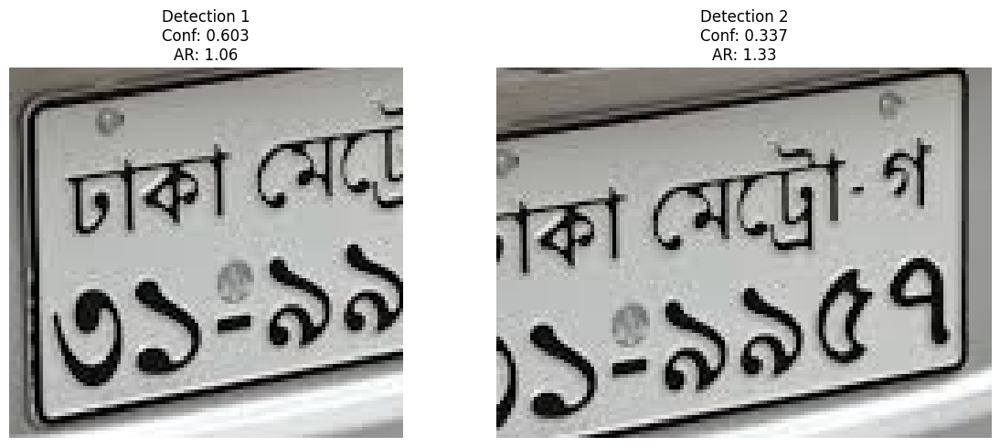

In [ ]:
import matplotlib.pyplot as plt

boxes = test02_loc_result.boxes

fig, axes = plt.subplots(
    1,
    len(boxes),
    figsize=(6 * len(boxes), 5)
)

if len(boxes) == 1:
    axes = [axes]

print("TEST 02 LOCALIZATION CANDIDATES")
print("===============================")

for i, box in enumerate(boxes):

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    x1 = max(0, int(x1))
    y1 = max(0, int(y1))
    x2 = min(test02_image.width, int(x2))
    y2 = min(test02_image.height, int(y2))

    conf = float(box.conf[0])

    crop = test02_image.crop(
        (x1, y1, x2, y2)
    )

    aspect = crop.width / crop.height

    print(f"\nDetection {i+1}")
    print("Confidence:", round(conf, 4))
    print("Box:", (x1, y1, x2, y2))
    print("Size:", crop.size)
    print("Aspect ratio:", round(aspect, 3))

    axes[i].imshow(crop)
    axes[i].axis("off")
    axes[i].set_title(
        f"Detection {i+1}\n"
        f"Conf: {conf:.3f}\n"
        f"AR: {aspect:.2f}"
    )

plt.tight_layout()
plt.show()

TEST 02 MERGED LOCALIZATION
Merged box: (57, 39, 214, 150)
Crop size: (157, 111)
Aspect ratio: 1.414


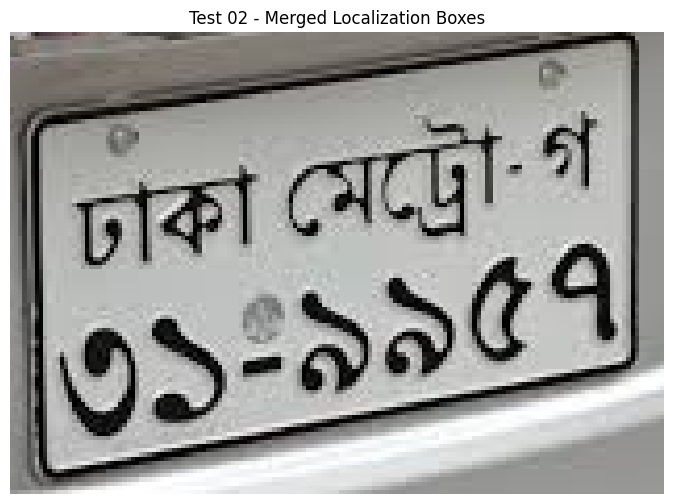

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

all_boxes = (
    test02_loc_result.boxes.xyxy
    .cpu()
    .numpy()
)

merged_x1 = int(
    max(0, np.min(all_boxes[:, 0]))
)

merged_y1 = int(
    max(0, np.min(all_boxes[:, 1]))
)

merged_x2 = int(
    min(
        test02_image.width,
        np.max(all_boxes[:, 2])
    )
)

merged_y2 = int(
    min(
        test02_image.height,
        np.max(all_boxes[:, 3])
    )
)

test02_merged_crop = test02_image.crop(
    (
        merged_x1,
        merged_y1,
        merged_x2,
        merged_y2
    )
)

print("TEST 02 MERGED LOCALIZATION")
print("===========================")

print(
    "Merged box:",
    (
        merged_x1,
        merged_y1,
        merged_x2,
        merged_y2
    )
)

print(
    "Crop size:",
    test02_merged_crop.size
)

print(
    "Aspect ratio:",
    round(
        test02_merged_crop.width /
        test02_merged_crop.height,
        3
    )
)

plt.figure(figsize=(10, 6))
plt.imshow(test02_merged_crop)
plt.axis("off")
plt.title("Test 02 - Merged Localization Boxes")
plt.show()


0: 480x640 1 1, 1 3, 1 5, 1 7, 2 9s, 1 dhaka, 1 ga, 1 metro, 50.8ms
Speed: 2.1ms preprocess, 50.8ms inference, 4.4ms postprocess per image at shape (1, 3, 480, 640)
TEST 02 CHARACTER RECOGNITION
Detected objects: 9

Detection 1
Class: metro
Confidence: 0.9009
Box: [64.4, 18.9, 121.0, 53.9]

Detection 2
Class: 1
Confidence: 0.8979
Box: [32.0, 63.9, 54.6, 98.5]

Detection 3
Class: dhaka
Confidence: 0.8941
Box: [12.4, 31.4, 62.8, 59.5]

Detection 4
Class: 9
Confidence: 0.8896
Box: [66.9, 57.8, 89.0, 92.5]

Detection 5
Class: 7
Confidence: 0.8888
Box: [128.1, 46.8, 148.7, 80.1]

Detection 6
Class: 9
Confidence: 0.8887
Box: [87.9, 54.2, 109.5, 89.7]

Detection 7
Class: 5
Confidence: 0.888
Box: [109.1, 50.7, 128.2, 85.0]

Detection 8
Class: 3
Confidence: 0.8822
Box: [9.8, 66.3, 33.3, 100.3]

Detection 9
Class: ga
Confidence: 0.8633
Box: [126.3, 17.2, 144.1, 43.6]


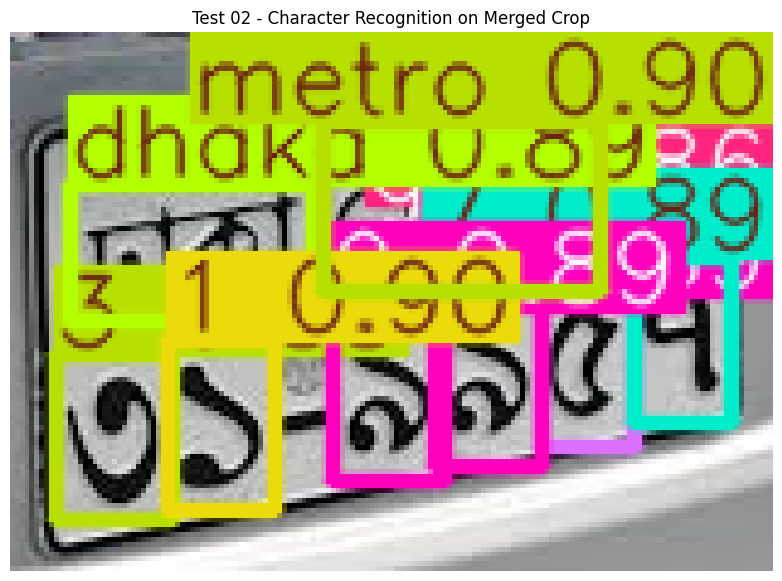

In [ ]:
test02_char_results = character_model.predict(
    source=test02_merged_crop,
    conf=0.20,
    iou=0.5,
    imgsz=640,
    device=0
)

test02_char_result = test02_char_results[0]

print("TEST 02 CHARACTER RECOGNITION")
print("=============================")
print(
    "Detected objects:",
    len(test02_char_result.boxes)
)

for i, box in enumerate(test02_char_result.boxes):

    class_id = int(box.cls[0])
    class_name = character_model.names[class_id]
    confidence = float(box.conf[0])

    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nDetection {i+1}")
    print("Class:", class_name)
    print(
        "Confidence:",
        round(confidence, 4)
    )
    print(
        "Box:",
        [
            round(float(v), 1)
            for v in xyxy
        ]
    )

annotated = test02_char_result.plot()

plt.figure(figsize=(12, 7))
plt.imshow(annotated)
plt.axis("off")
plt.title(
    "Test 02 - Character Recognition on Merged Crop"
)
plt.show()

In [ ]:
test02_detections = []

for box in test02_char_result.boxes:

    class_id = int(box.cls[0])
    class_name = character_model.names[class_id]
    confidence = float(box.conf[0])

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    center_x = (x1 + x2) / 2
    center_y = (y1 + y2) / 2

    test02_detections.append({
        "class": class_name,
        "confidence": confidence,
        "center_x": center_x,
        "center_y": center_y
    })

plate_height = test02_merged_crop.height

row_threshold = plate_height * 0.48

top_row = [
    d for d in test02_detections
    if d["center_y"] < row_threshold
]

bottom_row = [
    d for d in test02_detections
    if d["center_y"] >= row_threshold
]

top_row.sort(
    key=lambda d: d["center_x"]
)

bottom_row.sort(
    key=lambda d: d["center_x"]
)

top_text_02 = " ".join(
    d["class"] for d in top_row
)

bottom_text_02 = "".join(
    d["class"] for d in bottom_row
)

print("TEST 02 PLATE RECONSTRUCTION")
print("============================")

print("\nTop row detections:")
for d in top_row:
    print(
        d["class"],
        "-",
        round(d["confidence"], 3)
    )

print("\nBottom row detections:")
for d in bottom_row:
    print(
        d["class"],
        "-",
        round(d["confidence"], 3)
    )

print("\nRECONSTRUCTED PLATE")
print("===================")
print(top_text_02)
print(bottom_text_02)

TEST 02 PLATE RECONSTRUCTION

Top row detections:
dhaka - 0.894
metro - 0.901
ga - 0.863

Bottom row detections:
3 - 0.882
1 - 0.898
9 - 0.89
9 - 0.889
5 - 0.888
7 - 0.889

RECONSTRUCTED PLATE
dhaka metro ga
319957


In [ ]:
from pathlib import Path
from PIL import Image

test02_dir = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/"
    "inference_tests/test_02"
)

test02_dir.mkdir(
    parents=True,
    exist_ok=True
)

test02_merged_crop.save(
    test02_dir / "plate_crop.jpg"
)

Image.fromarray(annotated).save(
    test02_dir / "character_detection.jpg"
)

result_text_02 = (
    f"Top row: {top_text_02}\n"
    f"Bottom row: {bottom_text_02}\n"
    f"Final: {top_text_02} {bottom_text_02}\n"
)

(
    test02_dir / "recognition.txt"
).write_text(
    result_text_02,
    encoding="utf-8"
)

print("TEST 02 SAVED")
print("=============")
print(test02_dir)

print(
    "\nplate_crop.jpg:",
    (test02_dir / "plate_crop.jpg").exists()
)

print(
    "character_detection.jpg:",
    (test02_dir / "character_detection.jpg").exists()
)

print(
    "recognition.txt:",
    (test02_dir / "recognition.txt").exists()
)

print("\nRecognized plate:")
print(top_text_02)
print(bottom_text_02)

TEST 02 SAVED
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/test_02

plate_crop.jpg: True
character_detection.jpg: True
recognition.txt: True

Recognized plate:
dhaka metro ga
319957


Saving images (1).jpg to images (1).jpg
TEST IMAGE 03
File: images (1).jpg
Size: (192, 140)
Mode: RGB


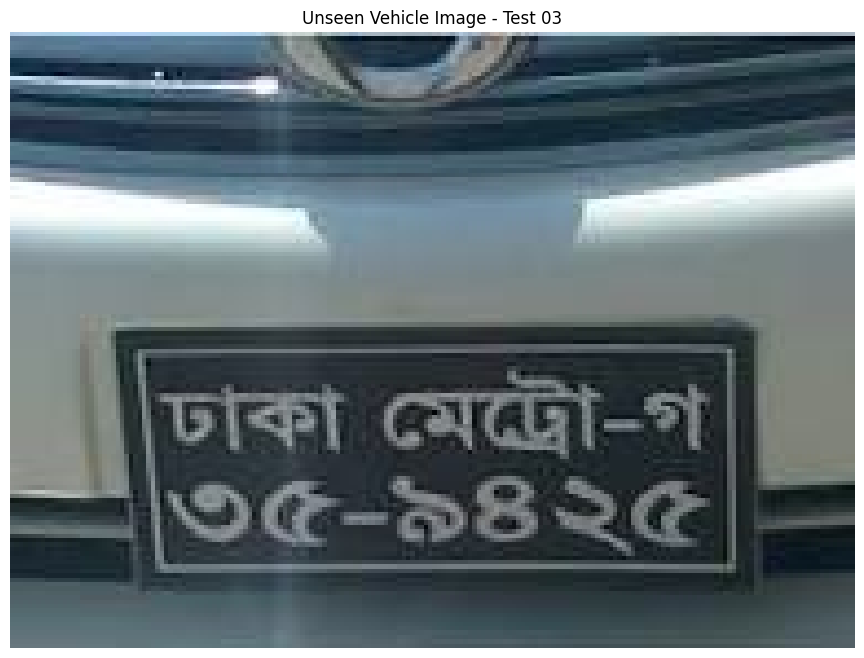

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

uploaded_03 = files.upload()

test03_path = Path(
    next(iter(uploaded_03.keys()))
)

test03_image = Image.open(test03_path).convert("RGB")

print("TEST IMAGE 03")
print("=============")
print("File:", test03_path)
print("Size:", test03_image.size)
print("Mode:", test03_image.mode)

plt.figure(figsize=(12, 8))
plt.imshow(test03_image)
plt.axis("off")
plt.title("Unseen Vehicle Image - Test 03")
plt.show()


0: 480x640 (no detections), 17.3ms
Speed: 2.4ms preprocess, 17.3ms inference, 0.9ms postprocess per image at shape (1, 3, 480, 640)
TEST 03 LOCALIZATION
Detected plates: 0


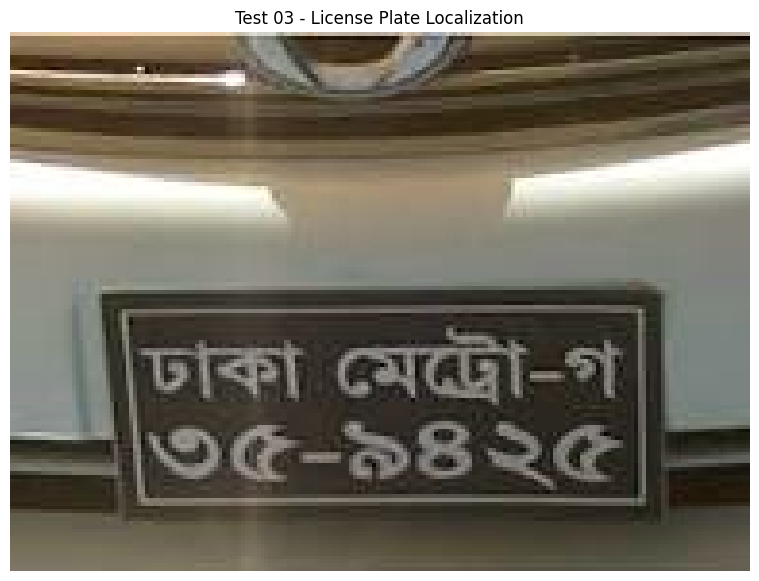

In [ ]:
test03_loc_results = localization_model.predict(
    source=test03_image,
    conf=0.25,
    iou=0.5,
    imgsz=640,
    device=0
)

test03_loc_result = test03_loc_results[0]

print("TEST 03 LOCALIZATION")
print("====================")
print(
    "Detected plates:",
    len(test03_loc_result.boxes)
)

for i, box in enumerate(test03_loc_result.boxes):

    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nDetection {i+1}")
    print(
        "Confidence:",
        round(confidence, 4)
    )
    print(
        "Box:",
        [
            round(float(v), 1)
            for v in xyxy
        ]
    )

annotated_test03 = test03_loc_result.plot()

plt.figure(figsize=(10, 7))
plt.imshow(annotated_test03)
plt.axis("off")
plt.title(
    "Test 03 - License Plate Localization"
)
plt.show()


0: 480x640 (no detections), 60.0ms
Speed: 9.9ms preprocess, 60.0ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)
TEST 03 LOW-CONFIDENCE DIAGNOSTIC
Detected candidates: 0


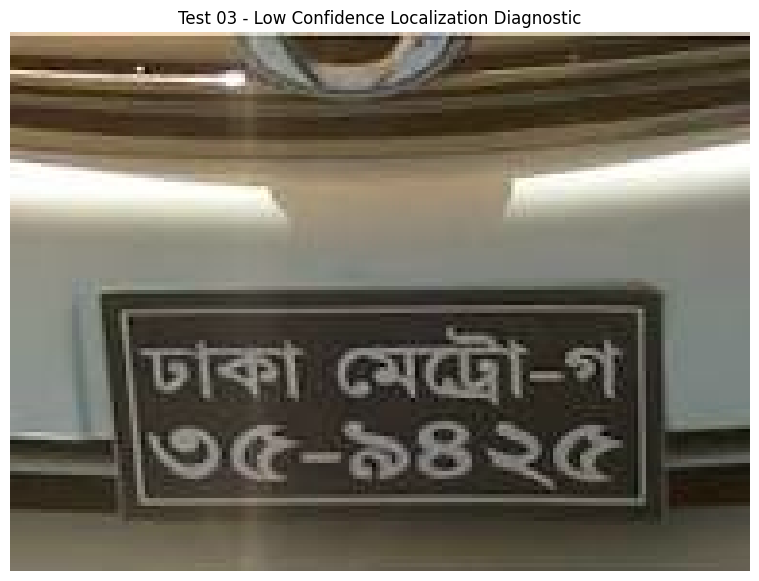

In [ ]:
test03_low_results = localization_model.predict(
    source=test03_image,
    conf=0.05,
    iou=0.5,
    imgsz=640,
    device=0
)

test03_low_result = test03_low_results[0]

print("TEST 03 LOW-CONFIDENCE DIAGNOSTIC")
print("=================================")
print(
    "Detected candidates:",
    len(test03_low_result.boxes)
)

for i, box in enumerate(test03_low_result.boxes):

    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nCandidate {i+1}")
    print(
        "Confidence:",
        round(confidence, 4)
    )
    print(
        "Box:",
        [
            round(float(v), 1)
            for v in xyxy
        ]
    )

annotated_test03_low = test03_low_result.plot()

plt.figure(figsize=(10, 7))
plt.imshow(annotated_test03_low)
plt.axis("off")
plt.title(
    "Test 03 - Low Confidence Localization Diagnostic"
)
plt.show()

TEST 03 UPSCALE
Original size: (192, 140)
Upscaled size: (768, 560)

0: 480x640 (no detections), 42.1ms
Speed: 7.9ms preprocess, 42.1ms inference, 5.0ms postprocess per image at shape (1, 3, 480, 640)

LOCALIZATION AFTER UPSCALING
Detected candidates: 0


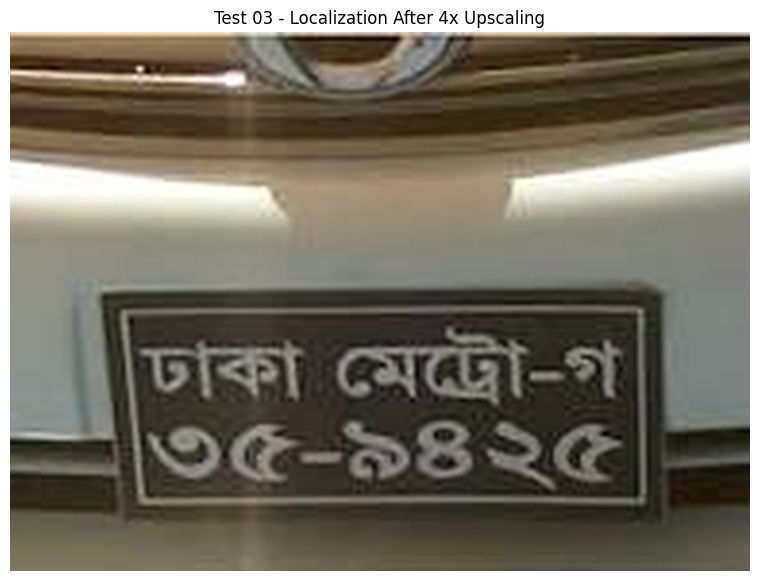

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

scale = 4

test03_upscaled = test03_image.resize(
    (
        test03_image.width * scale,
        test03_image.height * scale
    ),
    Image.Resampling.LANCZOS
)

print("TEST 03 UPSCALE")
print("================")
print("Original size:", test03_image.size)
print("Upscaled size:", test03_upscaled.size)

test03_up_results = localization_model.predict(
    source=test03_upscaled,
    conf=0.05,
    iou=0.5,
    imgsz=640,
    device=0
)

test03_up_result = test03_up_results[0]

print("\nLOCALIZATION AFTER UPSCALING")
print("============================")
print(
    "Detected candidates:",
    len(test03_up_result.boxes)
)

for i, box in enumerate(test03_up_result.boxes):

    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nCandidate {i+1}")
    print(
        "Confidence:",
        round(confidence, 4)
    )
    print(
        "Box:",
        [
            round(float(v), 1)
            for v in xyxy
        ]
    )

annotated_test03_up = test03_up_result.plot()

plt.figure(figsize=(10, 7))
plt.imshow(annotated_test03_up)
plt.axis("off")
plt.title("Test 03 - Localization After 4x Upscaling")
plt.show()

TEST 03 MANUAL DIAGNOSTIC CROP
Crop size: (116, 61)


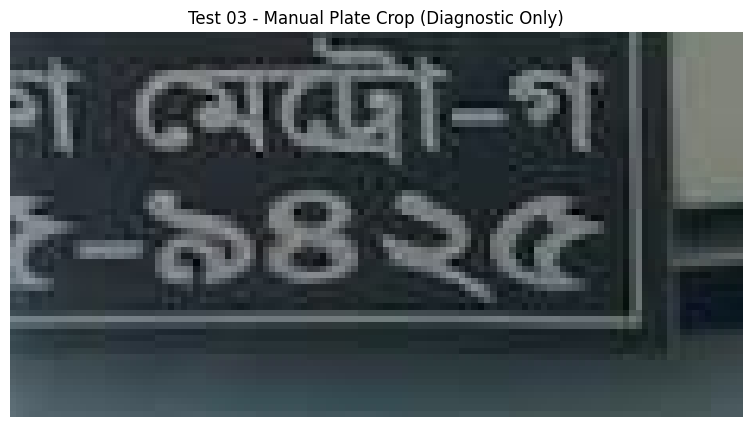

In [ ]:
test03_manual_crop = test03_image.crop(
    (65, 76, 181, 137)
)

print("TEST 03 MANUAL DIAGNOSTIC CROP")
print("==============================")
print("Crop size:", test03_manual_crop.size)

plt.figure(figsize=(10, 5))
plt.imshow(test03_manual_crop)
plt.axis("off")
plt.title("Test 03 - Manual Plate Crop (Diagnostic Only)")
plt.show()


0: 352x640 3 1s, 1 2, 1 4, 2 5s, 2 9s, 1 ba, 1 dhaka, 2 metros, 48.4ms
Speed: 7.7ms preprocess, 48.4ms inference, 8.5ms postprocess per image at shape (1, 3, 352, 640)
TEST 03 CHARACTER DIAGNOSTIC
Detected objects: 13

Detection 1
Class: 5
Confidence: 0.8415
Box: [74.7, 23.3, 86.8, 42.6]

Detection 2
Class: 1
Confidence: 0.649
Box: [56.6, 22.3, 75.7, 44.5]

Detection 3
Class: 9
Confidence: 0.6024
Box: [20.9, 23.1, 40.4, 44.1]

Detection 4
Class: metro
Confidence: 0.5566
Box: [18.6, 2.3, 68.4, 23.4]

Detection 5
Class: 1
Confidence: 0.4746
Box: [39.5, 22.5, 57.1, 43.7]

Detection 6
Class: dhaka
Confidence: 0.3655
Box: [0.0, 2.6, 16.7, 22.9]

Detection 7
Class: metro
Confidence: 0.331
Box: [0.0, 2.5, 16.4, 22.9]

Detection 8
Class: ba
Confidence: 0.2872
Box: [79.4, 5.0, 90.9, 21.2]

Detection 9
Class: 9
Confidence: 0.2663
Box: [0.6, 24.4, 12.3, 43.3]

Detection 10
Class: 5
Confidence: 0.1853
Box: [0.0, 23.6, 2.4, 43.8]

Detection 11
Class: 1
Confidence: 0.1595
Box: [0.3, 24.4, 12.4, 43.

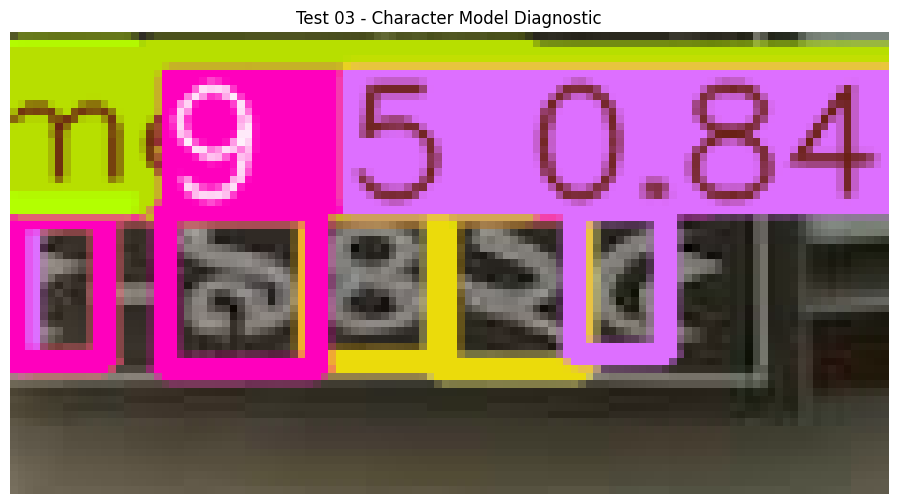

In [ ]:
test03_char_results = character_model.predict(
    source=test03_manual_crop,
    conf=0.10,
    iou=0.5,
    imgsz=640,
    device=0
)

test03_char_result = test03_char_results[0]

print("TEST 03 CHARACTER DIAGNOSTIC")
print("============================")
print(
    "Detected objects:",
    len(test03_char_result.boxes)
)

for i, box in enumerate(test03_char_result.boxes):

    class_id = int(box.cls[0])
    class_name = character_model.names[class_id]
    confidence = float(box.conf[0])

    xyxy = box.xyxy[0].cpu().numpy()

    print(f"\nDetection {i+1}")
    print("Class:", class_name)
    print(
        "Confidence:",
        round(confidence, 4)
    )
    print(
        "Box:",
        [
            round(float(v), 1)
            for v in xyxy
        ]
    )

annotated_test03_char = test03_char_result.plot()

plt.figure(figsize=(12, 6))
plt.imshow(annotated_test03_char)
plt.axis("off")
plt.title(
    "Test 03 - Character Model Diagnostic"
)
plt.show()

In [ ]:
from pathlib import Path
from PIL import Image

test03_dir = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/"
    "inference_tests/test_03_failure"
)

test03_dir.mkdir(
    parents=True,
    exist_ok=True
)

test03_image.save(
    test03_dir / "original_image.jpg"
)

test03_manual_crop.save(
    test03_dir / "manual_diagnostic_crop.jpg"
)

Image.fromarray(
    annotated_test03_char
).save(
    test03_dir / "character_diagnostic.jpg"
)

diagnostic_text = """TEST 03 RESULT

Localization:
No detection at conf=0.25.
No detection at conf=0.05.
No detection after 4x upscaling.

Character recognition on manual diagnostic crop:
Unstable / conflicting detections.

Conclusion:
Test 03 failed at both localization and character-recognition stages.
"""

(
    test03_dir / "diagnostic.txt"
).write_text(
    diagnostic_text,
    encoding="utf-8"
)

print("TEST 03 FAILURE CASE SAVED")
print("==========================")
print(test03_dir)

print(
    "\noriginal_image.jpg:",
    (test03_dir / "original_image.jpg").exists()
)

print(
    "manual_diagnostic_crop.jpg:",
    (test03_dir / "manual_diagnostic_crop.jpg").exists()
)

print(
    "character_diagnostic.jpg:",
    (test03_dir / "character_diagnostic.jpg").exists()
)

print(
    "diagnostic.txt:",
    (test03_dir / "diagnostic.txt").exists()
)

TEST 03 FAILURE CASE SAVED
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/test_03_failure

original_image.jpg: True
manual_diagnostic_crop.jpg: True
character_diagnostic.jpg: True
diagnostic.txt: True


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [ ]:
from pathlib import Path

project_drive = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

localization_best = (
    project_drive
    / "training_results"
    / "localization_yolo11n"
    / "weights"
    / "best.pt"
)

character_best = (
    project_drive
    / "training_results"
    / "character_yolo11n"
    / "weights"
    / "best.pt"
)

print("MODEL CHECK")
print("===========")

print("\nLocalization model:")
print(localization_best)
print("Exists:", localization_best.exists())

print("\nCharacter model:")
print(character_best)
print("Exists:", character_best.exists())

MODEL CHECK

Localization model:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_yolo11n/weights/best.pt
Exists: True

Character model:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/character_yolo11n/weights/best.pt
Exists: True


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 6.6 MB/s eta 0:00:00


In [ ]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("Ultralytics ready.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.176
Ultralytics ready.


In [ ]:
from ultralytics import YOLO

localization_model = YOLO(str(localization_best))
character_model = YOLO(str(character_best))

print("MODELS LOADED")
print("=============")
print("Localization model: READY")
print("Character model: READY")
print("Device: CPU")

MODELS LOADED
Localization model: READY
Character model: READY
Device: CPU


Saving images (2).jfif to images (2).jfif
TEST IMAGE 04
File: images (2).jfif
Size: (547, 365)
Mode: RGB


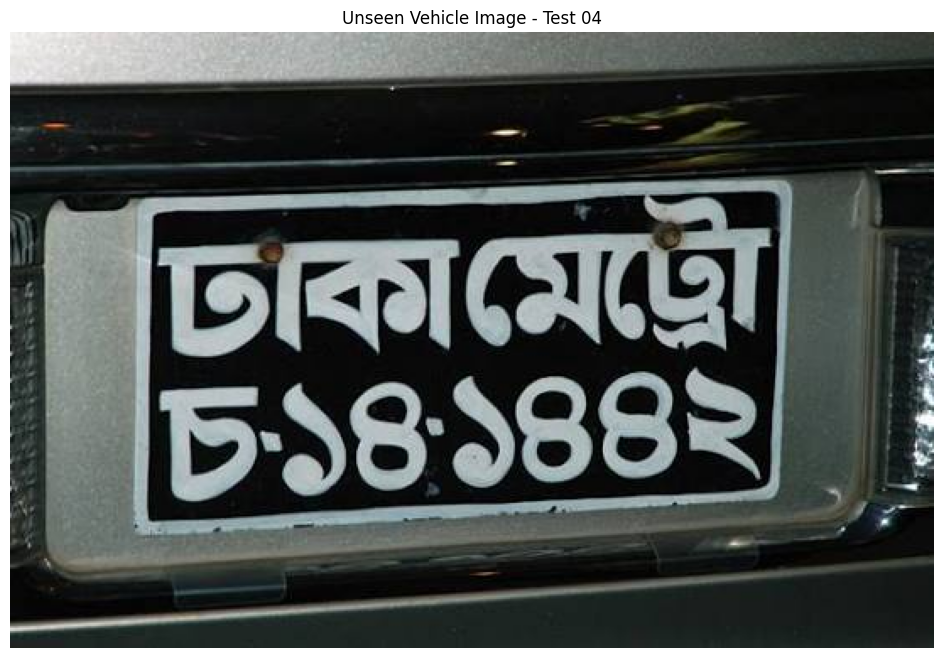

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

uploaded_04 = files.upload()

test04_path = Path(
    next(iter(uploaded_04.keys()))
)

test04_image = Image.open(
    test04_path
).convert("RGB")

print("TEST IMAGE 04")
print("=============")
print("File:", test04_path)
print("Size:", test04_image.size)
print("Mode:", test04_image.mode)

plt.figure(figsize=(12, 8))
plt.imshow(test04_image)
plt.axis("off")
plt.title("Unseen Vehicle Image - Test 04")
plt.show()

TEST 04 - LOCALIZATION
Number of detections: 0


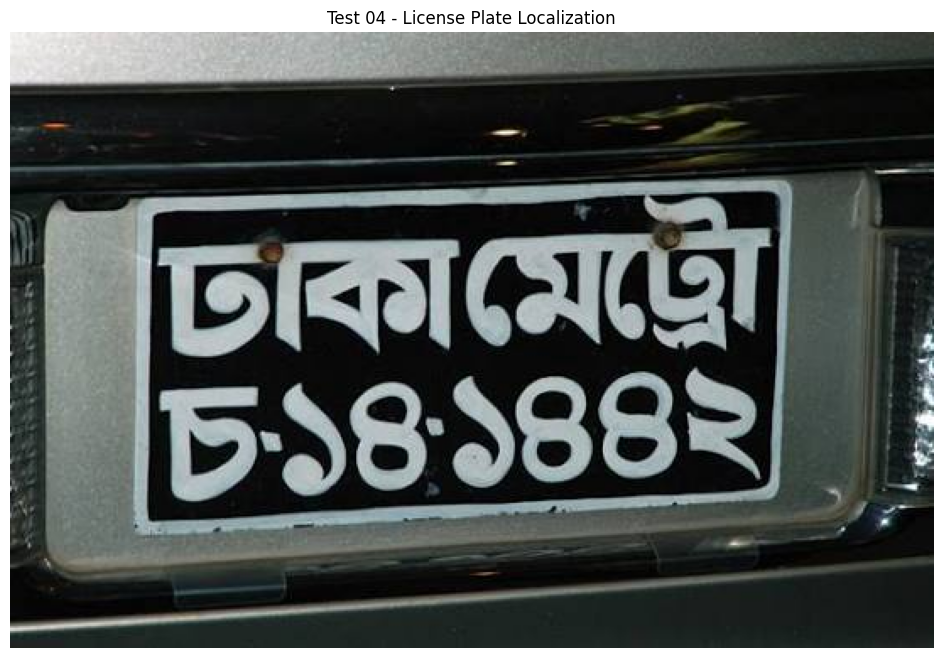

In [ ]:
import matplotlib.pyplot as plt

test04_loc_results = localization_model.predict(
    source=test04_image,
    conf=0.25,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

result = test04_loc_results[0]

print("TEST 04 - LOCALIZATION")
print("======================")

print("Number of detections:", len(result.boxes))

if len(result.boxes) > 0:
    for i, box in enumerate(result.boxes):
        coords = box.xyxy[0].cpu().numpy()
        confidence = float(box.conf[0].cpu())

        print(
            f"Detection {i+1}: "
            f"box={coords.round(1)}, "
            f"confidence={confidence:.4f}"
        )

annotated = result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 04 - License Plate Localization")
plt.show()

TEST 04 - LOW CONFIDENCE CHECK
Number of detections: 0


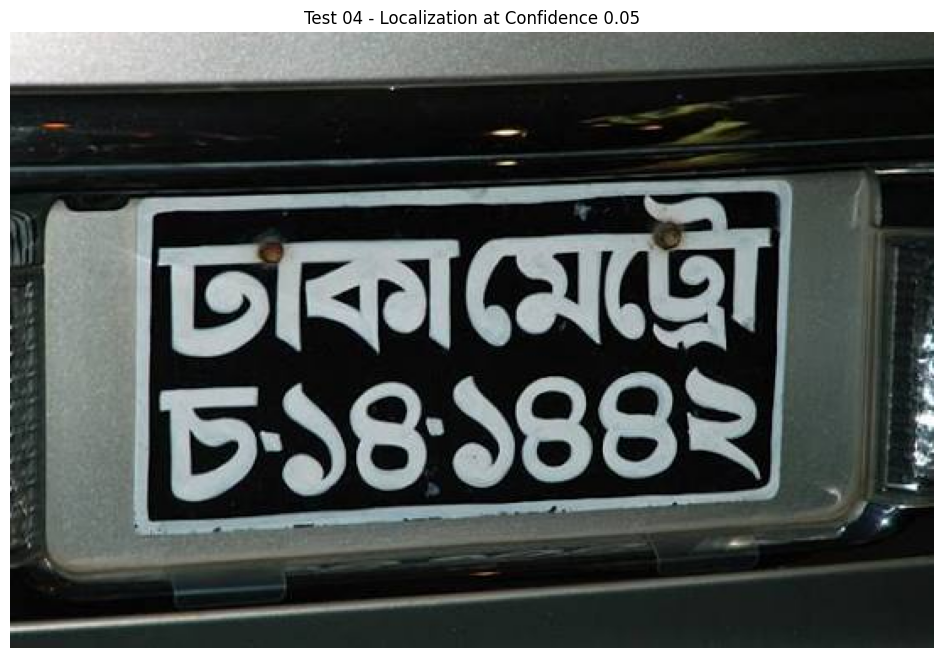

In [ ]:
test04_low_results = localization_model.predict(
    source=test04_image,
    conf=0.05,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

low_result = test04_low_results[0]

print("TEST 04 - LOW CONFIDENCE CHECK")
print("==============================")
print("Number of detections:", len(low_result.boxes))

if len(low_result.boxes) > 0:
    for i, box in enumerate(low_result.boxes):
        coords = box.xyxy[0].cpu().numpy()
        confidence = float(box.conf[0].cpu())

        print(
            f"Detection {i+1}: "
            f"box={coords.round(1)}, "
            f"confidence={confidence:.4f}"
        )

annotated = low_result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 04 - Localization at Confidence 0.05")
plt.show()

TEST 04 - 1280 RESOLUTION CHECK
Number of detections: 0


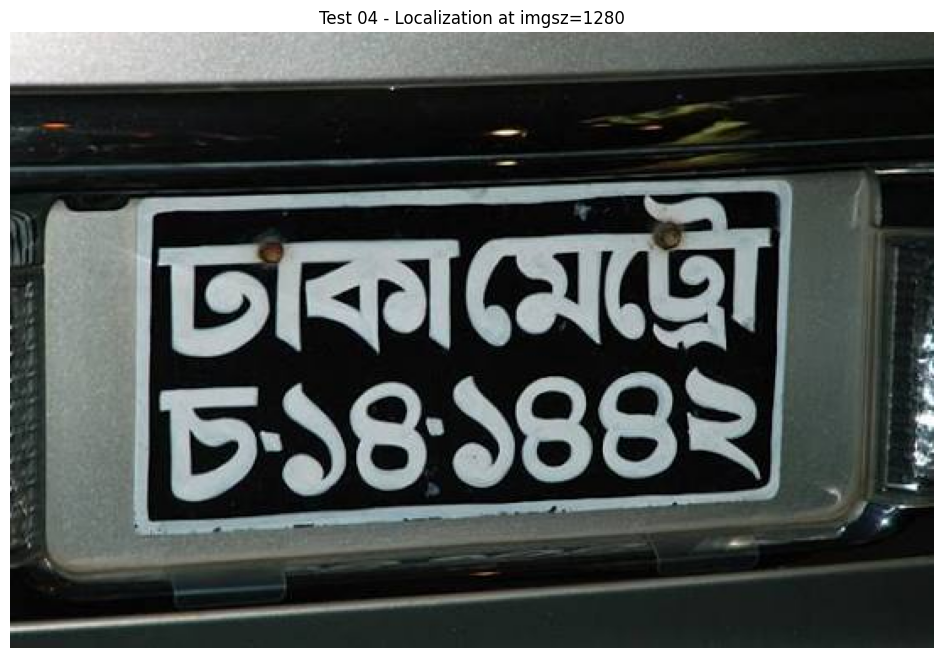

In [ ]:
test04_large_results = localization_model.predict(
    source=test04_image,
    conf=0.05,
    iou=0.5,
    imgsz=1280,
    device="cpu",
    verbose=False
)

large_result = test04_large_results[0]

print("TEST 04 - 1280 RESOLUTION CHECK")
print("================================")
print("Number of detections:", len(large_result.boxes))

if len(large_result.boxes) > 0:
    for i, box in enumerate(large_result.boxes):
        coords = box.xyxy[0].cpu().numpy()
        confidence = float(box.conf[0].cpu())

        print(
            f"Detection {i+1}: "
            f"box={coords.round(1)}, "
            f"confidence={confidence:.4f}"
        )

annotated = large_result.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 04 - Localization at imgsz=1280")
plt.show()

TEST 04 - CORRECTED DIAGNOSTIC CROP
Crop size: (420, 250)


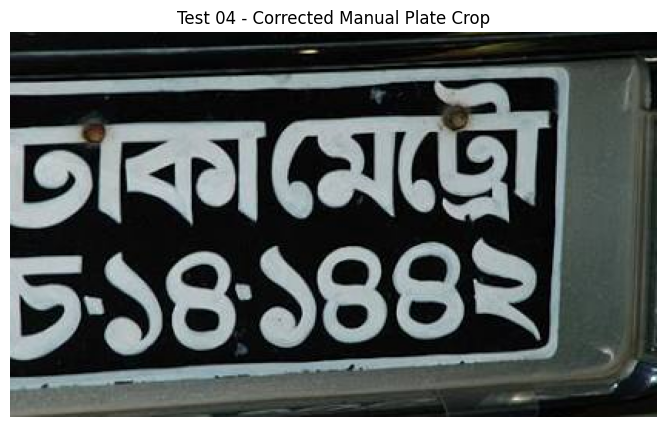

In [ ]:
test04_manual_crop = test04_image.crop(
    (100, 65, 520, 315)
)

print("TEST 04 - CORRECTED DIAGNOSTIC CROP")
print("===================================")
print("Crop size:", test04_manual_crop.size)

plt.figure(figsize=(10, 5))
plt.imshow(test04_manual_crop)
plt.axis("off")
plt.title("Test 04 - Corrected Manual Plate Crop")
plt.show()

TEST 04 - CHARACTER DETECTION
Number of detections: 9
1. 1 | conf=0.7867 | box=[       56.2       133.7       103.8       222.6]
2. 1 | conf=0.7813 | box=[      154.2       131.1       201.3       217.6]
3. 1 | conf=0.2113 | box=[       99.9         133       154.1       219.7]
4. 8 | conf=0.1846 | box=[        0.2       133.6        57.3       216.3]
5. 1 | conf=0.1395 | box=[      197.1       128.2       249.8         216]
6. ba | conf=0.1255 | box=[      128.5        59.6       155.3       112.2]
7. dhaka | conf=0.1184 | box=[          0          62        81.2       127.5]
8. gha | conf=0.1087 | box=[        0.3        62.9        56.6       120.9]
9. 4 | conf=0.1049 | box=[       99.9         133         154       219.1]


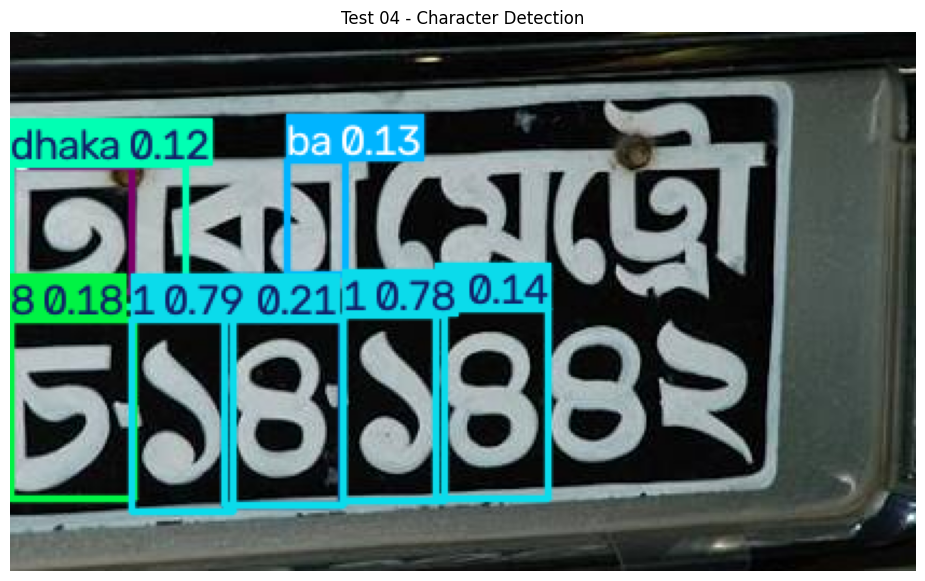

In [ ]:
test04_char_results = character_model.predict(
    source=test04_manual_crop,
    conf=0.10,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

char_result = test04_char_results[0]

print("TEST 04 - CHARACTER DETECTION")
print("=============================")
print("Number of detections:", len(char_result.boxes))

for i, box in enumerate(char_result.boxes):
    cls_id = int(box.cls[0].cpu())
    confidence = float(box.conf[0].cpu())
    coords = box.xyxy[0].cpu().numpy()

    print(
        f"{i+1}. "
        f"{character_model.names[cls_id]} | "
        f"conf={confidence:.4f} | "
        f"box={coords.round(1)}"
    )

annotated = char_result.plot()

plt.figure(figsize=(12, 7))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 04 - Character Detection")
plt.show()

In [ ]:
from pathlib import Path
from PIL import Image

test04_save_dir = (
    project_drive
    / "inference_tests"
    / "test_04_failure"
)

test04_save_dir.mkdir(
    parents=True,
    exist_ok=True
)

test04_image.save(
    test04_save_dir / "original_image.jpg"
)

test04_manual_crop.save(
    test04_save_dir / "manual_diagnostic_crop.jpg"
)

Image.fromarray(
    char_result.plot()[:, :, ::-1]
).save(
    test04_save_dir / "character_diagnostic.jpg"
)

diagnostic_text = """TEST 04 DIAGNOSTIC REPORT

Localization:
- conf=0.25, imgsz=640: 0 detections
- conf=0.05, imgsz=640: 0 detections
- conf=0.05, imgsz=1280: 0 detections

Character recognition:
- Manual diagnostic crop used.
- 9 detections at conf=0.10.
- Predictions were incomplete and conflicting.
- Multiple bottom characters were incorrectly classified as 1.
- Top-row recognition was weak.

Conclusion:
Test 04 failed at both localization and character recognition.
The image represents another difficult unseen/domain case.
Do not retrain based on this case alone.
"""

with open(
    test04_save_dir / "diagnostic.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(diagnostic_text)

print("TEST 04 SAVED")
print("=============")

for file in test04_save_dir.iterdir():
    print(file.name, "->", file.exists())

TEST 04 SAVED
original_image.jpg -> True
manual_diagnostic_crop.jpg -> True
character_diagnostic.jpg -> True
diagnostic.txt -> True


Saving images (1).jfif to images (1).jfif
TEST IMAGE 05
File: images (1).jfif
Size: (440, 327)
Mode: RGB


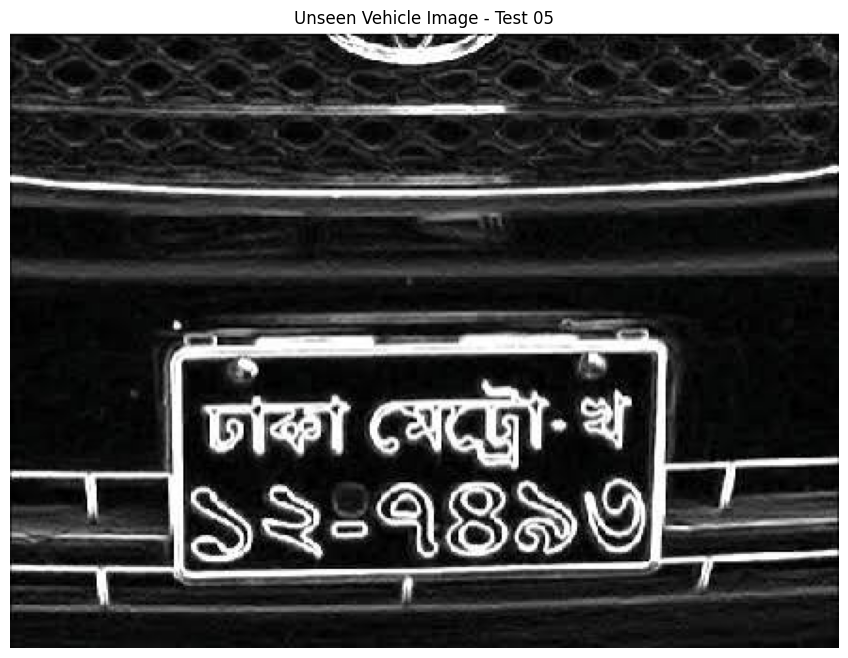

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

uploaded_05 = files.upload()

test05_path = Path(
    next(iter(uploaded_05.keys()))
)

test05_image = Image.open(
    test05_path
).convert("RGB")

print("TEST IMAGE 05")
print("=============")
print("File:", test05_path)
print("Size:", test05_image.size)
print("Mode:", test05_image.mode)

plt.figure(figsize=(12, 8))
plt.imshow(test05_image)
plt.axis("off")
plt.title("Unseen Vehicle Image - Test 05")
plt.show()

TEST 05 - LOCALIZATION
Number of detections: 0


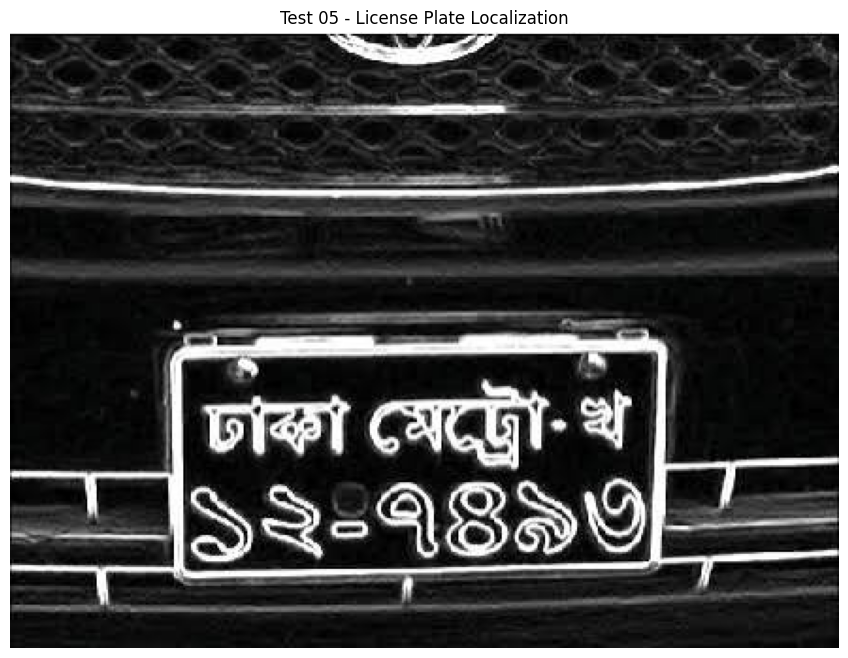

In [ ]:
test05_loc_results = localization_model.predict(
    source=test05_image,
    conf=0.25,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

test05_loc = test05_loc_results[0]

print("TEST 05 - LOCALIZATION")
print("======================")
print("Number of detections:", len(test05_loc.boxes))

if len(test05_loc.boxes) > 0:
    for i, box in enumerate(test05_loc.boxes):
        coords = box.xyxy[0].cpu().numpy()
        confidence = float(box.conf[0].cpu())

        print(
            f"Detection {i+1}: "
            f"box={coords.round(1)}, "
            f"confidence={confidence:.4f}"
        )

annotated = test05_loc.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 05 - License Plate Localization")
plt.show()

TEST 05 - LOW CONFIDENCE CHECK
Number of detections: 1
Detection 1: box=[      124.3       166.4       372.4       305.7], confidence=0.0750


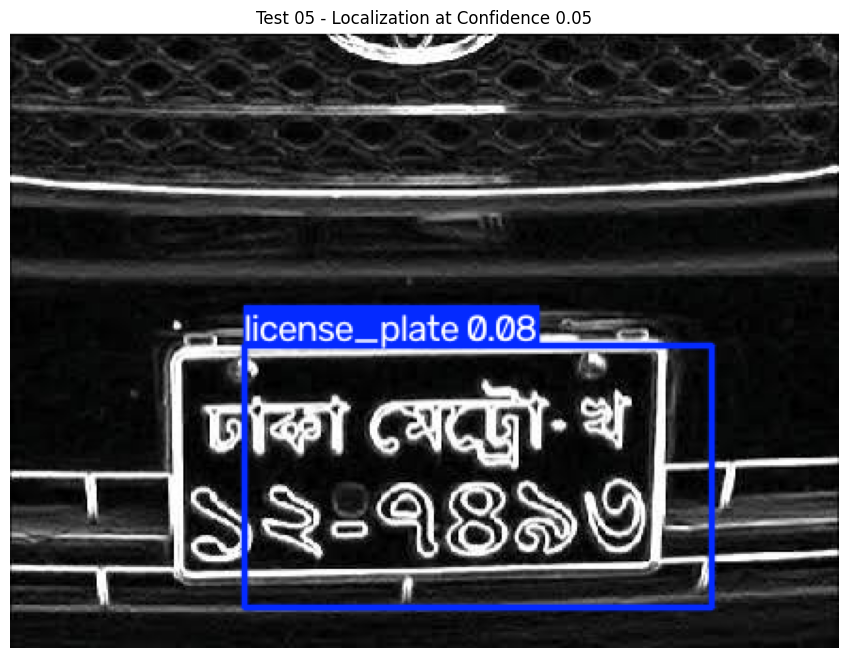

In [ ]:
test05_low_results = localization_model.predict(
    source=test05_image,
    conf=0.05,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

test05_low = test05_low_results[0]

print("TEST 05 - LOW CONFIDENCE CHECK")
print("==============================")
print("Number of detections:", len(test05_low.boxes))

if len(test05_low.boxes) > 0:
    for i, box in enumerate(test05_low.boxes):
        coords = box.xyxy[0].cpu().numpy()
        confidence = float(box.conf[0].cpu())

        print(
            f"Detection {i+1}: "
            f"box={coords.round(1)}, "
            f"confidence={confidence:.4f}"
        )

annotated = test05_low.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 05 - Localization at Confidence 0.05")
plt.show()

TEST 05 - AUTOMATIC PLATE CROP
Confidence: 0.075
Box: (124, 166, 372, 305)
Crop size: (248, 139)


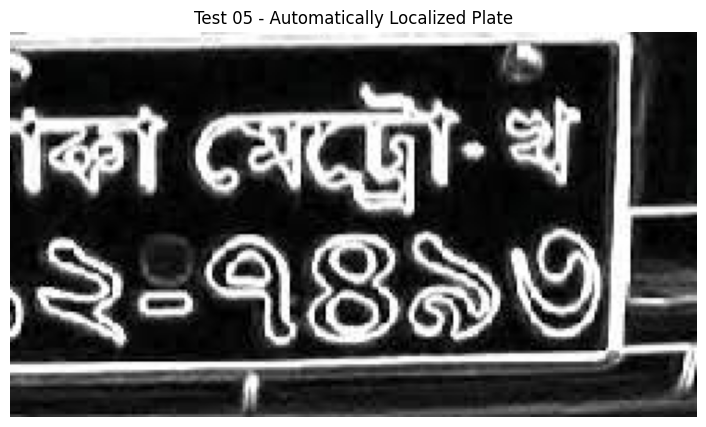

In [ ]:
box = test05_low.boxes[0]

x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
confidence = float(box.conf[0].cpu())

x1 = max(0, int(x1))
y1 = max(0, int(y1))
x2 = min(test05_image.width, int(x2))
y2 = min(test05_image.height, int(y2))

test05_plate_crop = test05_image.crop(
    (x1, y1, x2, y2)
)

print("TEST 05 - AUTOMATIC PLATE CROP")
print("==============================")
print("Confidence:", round(confidence, 4))
print("Box:", (x1, y1, x2, y2))
print("Crop size:", test05_plate_crop.size)

plt.figure(figsize=(10, 5))
plt.imshow(test05_plate_crop)
plt.axis("off")
plt.title("Test 05 - Automatically Localized Plate")
plt.show()

TEST 05 - CHARACTER DETECTION
Number of detections: 8
1. dhaka | conf=0.8989 | box=[          0        22.9        61.1        68.2]
2. 7 | conf=0.8971 | box=[       66.9        67.1       107.1       118.7]
3. metro | conf=0.8928 | box=[       62.7        15.4       167.4        67.9]
4. 9 | conf=0.8793 | box=[      140.7        66.7       180.5       119.1]
5. 4 | conf=0.8762 | box=[      106.5        68.2       142.4       119.8]
6. 3 | conf=0.8478 | box=[      179.8        64.4       215.3       114.2]
7. 2 | conf=0.8156 | box=[          8        68.4        45.8       119.3]
8. 1 | conf=0.6417 | box=[          0        71.9         7.9       117.5]


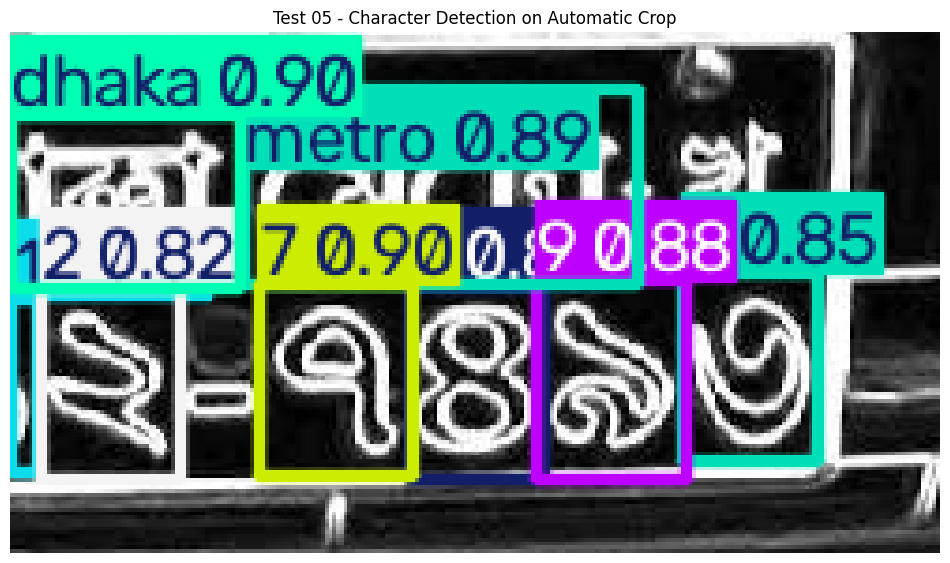

In [ ]:
test05_char_results = character_model.predict(
    source=test05_plate_crop,
    conf=0.10,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

test05_char = test05_char_results[0]

print("TEST 05 - CHARACTER DETECTION")
print("=============================")
print("Number of detections:", len(test05_char.boxes))

for i, box in enumerate(test05_char.boxes):
    cls_id = int(box.cls[0].cpu())
    confidence = float(box.conf[0].cpu())
    coords = box.xyxy[0].cpu().numpy()

    print(
        f"{i+1}. "
        f"{character_model.names[cls_id]} | "
        f"conf={confidence:.4f} | "
        f"box={coords.round(1)}"
    )

annotated = test05_char.plot()

plt.figure(figsize=(12, 7))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 05 - Character Detection on Automatic Crop")
plt.show()

TEST 05 - EXPANDED AUTOMATIC CROP
Original box: (124, 166, 372, 305)
Expanded box: (84, 166, 412, 305)
Crop size: (328, 139)
Aspect ratio: 2.36


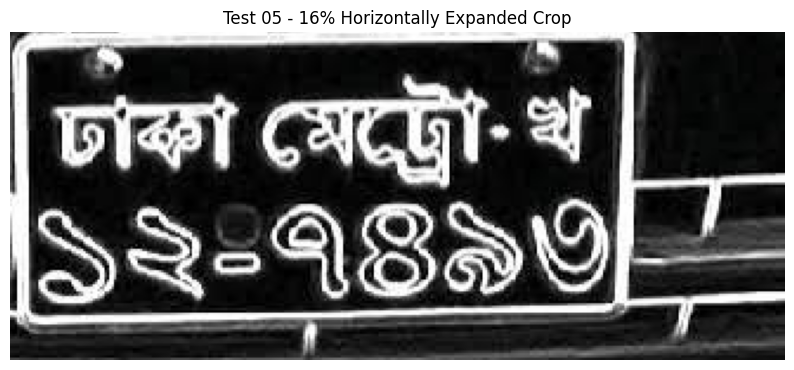

In [ ]:
box = test05_low.boxes[0]

x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

box_width = x2 - x1
horizontal_padding = 0.16 * box_width

ex1 = max(0, int(x1 - horizontal_padding))
ey1 = max(0, int(y1))
ex2 = min(test05_image.width, int(x2 + horizontal_padding))
ey2 = min(test05_image.height, int(y2))

test05_expanded_crop = test05_image.crop(
    (ex1, ey1, ex2, ey2)
)

print("TEST 05 - EXPANDED AUTOMATIC CROP")
print("=================================")
print("Original box:", (int(x1), int(y1), int(x2), int(y2)))
print("Expanded box:", (ex1, ey1, ex2, ey2))
print("Crop size:", test05_expanded_crop.size)
print(
    "Aspect ratio:",
    round(
        test05_expanded_crop.width /
        test05_expanded_crop.height,
        3
    )
)

plt.figure(figsize=(10, 5))
plt.imshow(test05_expanded_crop)
plt.axis("off")
plt.title("Test 05 - 16% Horizontally Expanded Crop")
plt.show()

TEST 05 - CHARACTER DETECTION AFTER EXPANSION
Number of detections: 8
1. dhaka | conf=0.9200 | box=[       12.6        22.1       102.4          68]
2. metro | conf=0.9054 | box=[      103.4        16.5       207.9        69.3]
3. 4 | conf=0.8954 | box=[      146.9        67.8       182.9       119.8]
4. 9 | conf=0.8911 | box=[        181        67.1       220.4       119.8]
5. 7 | conf=0.8797 | box=[      107.6          68       146.8         118]
6. 1 | conf=0.8770 | box=[        9.2        69.3        46.5       119.3]
7. 3 | conf=0.8549 | box=[      219.8        63.9       255.6       115.9]
8. 2 | conf=0.7857 | box=[       47.2        67.8        83.5       117.9]


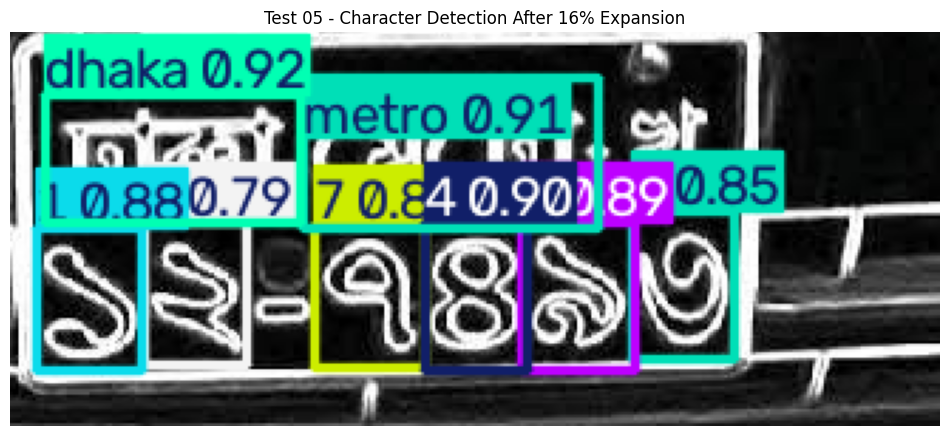

In [ ]:
test05_expanded_char_results = character_model.predict(
    source=test05_expanded_crop,
    conf=0.10,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

test05_expanded_char = test05_expanded_char_results[0]

print("TEST 05 - CHARACTER DETECTION AFTER EXPANSION")
print("=============================================")
print("Number of detections:", len(test05_expanded_char.boxes))

for i, box in enumerate(test05_expanded_char.boxes):
    cls_id = int(box.cls[0].cpu())
    confidence = float(box.conf[0].cpu())
    coords = box.xyxy[0].cpu().numpy()

    print(
        f"{i+1}. "
        f"{character_model.names[cls_id]} | "
        f"conf={confidence:.4f} | "
        f"box={coords.round(1)}"
    )

annotated = test05_expanded_char.plot()

plt.figure(figsize=(12, 7))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 05 - Character Detection After 16% Expansion")
plt.show()

In [ ]:
detections = []

for box in test05_expanded_char.boxes:
    cls_id = int(box.cls[0].cpu())
    label = character_model.names[cls_id]
    confidence = float(box.conf[0].cpu())

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    center_x = (x1 + x2) / 2
    center_y = (y1 + y2) / 2

    detections.append({
        "label": label,
        "confidence": confidence,
        "center_x": center_x,
        "center_y": center_y
    })

if detections:
    min_y = min(d["center_y"] for d in detections)
    max_y = max(d["center_y"] for d in detections)

    row_threshold = (min_y + max_y) / 2

    top_row = [
        d for d in detections
        if d["center_y"] < row_threshold
    ]

    bottom_row = [
        d for d in detections
        if d["center_y"] >= row_threshold
    ]

    top_row.sort(key=lambda d: d["center_x"])
    bottom_row.sort(key=lambda d: d["center_x"])

    top_text = " ".join(
        d["label"] for d in top_row
    )

    bottom_text = "".join(
        d["label"] for d in bottom_row
    )

    print("TEST 05 - AUTOMATIC RECONSTRUCTION")
    print("==================================")
    print("Top row   :", top_text)
    print("Bottom row:", bottom_text)

    print("\nFINAL RECOGNIZED PLATE")
    print("======================")
    print(top_text)
    print(bottom_text)

TEST 05 - AUTOMATIC RECONSTRUCTION
Top row   : dhaka metro
Bottom row: 127493

FINAL RECOGNIZED PLATE
dhaka metro
127493


In [ ]:
from pathlib import Path
from PIL import Image

test05_save_dir = (
    project_drive
    / "inference_tests"
    / "test_05_partial_success"
)

test05_save_dir.mkdir(
    parents=True,
    exist_ok=True
)

test05_image.save(
    test05_save_dir / "original_image.jpg"
)

test05_plate_crop.save(
    test05_save_dir / "automatic_crop.jpg"
)

test05_expanded_crop.save(
    test05_save_dir / "expanded_crop.jpg"
)

Image.fromarray(
    test05_expanded_char.plot()[:, :, ::-1]
).save(
    test05_save_dir / "character_detection.jpg"
)

recognition_text = """TEST 05 RESULT

Localization:
Normal confidence 0.25: 0 detections
Low confidence 0.05: 1 detection
Detection confidence: 0.075

Crop strategy:
Original localization crop was too narrow.
Automatic 16% horizontal expansion recovered the full plate.

Character recognition:
Top row: dhaka metro
Bottom row: 127493

Final status:
PARTIAL SUCCESS

Reason:
All six bottom digits were detected and ordered correctly.
dhaka and metro were detected with high confidence.
One top-row class was not detected.
"""

with open(
    test05_save_dir / "recognition.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(recognition_text)

print("TEST 05 SAVED")
print("=============")

for file in test05_save_dir.iterdir():
    print(file.name, "->", file.exists())

TEST 05 SAVED
original_image.jpg -> True
automatic_crop.jpg -> True
expanded_crop.jpg -> True
character_detection.jpg -> True
recognition.txt -> True


Saving images (3).jpg to images (3).jpg
TEST IMAGE 06
File: images (3).jpg
Size: (440, 311)
Mode: RGB


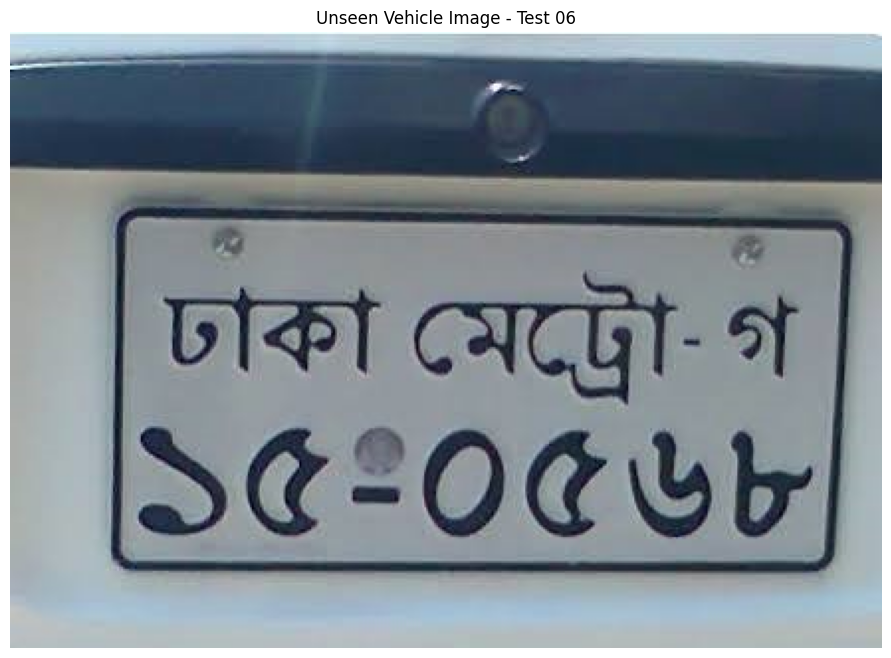

In [ ]:
from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

uploaded_06 = files.upload()

test06_path = Path(
    next(iter(uploaded_06.keys()))
)

test06_image = Image.open(
    test06_path
).convert("RGB")

print("TEST IMAGE 06")
print("=============")
print("File:", test06_path)
print("Size:", test06_image.size)
print("Mode:", test06_image.mode)

plt.figure(figsize=(12, 8))
plt.imshow(test06_image)
plt.axis("off")
plt.title("Unseen Vehicle Image - Test 06")
plt.show()

TEST 06 - LOCALIZATION
Number of detections: 0


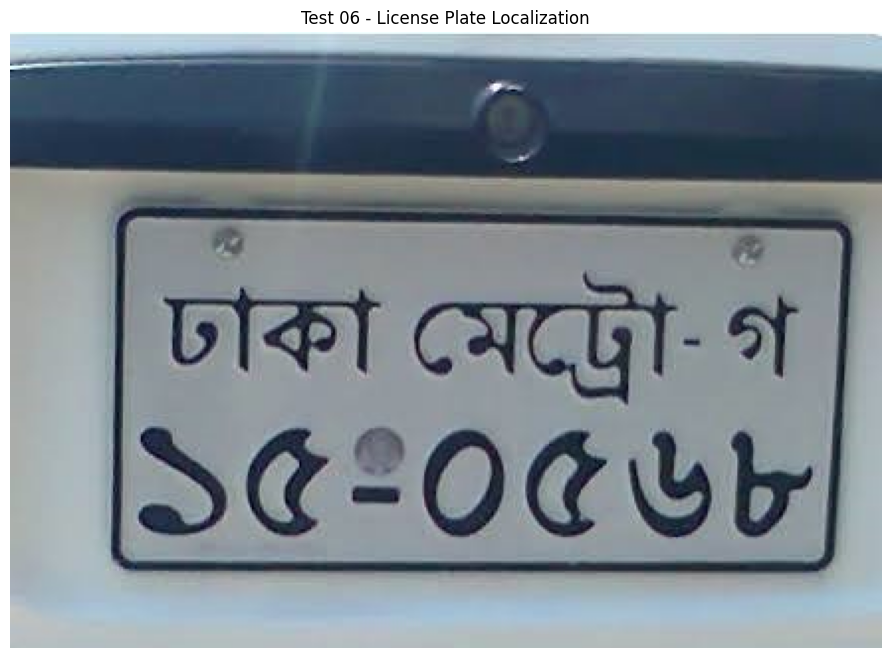

In [ ]:
test06_loc_results = localization_model.predict(
    source=test06_image,
    conf=0.25,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

test06_loc = test06_loc_results[0]

print("TEST 06 - LOCALIZATION")
print("======================")
print("Number of detections:", len(test06_loc.boxes))

if len(test06_loc.boxes) > 0:
    for i, box in enumerate(test06_loc.boxes):
        coords = box.xyxy[0].cpu().numpy()
        confidence = float(box.conf[0].cpu())

        print(
            f"Detection {i+1}: "
            f"box={coords.round(1)}, "
            f"confidence={confidence:.4f}"
        )

annotated = test06_loc.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 06 - License Plate Localization")
plt.show()

TEST 06 - LOW CONFIDENCE CHECK
Number of detections: 1
Detection 1: box=[      159.3       110.1       424.6       266.8], confidence=0.0911


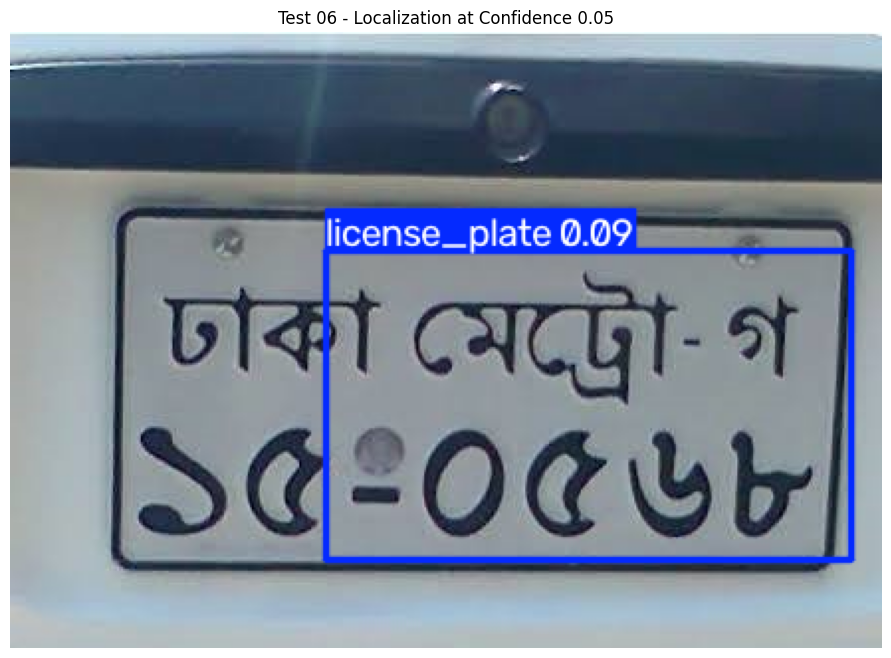

In [ ]:
test06_low_results = localization_model.predict(
    source=test06_image,
    conf=0.05,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

test06_low = test06_low_results[0]

print("TEST 06 - LOW CONFIDENCE CHECK")
print("==============================")
print("Number of detections:", len(test06_low.boxes))

if len(test06_low.boxes) > 0:
    for i, box in enumerate(test06_low.boxes):
        coords = box.xyxy[0].cpu().numpy()
        confidence = float(box.conf[0].cpu())

        print(
            f"Detection {i+1}: "
            f"box={coords.round(1)}, "
            f"confidence={confidence:.4f}"
        )

annotated = test06_low.plot()

plt.figure(figsize=(12, 8))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 06 - Localization at Confidence 0.05")
plt.show()

TEST 06 - MANUAL DIAGNOSTIC CROP
Crop size: (400, 180)


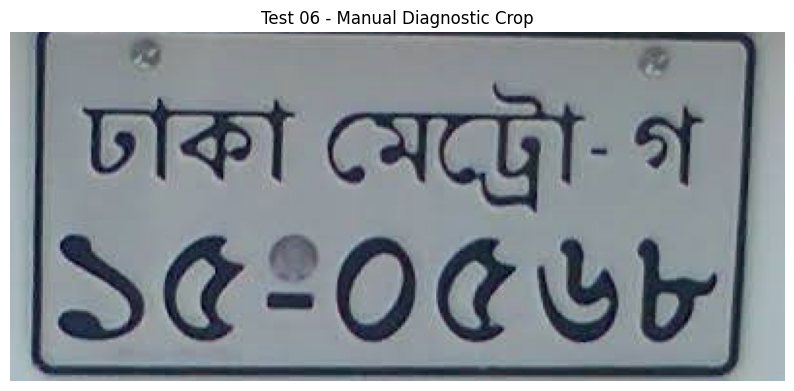

In [ ]:
test06_manual_crop = test06_image.crop(
    (40, 95, 440, 275)
)

print("TEST 06 - MANUAL DIAGNOSTIC CROP")
print("================================")
print("Crop size:", test06_manual_crop.size)

plt.figure(figsize=(10, 5))
plt.imshow(test06_manual_crop)
plt.axis("off")
plt.title("Test 06 - Manual Diagnostic Crop")
plt.show()

TEST 06 - CHARACTER DETECTION
Number of detections: 9
1. 5 | conf=0.9102 | box=[       73.1        95.1       126.5       174.8]
2. metro | conf=0.9000 | box=[      158.5        22.3       301.3        98.2]
3. 1 | conf=0.8908 | box=[       18.3        94.8          75       170.1]
4. dhaka | conf=0.8903 | box=[       29.4        27.3       155.3        89.7]
5. 8 | conf=0.8903 | box=[        320        95.8       370.7       170.7]
6. 6 | conf=0.8806 | box=[      267.2        95.8       320.9         173]
7. 0 | conf=0.8756 | box=[      162.9        95.7       216.7       173.8]
8. 5 | conf=0.8603 | box=[      214.7        96.4       268.5       174.8]
9. ga | conf=0.8555 | box=[      318.1        30.7       365.9        93.2]


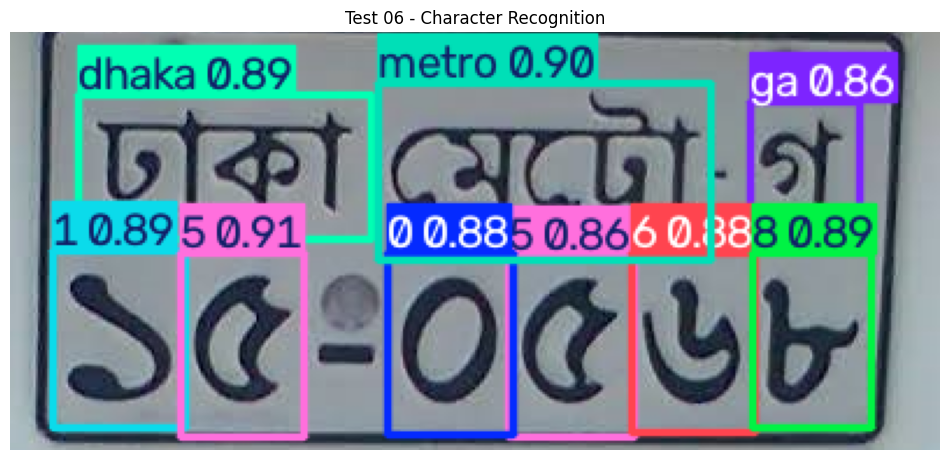

In [ ]:
test06_manual_char_results = character_model.predict(
    source=test06_manual_crop,
    conf=0.10,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

test06_manual_char = test06_manual_char_results[0]

print("TEST 06 - CHARACTER DETECTION")
print("=============================")
print("Number of detections:", len(test06_manual_char.boxes))

for i, box in enumerate(test06_manual_char.boxes):
    cls_id = int(box.cls[0].cpu())
    confidence = float(box.conf[0].cpu())
    coords = box.xyxy[0].cpu().numpy()

    print(
        f"{i+1}. "
        f"{character_model.names[cls_id]} | "
        f"conf={confidence:.4f} | "
        f"box={coords.round(1)}"
    )

annotated = test06_manual_char.plot()

plt.figure(figsize=(12, 6))
plt.imshow(annotated[:, :, ::-1])
plt.axis("off")
plt.title("Test 06 - Character Recognition")
plt.show()

In [ ]:
detections = []

for box in test06_manual_char.boxes:
    cls_id = int(box.cls[0].cpu())
    label = character_model.names[cls_id]

    x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

    detections.append({
        "label": label,
        "center_x": (x1 + x2) / 2,
        "center_y": (y1 + y2) / 2
    })

min_y = min(d["center_y"] for d in detections)
max_y = max(d["center_y"] for d in detections)

row_threshold = (min_y + max_y) / 2

top_row = [
    d for d in detections
    if d["center_y"] < row_threshold
]

bottom_row = [
    d for d in detections
    if d["center_y"] >= row_threshold
]

top_row.sort(key=lambda d: d["center_x"])
bottom_row.sort(key=lambda d: d["center_x"])

top_text = " ".join(d["label"] for d in top_row)
bottom_text = "".join(d["label"] for d in bottom_row)

print("TEST 06 - AUTOMATIC RECONSTRUCTION")
print("==================================")
print("Top row   :", top_text)
print("Bottom row:", bottom_text)

print("\nFINAL RECOGNIZED PLATE")
print("======================")
print(top_text)
print(bottom_text)

TEST 06 - AUTOMATIC RECONSTRUCTION
Top row   : dhaka metro ga
Bottom row: 150568

FINAL RECOGNIZED PLATE
dhaka metro ga
150568


In [ ]:
test06_save_dir = (
    project_drive
    / "inference_tests"
    / "test_06_localization_weakness"
)

test06_save_dir.mkdir(
    parents=True,
    exist_ok=True
)

test06_image.save(
    test06_save_dir / "original_image.jpg"
)

test06_plate_crop.save(
    test06_save_dir / "raw_automatic_crop.jpg"
)

test06_manual_crop.save(
    test06_save_dir / "complete_diagnostic_crop.jpg"
)

Image.fromarray(
    test06_manual_char.plot()[:, :, ::-1]
).save(
    test06_save_dir / "character_detection.jpg"
)

report = """TEST 06 RESULT

Localization:
- conf=0.25: 0 detections
- conf=0.05: 1 detection
- localization confidence: 0.0911
- predicted box: (159, 110, 424, 266)
- raw crop was incomplete
- 16% horizontal expansion was still incomplete
- 30% horizontal expansion was still incomplete

Character Recognition:
- Complete diagnostic crop used
- 9 components detected
- Top row: dhaka metro ga
- Bottom row: 150568

Final recognized plate:
dhaka metro ga
150568

Conclusion:
Character recognition succeeded strongly when the complete plate
was provided.

The main Test 06 failure is license plate localization and cropping.
A fixed horizontal padding percentage is not sufficient because the
localization box can itself be substantially shifted.
"""

with open(
    test06_save_dir / "recognition.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

print("TEST 06 SAVED")
print("=============")

for file in test06_save_dir.iterdir():
    print(file.name, "->", file.exists())

TEST 06 SAVED
original_image.jpg -> True
raw_automatic_crop.jpg -> True
complete_diagnostic_crop.jpg -> True
character_detection.jpg -> True
recognition.txt -> True


In [ ]:
summary_path = (
    project_drive
    / "inference_tests"
    / "unseen_test_summary.txt"
)

summary = """BANGLADESH LICENSE PLATE RECOGNITION
UNSEEN IMAGE TEST SUMMARY

Test 01
Status: SUCCESS
Localization successful.
Character recognition successful.
Recognized: dhaka metro ga / 371305

Test 02
Status: SUCCESS
Multiple overlapping localization boxes were merged.
Character recognition successful.
Recognized: dhaka metro ga / 319957

Test 03
Status: FAILURE
Localization failed even at low confidence and after upscaling.
Character recognition on manual crop was unstable.

Test 04
Status: FAILURE
Localization failed at conf=0.25 and conf=0.05.
Localization also failed at imgsz=1280.
Character recognition on manual crop was weak and conflicting.

Test 05
Status: PARTIAL SUCCESS
Localization failed at conf=0.25.
Plate detected at conf=0.05 with confidence about 0.075.
Localization crop was too narrow.
16% horizontal expansion recovered the complete plate.
Character model strongly detected dhaka, metro and six digits.
One top-row class was missing.
Recognized: dhaka metro / 127493

Test 06
Status: LOCALIZATION WEAKNESS
Localization failed at conf=0.25.
Plate detected at conf=0.05 with confidence 0.0911.
Raw localization box was substantially shifted.
16% and 30% horizontal expansion were insufficient.
With a complete diagnostic crop, character recognition was strong.
Recognized: dhaka metro ga / 150568

OVERALL FINDING

The major current bottleneck is license plate localization and
automatic cropping/generalization.

Character recognition performs strongly on several unseen images
when the complete plate is supplied, although difficult domain
cases such as Tests 03 and 04 remain.

Fixed horizontal padding should not be used as the final solution,
because an incorrectly shifted localization box cannot always be
recovered by percentage expansion alone.
"""

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:
    f.write(summary)

print("SUMMARY SAVED")
print("=============")
print(summary_path)
print("Exists:", summary_path.exists())

SUMMARY SAVED
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/unseen_test_summary.txt
Exists: True


In [ ]:
test06_ultralow_results = localization_model.predict(
    source=test06_image,
    conf=0.01,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

test06_ultralow = test06_ultralow_results[0]

print("TEST 06 - ULTRA-LOW CONFIDENCE DIAGNOSTIC")
print("==========================================")
print("Number of detections:", len(test06_ultralow.boxes))

for i, box in enumerate(test06_ultralow.boxes):
    coords = box.xyxy[0].cpu().numpy()
    confidence = float(box.conf[0].cpu())

    x1, y1, x2, y2 = coords
    width = x2 - x1
    height = y2 - y1
    aspect = width / height if height > 0 else 0

    print(
        f"{i+1}. "
        f"conf={confidence:.4f} | "
        f"box={coords.round(1)} | "
        f"size={width:.1f}x{height:.1f} | "
        f"aspect={aspect:.3f}"
    )

TEST 06 - ULTRA-LOW CONFIDENCE DIAGNOSTIC
Number of detections: 1
1. conf=0.0911 | box=[      159.3       110.1       424.6       266.8] | size=265.3x156.6 | aspect=1.694


In [ ]:
test05_ultralow_results = localization_model.predict(
    source=test05_image,
    conf=0.01,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)

test05_ultralow = test05_ultralow_results[0]

print("TEST 05 - ULTRA-LOW CONFIDENCE DIAGNOSTIC")
print("==========================================")
print("Number of detections:", len(test05_ultralow.boxes))

for i, box in enumerate(test05_ultralow.boxes):
    coords = box.xyxy[0].cpu().numpy()
    confidence = float(box.conf[0].cpu())

    x1, y1, x2, y2 = coords
    width = x2 - x1
    height = y2 - y1
    aspect = width / height if height > 0 else 0

    print(
        f"{i+1}. "
        f"conf={confidence:.4f} | "
        f"box={coords.round(1)} | "
        f"size={width:.1f}x{height:.1f} | "
        f"aspect={aspect:.3f}"
    )

TEST 05 - ULTRA-LOW CONFIDENCE DIAGNOSTIC
Number of detections: 1
1. conf=0.0750 | box=[      124.3       166.4       372.4       305.7] | size=248.1x139.3 | aspect=1.781


In [ ]:
from pathlib import Path

localization_train_dir = (
    project_drive
    / "dataset"
    / "yolo"
    / "License Plate Localization"
    / "images"
    / "train"
)

print("LOCALIZATION TRAINING DATA CHECK")
print("================================")
print("Path:", localization_train_dir)
print("Exists:", localization_train_dir.exists())

if localization_train_dir.exists():
    image_files = (
        list(localization_train_dir.glob("*.jpg"))
        + list(localization_train_dir.glob("*.jpeg"))
        + list(localization_train_dir.glob("*.png"))
        + list(localization_train_dir.glob("*.jfif"))
    )

    print("Images found:", len(image_files))

LOCALIZATION TRAINING DATA CHECK
Path: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/dataset/yolo/License Plate Localization/images/train
Exists: False


In [ ]:
from pathlib import Path

possible_files = [
    Path("/content/localization_yolo_dataset.zip"),
    Path("/content/localization_yolo_dataset"),
]

print("COLAB LOCALIZATION DATA CHECK")
print("=============================")

for path in possible_files:
    print(path, "->", path.exists())

    if path.exists() and path.is_dir():
        print("  Items:", len(list(path.rglob("*"))))

COLAB LOCALIZATION DATA CHECK
/content/localization_yolo_dataset.zip -> False
/content/localization_yolo_dataset -> False


In [ ]:
diagnosis_path = (
    project_drive
    / "inference_tests"
    / "localization_diagnosis.txt"
)

diagnosis = """LOCALIZATION DIAGNOSIS AFTER TESTS 01-06

Main finding:
License plate localization is currently the primary bottleneck.

Test 02:
Multiple overlapping localization boxes existed.
Merging them recovered the complete plate.

Test 05:
Normal threshold failed.
Low-confidence detection = 0.0750.
Only one candidate existed even at conf=0.01.
16% horizontal expansion helped recover the plate.

Test 06:
Normal threshold failed.
Low-confidence detection = 0.0911.
Only one candidate existed even at conf=0.01.
The predicted box was substantially shifted.
16% and 30% horizontal expansion were insufficient.

Tests 03 and 04:
No useful localization detection even at low confidence.

Conclusion:
Lowering confidence alone is not sufficient.
Merging boxes alone is not sufficient.
Fixed percentage expansion alone is not sufficient.

Next action:
Inspect the localization training dataset locally before deciding
whether augmentation, annotation improvement, additional data,
or localization retraining is required.
"""

with open(
    diagnosis_path,
    "w",
    encoding="utf-8"
) as f:
    f.write(diagnosis)

print("DIAGNOSIS SAVED")
print("================")
print(diagnosis_path)
print("Exists:", diagnosis_path.exists())

DIAGNOSIS SAVED
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/localization_diagnosis.txt
Exists: True


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/"
    "localization_yolo_improved.zip"
)

print("IMPROVED DATASET ZIP")
print("====================")
print("Exists:", zip_path.exists())

if zip_path.exists():
    print(
        "Size:",
        round(zip_path.stat().st_size / (1024**3), 2),
        "GB"
    )

IMPROVED DATASET ZIP
Exists: True
Size: 1.65 GB


In [ ]:
import zipfile
from pathlib import Path

extract_dir = Path("/content/localization_yolo_improved")

print("Extracting dataset...")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("\nEXTRACTION COMPLETE")
print("===================")
print("Path:", extract_dir)
print("Exists:", extract_dir.exists())

print("Train images:",
      len(list((extract_dir / "images" / "train").glob("*"))))

print("Validation images:",
      len(list((extract_dir / "images" / "validation").glob("*"))))

print("Test images:",
      len(list((extract_dir / "images" / "test").glob("*"))))

Extracting dataset...

EXTRACTION COMPLETE
Path: /content/localization_yolo_improved
Exists: True
Train images: 5660
Validation images: 640
Test images: 641


In [ ]:
import torch

print("ENVIRONMENT CHECK")
print("=================")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU: NOT AVAILABLE")

try:
    import ultralytics
    print("Ultralytics:", ultralytics.__version__)
except ImportError:
    print("Ultralytics: NOT INSTALLED")

ENVIRONMENT CHECK
PyTorch: 2.11.0+cpu
CUDA available: False
GPU: NOT AVAILABLE
Ultralytics: NOT INSTALLED


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

PROJECT_DRIVE = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

LOCALIZATION_MODEL = (
    PROJECT_DRIVE
    / "training_results"
    / "localization_yolo11n"
    / "weights"
    / "best.pt"
)

CHARACTER_MODEL = (
    PROJECT_DRIVE
    / "training_results"
    / "character_yolo11n"
    / "weights"
    / "best.pt"
)

print("FINAL PIPELINE MODEL CHECK")
print("==========================")

print("Localization model:")
print(LOCALIZATION_MODEL)
print("Exists:", LOCALIZATION_MODEL.exists())

print("\nCharacter model:")
print(CHARACTER_MODEL)
print("Exists:", CHARACTER_MODEL.exists())

FINAL PIPELINE MODEL CHECK
Localization model:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_yolo11n/weights/best.pt
Exists: True

Character model:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/character_yolo11n/weights/best.pt
Exists: True


In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 447.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 7.4 MB/s eta 0:00:00


In [ ]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)
print("STATUS: READY")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.176
STATUS: READY


In [ ]:
from ultralytics import YOLO

print("Loading localization model...")
localization_model = YOLO(str(LOCALIZATION_MODEL))

print("Loading character model...")
character_model = YOLO(str(CHARACTER_MODEL))

print("\nMODELS LOADED SUCCESSFULLY")
print("==========================")

print("\nLocalization classes:")
print(localization_model.names)

print("\nCharacter classes:")
print(character_model.names)

print("\nSTATUS: FINAL PIPELINE MODELS READY")

Loading localization model...
Loading character model...

MODELS LOADED SUCCESSFULLY

Localization classes:
{0: 'license_plate'}

Character classes:
{0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: 'ba', 11: 'ca', 12: 'chattogram', 13: 'da', 14: 'dhaka', 15: 'ga', 16: 'gha', 17: 'ha', 18: 'ja', 19: 'jashore', 20: 'ka', 21: 'kha', 22: 'khulna', 23: 'metro', 24: 'na', 25: 'ta', 26: 'va'}

STATUS: FINAL PIPELINE MODELS READY


In [ ]:
from PIL import Image
import numpy as np


def boxes_overlap_or_close(a, b, gap_ratio=0.08):
    x1a, y1a, x2a, y2a = a
    x1b, y1b, x2b, y2b = b

    wa = x2a - x1a
    wb = x2b - x1b
    gap = max(wa, wb) * gap_ratio

    return not (
        x2a + gap < x1b or
        x2b + gap < x1a or
        y2a + gap < y1b or
        y2b + gap < y1a
    )


def merge_boxes(boxes):
    boxes = [list(b) for b in boxes]

    changed = True

    while changed:
        changed = False
        result = []

        while boxes:
            current = boxes.pop(0)
            merged = False

            for i, other in enumerate(boxes):
                if boxes_overlap_or_close(current, other):
                    current = [
                        min(current[0], other[0]),
                        min(current[1], other[1]),
                        max(current[2], other[2]),
                        max(current[3], other[3])
                    ]

                    boxes.pop(i)
                    boxes.insert(0, current)
                    merged = True
                    changed = True
                    break

            if not merged:
                result.append(current)

        boxes = result

    return boxes


def recognize_plate(image_path):

    image = Image.open(image_path).convert("RGB")
    img_w, img_h = image.size

    loc_result = localization_model.predict(
        source=np.array(image),
        conf=0.05,
        iou=0.5,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    if len(loc_result.boxes) == 0:
        return {
            "status": "no_plate_detected",
            "text": None
        }

    detections = []

    for box in loc_result.boxes:
        confidence = float(box.conf[0])

        x1, y1, x2, y2 = map(
            float,
            box.xyxy[0].tolist()
        )

        detections.append(
            {
                "box": [x1, y1, x2, y2],
                "confidence": confidence
            }
        )

    raw_boxes = [d["box"] for d in detections]
    merged = merge_boxes(raw_boxes)

    best_box = max(
        merged,
        key=lambda b: (b[2] - b[0]) * (b[3] - b[1])
    )

    x1, y1, x2, y2 = best_box

    box_width = x2 - x1

    padding = box_width * 0.12

    x1 = max(0, int(x1 - padding))
    x2 = min(img_w, int(x2 + padding))

    y1 = max(0, int(y1))
    y2 = min(img_h, int(y2))

    plate_crop = image.crop(
        (x1, y1, x2, y2)
    )

    char_result = character_model.predict(
        source=np.array(plate_crop),
        conf=0.10,
        iou=0.5,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    characters = []

    for box in char_result.boxes:

        cls_id = int(box.cls[0])
        confidence = float(box.conf[0])

        cx, cy, w, h = map(
            float,
            box.xywh[0].tolist()
        )

        characters.append(
            {
                "label": character_model.names[cls_id],
                "confidence": confidence,
                "x": cx,
                "y": cy,
                "w": w,
                "h": h
            }
        )

    if not characters:
        return {
            "status": "plate_found_no_characters",
            "text": None,
            "crop": plate_crop
        }

    median_y = np.median(
        [c["y"] for c in characters]
    )

    top_row = [
        c for c in characters
        if c["y"] < median_y
    ]

    bottom_row = [
        c for c in characters
        if c["y"] >= median_y
    ]

    top_row.sort(key=lambda c: c["x"])
    bottom_row.sort(key=lambda c: c["x"])

    top_text = " ".join(
        c["label"] for c in top_row
    )

    bottom_text = "".join(
        c["label"] for c in bottom_row
    )

    final_text = (
        top_text + "\n" + bottom_text
    ).strip()

    return {
        "status": "success",
        "text": final_text,
        "crop": plate_crop,
        "localization_detections": detections,
        "characters": characters
    }


print("FINAL LPR FUNCTION CREATED")
print("==========================")
print("STATUS: READY FOR TESTING")

FINAL LPR FUNCTION CREATED
STATUS: READY FOR TESTING


In [ ]:
from pathlib import Path

TEST02_DIR = (
    PROJECT_DRIVE
    / "inference_tests"
    / "test_02"
)

print("TEST 02 FILES")
print("=============")

for file in TEST02_DIR.iterdir():
    print(file.name)

TEST 02 FILES
plate_crop.jpg
character_detection.jpg
recognition.txt


In [ ]:
from pathlib import Path

search_root = PROJECT_DRIVE

matches = []

for p in search_root.rglob("*"):
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".jfif", ".png"]:
        if p.name.lower() == "images (1).jfif":
            matches.append(p)

print("MATCHES FOUND:", len(matches))

for p in matches:
    print(p)

MATCHES FOUND: 0


In [ ]:
TEST_CROP = TEST02_DIR / "plate_crop.jpg"

result = character_model.predict(
    source=str(TEST_CROP),
    conf=0.10,
    iou=0.5,
    imgsz=640,
    device="cpu",
    verbose=False
)[0]

print("CHARACTER DETECTIONS")
print("====================")

for box in result.boxes:
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])
    x, y, w, h = map(float, box.xywh[0].tolist())

    print(
        character_model.names[cls_id],
        "| conf:", round(conf, 3),
        "| x:", round(x, 1),
        "| y:", round(y, 1)
    )

print("\nTotal detections:", len(result.boxes))

CHARACTER DETECTIONS
metro | conf: 0.902 | x: 92.7 | y: 36.4
1 | conf: 0.9 | x: 43.3 | y: 81.3
dhaka | conf: 0.896 | x: 37.5 | y: 45.5
5 | conf: 0.893 | x: 118.7 | y: 67.8
9 | conf: 0.892 | x: 78.0 | y: 75.2
7 | conf: 0.889 | x: 138.4 | y: 63.4
3 | conf: 0.88 | x: 21.6 | y: 83.3
9 | conf: 0.878 | x: 98.7 | y: 71.8
ga | conf: 0.866 | x: 135.2 | y: 30.3

Total detections: 9


In [ ]:
characters = []

for box in result.boxes:
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])
    x, y, w, h = map(float, box.xywh[0].tolist())

    characters.append({
        "label": character_model.names[cls_id],
        "confidence": conf,
        "x": x,
        "y": y,
        "w": w,
        "h": h
    })

characters_sorted_y = sorted(characters, key=lambda c: c["y"])

best_gap = -1
split_index = None

for i in range(len(characters_sorted_y) - 1):
    gap = characters_sorted_y[i + 1]["y"] - characters_sorted_y[i]["y"]

    if gap > best_gap:
        best_gap = gap
        split_index = i + 1

top_row = characters_sorted_y[:split_index]
bottom_row = characters_sorted_y[split_index:]

top_row.sort(key=lambda c: c["x"])
bottom_row.sort(key=lambda c: c["x"])

top_text = " ".join(c["label"] for c in top_row)
bottom_text = "".join(c["label"] for c in bottom_row)

print("RECONSTRUCTED PLATE")
print("===================")
print(top_text)
print(bottom_text)

print("\nRow gap:", round(best_gap, 2))

RECONSTRUCTED PLATE
dhaka metro ga
319957

Row gap: 17.95


In [ ]:
def reconstruct_plate_text(characters):

    if not characters:
        return None

    if len(characters) == 1:
        return characters[0]["label"]

    chars_y = sorted(characters, key=lambda c: c["y"])

    best_gap = -1
    split_index = None

    for i in range(len(chars_y) - 1):
        gap = chars_y[i + 1]["y"] - chars_y[i]["y"]

        if gap > best_gap:
            best_gap = gap
            split_index = i + 1

    top_row = chars_y[:split_index]
    bottom_row = chars_y[split_index:]

    top_row.sort(key=lambda c: c["x"])
    bottom_row.sort(key=lambda c: c["x"])

    top_text = " ".join(c["label"] for c in top_row)
    bottom_text = "".join(c["label"] for c in bottom_row)

    return f"{top_text}\n{bottom_text}"


test_text = reconstruct_plate_text(characters)

print("FINAL RECONSTRUCTION FUNCTION")
print("=============================")
print(test_text)

print("\nSTATUS: READY")

FINAL RECONSTRUCTION FUNCTION
dhaka metro ga
319957

STATUS: READY


In [ ]:
def recognize_plate(image_path):

    image = Image.open(image_path).convert("RGB")
    img_w, img_h = image.size

    loc_result = localization_model.predict(
        source=np.array(image),
        conf=0.05,
        iou=0.5,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    if len(loc_result.boxes) == 0:
        return {
            "status": "no_plate_detected",
            "text": None
        }

    detections = []

    for box in loc_result.boxes:
        confidence = float(box.conf[0])
        x1, y1, x2, y2 = map(float, box.xyxy[0].tolist())

        detections.append({
            "box": [x1, y1, x2, y2],
            "confidence": confidence
        })

    raw_boxes = [d["box"] for d in detections]
    merged_boxes = merge_boxes(raw_boxes)

    best_box = max(
        merged_boxes,
        key=lambda b: (b[2] - b[0]) * (b[3] - b[1])
    )

    x1, y1, x2, y2 = best_box

    box_width = x2 - x1
    padding = box_width * 0.12

    x1 = max(0, int(x1 - padding))
    x2 = min(img_w, int(x2 + padding))
    y1 = max(0, int(y1))
    y2 = min(img_h, int(y2))

    plate_crop = image.crop((x1, y1, x2, y2))

    char_result = character_model.predict(
        source=np.array(plate_crop),
        conf=0.10,
        iou=0.5,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    characters = []

    for box in char_result.boxes:
        cls_id = int(box.cls[0])
        confidence = float(box.conf[0])
        cx, cy, w, h = map(float, box.xywh[0].tolist())

        characters.append({
            "label": character_model.names[cls_id],
            "confidence": confidence,
            "x": cx,
            "y": cy,
            "w": w,
            "h": h
        })

    if not characters:
        return {
            "status": "plate_found_no_characters",
            "text": None,
            "crop": plate_crop,
            "localization_detections": detections
        }

    final_text = reconstruct_plate_text(characters)

    return {
        "status": "success",
        "text": final_text,
        "crop": plate_crop,
        "plate_box": [x1, y1, x2, y2],
        "localization_detections": detections,
        "characters": characters
    }


print("FINAL AUTOMATIC LPR PIPELINE UPDATED")
print("====================================")
print("STATUS: READY FOR END-TO-END TEST")

FINAL AUTOMATIC LPR PIPELINE UPDATED
STATUS: READY FOR END-TO-END TEST


In [ ]:
from google.colab import files

uploaded = files.upload()

TEST_IMAGE = list(uploaded.keys())[0]

print("Uploaded image:", TEST_IMAGE)

Saving images .jpg to images .jpg
Uploaded image: images .jpg


FINAL LPR RESULT
Image: images .jpg
Status: success

Recognized Plate:
dhaka metro ca
160385

Detected plate box: [68, 11, 210, 78]
Localization detections: 1
Character detections: 9


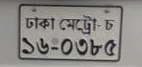

In [ ]:
result = recognize_plate(TEST_IMAGE)

print("FINAL LPR RESULT")
print("================")

print("Image:", TEST_IMAGE)
print("Status:", result["status"])

print("\nRecognized Plate:")
if result["text"]:
    print(result["text"])
else:
    print("None")

if "plate_box" in result:
    print("\nDetected plate box:", result["plate_box"])

if "localization_detections" in result:
    print(
        "Localization detections:",
        len(result["localization_detections"])
    )

if "characters" in result:
    print(
        "Character detections:",
        len(result["characters"])
    )

if "crop" in result:
    display(result["crop"])

In [ ]:
from pathlib import Path

SAVE_DIR = PROJECT_DRIVE / "inference_tests" / "final_pipeline_test"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

result["crop"].save(SAVE_DIR / "plate_crop.jpg")

with open(SAVE_DIR / "recognition.txt", "w", encoding="utf-8") as f:
    f.write("FINAL AUTOMATIC LPR TEST\n")
    f.write("========================\n")
    f.write(f"Image: {TEST_IMAGE}\n")
    f.write(f"Status: {result['status']}\n")
    f.write(f"Recognized Plate:\n{result['text']}\n")
    f.write(f"Plate Box: {result['plate_box']}\n")
    f.write(
        f"Localization Detections: "
        f"{len(result['localization_detections'])}\n"
    )
    f.write(
        f"Character Detections: "
        f"{len(result['characters'])}\n"
    )

print("RESULT SAVED")
print("============")
print(SAVE_DIR)

RESULT SAVED
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/final_pipeline_test


In [ ]:
FINAL_EVAL_DIR = PROJECT_DRIVE / "final_evaluation"
FINAL_EVAL_IMAGES = FINAL_EVAL_DIR / "images"
FINAL_EVAL_RESULTS = FINAL_EVAL_DIR / "results"

FINAL_EVAL_IMAGES.mkdir(parents=True, exist_ok=True)
FINAL_EVAL_RESULTS.mkdir(parents=True, exist_ok=True)

print("FINAL EVALUATION FOLDERS CREATED")
print("================================")
print("Images :", FINAL_EVAL_IMAGES)
print("Results:", FINAL_EVAL_RESULTS)
print("\nSTATUS: READY")

FINAL EVALUATION FOLDERS CREATED
Images : /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_evaluation/images
Results: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_evaluation/results

STATUS: READY


In [ ]:
from google.colab import files
import shutil

uploaded = files.upload()

uploaded_paths = []

for filename in uploaded.keys():
    src = Path(filename)
    dst = FINAL_EVAL_IMAGES / filename

    shutil.copy2(src, dst)
    uploaded_paths.append(dst)

print("\nFINAL EVALUATION IMAGES")
print("=======================")

for p in uploaded_paths:
    print(p.name)

print("\nTotal:", len(uploaded_paths))

Saving 3.jfif to 3.jfif
Saving 2.jfif to 2.jfif
Saving 1.jfif to 1.jfif

FINAL EVALUATION IMAGES
3.jfif
2.jfif
1.jfif

Total: 3


In [ ]:
evaluation_results = {}

for image_path in uploaded_paths:

    print("\n" + "=" * 50)
    print("IMAGE:", image_path.name)
    print("=" * 50)

    try:
        result = recognize_plate(image_path)

        evaluation_results[image_path.name] = result

        print("Status:", result["status"])

        if result.get("text"):
            print("Recognized Plate:")
            print(result["text"])
        else:
            print("Recognized Plate: None")

        print(
            "Localization detections:",
            len(result.get("localization_detections", []))
        )

        print(
            "Character detections:",
            len(result.get("characters", []))
        )

    except Exception as e:
        print("ERROR:", e)
        evaluation_results[image_path.name] = {
            "status": "error",
            "error": str(e)
        }

print("\n" + "=" * 50)
print("EVALUATION COMPLETE")
print("=" * 50)


IMAGE: 3.jfif
Status: success
Recognized Plate:
dhaka metro ga
147143
Localization detections: 1
Character detections: 9

IMAGE: 2.jfif
Status: success
Recognized Plate:
dhaka metro kha ga
192313
Localization detections: 1
Character detections: 10

IMAGE: 1.jfif
Status: success
Recognized Plate:
dhaka metro gha
218456
Localization detections: 1
Character detections: 9

EVALUATION COMPLETE



IMAGE: 3.jfif
PREDICTION:
dhaka metro ga
147143


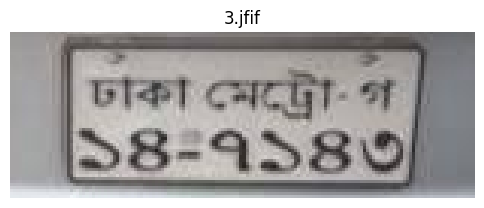


IMAGE: 2.jfif
PREDICTION:
dhaka metro kha ga
192313


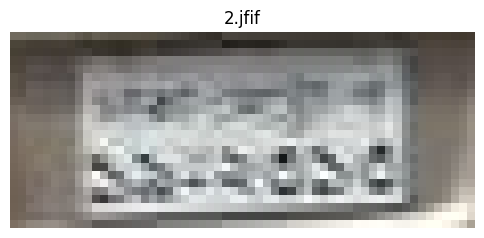


IMAGE: 1.jfif
PREDICTION:
dhaka metro gha
218456


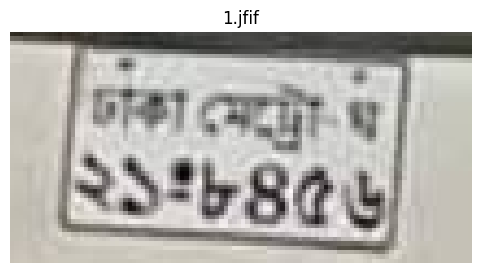

In [ ]:
import matplotlib.pyplot as plt

for image_name, result in evaluation_results.items():

    print("\n" + "=" * 45)
    print("IMAGE:", image_name)
    print("PREDICTION:")
    print(result.get("text"))
    print("=" * 45)

    if "crop" in result:
        plt.figure(figsize=(6, 3))
        plt.imshow(result["crop"])
        plt.axis("off")
        plt.title(image_name)
        plt.show()
    else:
        print("No crop available.")

In [ ]:
r = evaluation_results["2.jfif"]

print("2.jfif CHARACTER DETAILS")
print("========================")

chars = sorted(
    r["characters"],
    key=lambda c: (c["y"], c["x"])
)

for c in chars:
    print(
        c["label"],
        "| conf:", round(c["confidence"], 3),
        "| x:", round(c["x"], 1),
        "| y:", round(c["y"], 1)
    )

2.jfif CHARACTER DETAILS
ga | conf: 0.192 | x: 44.1 | y: 7.9
kha | conf: 0.15 | x: 44.1 | y: 8.0
metro | conf: 0.874 | x: 32.0 | y: 8.8
dhaka | conf: 0.884 | x: 16.7 | y: 9.5
3 | conf: 0.699 | x: 45.4 | y: 16.9
1 | conf: 0.865 | x: 39.6 | y: 17.3
3 | conf: 0.901 | x: 33.7 | y: 17.4
2 | conf: 0.822 | x: 27.9 | y: 17.5
1 | conf: 0.859 | x: 11.9 | y: 18.0
9 | conf: 0.846 | x: 18.0 | y: 18.0


In [ ]:
def remove_character_duplicates(characters, distance_ratio=0.35):

    if not characters:
        return []

    chars = sorted(
        characters,
        key=lambda c: c["confidence"],
        reverse=True
    )

    kept = []

    for char in chars:

        duplicate = False

        for existing in kept:

            avg_width = (char["w"] + existing["w"]) / 2
            avg_height = (char["h"] + existing["h"]) / 2

            x_close = (
                abs(char["x"] - existing["x"])
                < avg_width * distance_ratio
            )

            y_close = (
                abs(char["y"] - existing["y"])
                < avg_height * distance_ratio
            )

            if x_close and y_close:
                duplicate = True
                break

        if not duplicate:
            kept.append(char)

    return kept


filtered = remove_character_duplicates(
    evaluation_results["2.jfif"]["characters"]
)

print("BEFORE:", len(evaluation_results["2.jfif"]["characters"]))
print("AFTER :", len(filtered))

print("\nRECONSTRUCTED:")
print(reconstruct_plate_text(filtered))

BEFORE: 10
AFTER : 9

RECONSTRUCTED:
dhaka metro ga
192313


In [ ]:
def recognize_plate(image_path):

    image = Image.open(image_path).convert("RGB")
    img_w, img_h = image.size

    loc_result = localization_model.predict(
        source=np.array(image),
        conf=0.05,
        iou=0.5,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    if len(loc_result.boxes) == 0:
        return {
            "status": "no_plate_detected",
            "text": None
        }

    detections = []

    for box in loc_result.boxes:
        confidence = float(box.conf[0])
        x1, y1, x2, y2 = map(float, box.xyxy[0].tolist())

        detections.append({
            "box": [x1, y1, x2, y2],
            "confidence": confidence
        })

    raw_boxes = [d["box"] for d in detections]
    merged_boxes = merge_boxes(raw_boxes)

    best_box = max(
        merged_boxes,
        key=lambda b: (b[2] - b[0]) * (b[3] - b[1])
    )

    x1, y1, x2, y2 = best_box

    box_width = x2 - x1
    padding = box_width * 0.12

    x1 = max(0, int(x1 - padding))
    x2 = min(img_w, int(x2 + padding))
    y1 = max(0, int(y1))
    y2 = min(img_h, int(y2))

    plate_crop = image.crop((x1, y1, x2, y2))

    char_result = character_model.predict(
        source=np.array(plate_crop),
        conf=0.10,
        iou=0.5,
        imgsz=640,
        device="cpu",
        verbose=False
    )[0]

    characters = []

    for box in char_result.boxes:
        cls_id = int(box.cls[0])
        confidence = float(box.conf[0])
        cx, cy, w, h = map(float, box.xywh[0].tolist())

        characters.append({
            "label": character_model.names[cls_id],
            "confidence": confidence,
            "x": cx,
            "y": cy,
            "w": w,
            "h": h
        })

    characters = remove_character_duplicates(characters)

    if not characters:
        return {
            "status": "plate_found_no_characters",
            "text": None,
            "crop": plate_crop,
            "localization_detections": detections
        }

    final_text = reconstruct_plate_text(characters)

    return {
        "status": "success",
        "text": final_text,
        "crop": plate_crop,
        "plate_box": [x1, y1, x2, y2],
        "localization_detections": detections,
        "characters": characters
    }


print("FINAL PIPELINE UPDATED")
print("======================")
print("Duplicate filtering: ENABLED")
print("STATUS: READY")

FINAL PIPELINE UPDATED
Duplicate filtering: ENABLED
STATUS: READY


In [ ]:
updated_results = {}

for image_path in uploaded_paths:

    result = recognize_plate(image_path)
    updated_results[image_path.name] = result

    print("\n" + "=" * 45)
    print("IMAGE:", image_path.name)
    print("Status:", result["status"])

    print("Recognized Plate:")
    if result.get("text"):
        print(result["text"])
    else:
        print("None")

    print(
        "Localization detections:",
        len(result.get("localization_detections", []))
    )

    print(
        "Character detections after filtering:",
        len(result.get("characters", []))
    )

print("\n" + "=" * 45)
print("FINAL RE-TEST COMPLETE")


IMAGE: 3.jfif
Status: success
Recognized Plate:
dhaka metro ga
147143
Localization detections: 1
Character detections after filtering: 9

IMAGE: 2.jfif
Status: success
Recognized Plate:
dhaka metro ga
192313
Localization detections: 1
Character detections after filtering: 9

IMAGE: 1.jfif
Status: success
Recognized Plate:
dhaka metro gha
218456
Localization detections: 1
Character detections after filtering: 9

FINAL RE-TEST COMPLETE


In [ ]:
REPORT_PATH = FINAL_EVAL_RESULTS / "final_evaluation_report.txt"

with open(REPORT_PATH, "w", encoding="utf-8") as f:

    f.write("BANGLADESH LICENSE PLATE RECOGNITION\n")
    f.write("FINAL PIPELINE EVALUATION\n")
    f.write("=" * 45 + "\n\n")

    for image_name, result in updated_results.items():

        f.write(f"Image: {image_name}\n")
        f.write(f"Status: {result['status']}\n")
        f.write("Recognized Plate:\n")
        f.write(f"{result.get('text', 'None')}\n")

        f.write(
            f"Localization Detections: "
            f"{len(result.get('localization_detections', []))}\n"
        )

        f.write(
            f"Character Detections: "
            f"{len(result.get('characters', []))}\n"
        )

        f.write("-" * 45 + "\n")

print("FINAL EVALUATION REPORT SAVED")
print("=============================")
print(REPORT_PATH)

FINAL EVALUATION REPORT SAVED
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_evaluation/results/final_evaluation_report.txt


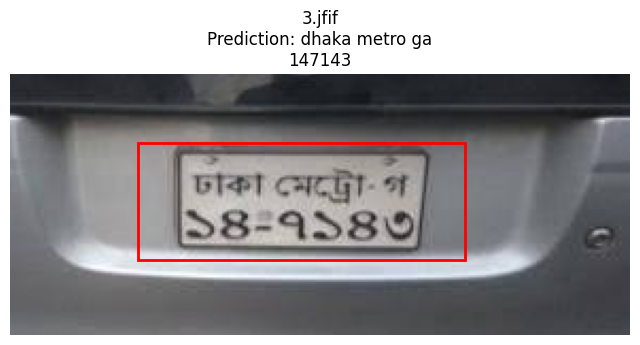

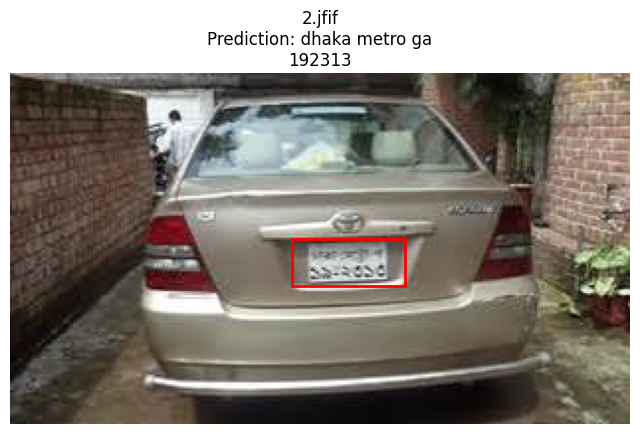

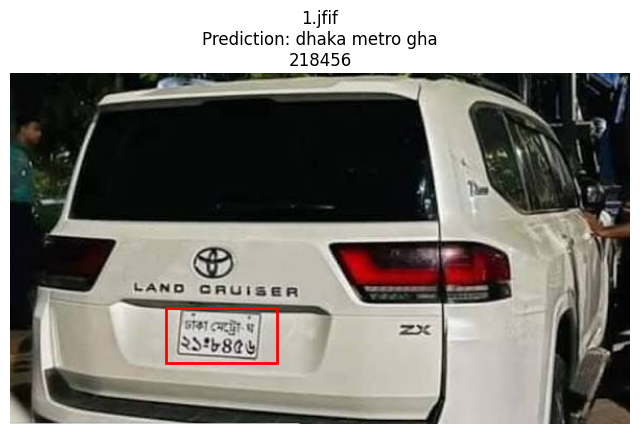

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

for image_path in uploaded_paths:

    result = updated_results[image_path.name]
    image = Image.open(image_path).convert("RGB")

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(image)

    if "plate_box" in result:
        x1, y1, x2, y2 = result["plate_box"]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

    prediction = result.get("text", "No plate detected")

    ax.set_title(
        f"{image_path.name}\nPrediction: {prediction}",
        fontsize=12
    )

    ax.axis("off")
    plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

for image_path in uploaded_paths:

    result = updated_results[image_path.name]
    image = Image.open(image_path).convert("RGB")

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(image)

    if "plate_box" in result:
        x1, y1, x2, y2 = result["plate_box"]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

    prediction = result.get("text", "No plate detected")

    ax.set_title(
        f"{image_path.name}\nPrediction: {prediction}",
        fontsize=12
    )

    ax.axis("off")

    output_path = (
        FINAL_EVAL_RESULTS /
        f"{image_path.stem}_result.jpg"
    )

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.close()

    print("Saved:", output_path.name)

print("\nSTATUS: ALL VISUAL RESULTS SAVED")

Saved: 3_result.jpg
Saved: 2_result.jpg
Saved: 1_result.jpg

STATUS: ALL VISUAL RESULTS SAVED


In [ ]:
REPORT_PATH = FINAL_EVAL_RESULTS / "final_evaluation_report.txt"

with open(REPORT_PATH, "w", encoding="utf-8") as f:

    f.write("BANGLADESH LICENSE PLATE RECOGNITION\n")
    f.write("FINAL END-TO-END PIPELINE EVALUATION\n")
    f.write("=" * 50 + "\n\n")

    for image_name, result in updated_results.items():

        f.write(f"Image: {image_name}\n")
        f.write(f"Status: {result['status']}\n")

        f.write("Recognized Plate:\n")
        f.write(f"{result.get('text') or 'None'}\n")

        f.write(
            f"Localization Detections: "
            f"{len(result.get('localization_detections', []))}\n"
        )

        f.write(
            f"Character Detections After Filtering: "
            f"{len(result.get('characters', []))}\n"
        )

        f.write("-" * 50 + "\n\n")

print("FINAL REPORT SAVED")
print("==================")
print(REPORT_PATH)

FINAL REPORT SAVED
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_evaluation/results/final_evaluation_report.txt


In [ ]:
PIPELINE_DIR = PROJECT_DRIVE / "final_pipeline"
PIPELINE_DIR.mkdir(parents=True, exist_ok=True)

print("FINAL PIPELINE FOLDER")
print("=====================")
print(PIPELINE_DIR)
print("STATUS: READY")

FINAL PIPELINE FOLDER
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_pipeline
STATUS: READY


In [ ]:
PIPELINE_FILE = PIPELINE_DIR / "lpr_pipeline.py"

with open(PIPELINE_FILE, "w", encoding="utf-8") as f:
    f.write("# Bangladesh License Plate Recognition Pipeline\n")

print("FILE CREATED SUCCESSFULLY")
print("=========================")
print(PIPELINE_FILE)
print("Exists:", PIPELINE_FILE.exists())

FILE CREATED SUCCESSFULLY
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_pipeline/lpr_pipeline.py
Exists: True


In [ ]:
code_part_1 = """
from PIL import Image
import numpy as np
from ultralytics import YOLO


def boxes_overlap_or_close(a, b, gap_ratio=0.08):
    x1a, y1a, x2a, y2a = a
    x1b, y1b, x2b, y2b = b

    wa = x2a - x1a
    wb = x2b - x1b
    gap = max(wa, wb) * gap_ratio

    return not (
        x2a + gap < x1b or
        x2b + gap < x1a or
        y2a + gap < y1b or
        y2b + gap < y1a
    )


def merge_boxes(boxes):
    boxes = [list(b) for b in boxes]
    changed = True

    while changed:
        changed = False
        result = []

        while boxes:
            current = boxes.pop(0)
            merged = False

            for i, other in enumerate(boxes):
                if boxes_overlap_or_close(current, other):
                    current = [
                        min(current[0], other[0]),
                        min(current[1], other[1]),
                        max(current[2], other[2]),
                        max(current[3], other[3])
                    ]

                    boxes.pop(i)
                    boxes.insert(0, current)
                    merged = True
                    changed = True
                    break

            if not merged:
                result.append(current)

        boxes = result

    return boxes
"""

with open(PIPELINE_FILE, "a", encoding="utf-8") as f:
    f.write(code_part_1)

print("PART 1 SAVED")
print("File:", PIPELINE_FILE)

PART 1 SAVED
File: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_pipeline/lpr_pipeline.py


In [ ]:
code_part_2 = """

def remove_character_duplicates(characters, distance_ratio=0.35):
    if not characters:
        return []

    chars = sorted(
        characters,
        key=lambda c: c["confidence"],
        reverse=True
    )

    kept = []

    for char in chars:
        duplicate = False

        for existing in kept:
            avg_width = (char["w"] + existing["w"]) / 2
            avg_height = (char["h"] + existing["h"]) / 2

            x_close = (
                abs(char["x"] - existing["x"])
                < avg_width * distance_ratio
            )

            y_close = (
                abs(char["y"] - existing["y"])
                < avg_height * distance_ratio
            )

            if x_close and y_close:
                duplicate = True
                break

        if not duplicate:
            kept.append(char)

    return kept


def reconstruct_plate_text(characters):
    if not characters:
        return None

    if len(characters) == 1:
        return characters[0]["label"]

    chars_y = sorted(characters, key=lambda c: c["y"])

    best_gap = -1
    split_index = None

    for i in range(len(chars_y) - 1):
        gap = chars_y[i + 1]["y"] - chars_y[i]["y"]

        if gap > best_gap:
            best_gap = gap
            split_index = i + 1

    top_row = chars_y[:split_index]
    bottom_row = chars_y[split_index:]

    top_row.sort(key=lambda c: c["x"])
    bottom_row.sort(key=lambda c: c["x"])

    top_text = " ".join(c["label"] for c in top_row)
    bottom_text = "".join(c["label"] for c in bottom_row)

    return f"{top_text}\\n{bottom_text}"
"""

with open(PIPELINE_FILE, "a", encoding="utf-8") as f:
    f.write(code_part_2)

print("PART 2 SAVED")
print("File:", PIPELINE_FILE)

PART 2 SAVED
File: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_pipeline/lpr_pipeline.py


In [ ]:
code_part_3 = """

class BangladeshLPR:

    def __init__(self, localization_model_path, character_model_path):
        self.localization_model = YOLO(str(localization_model_path))
        self.character_model = YOLO(str(character_model_path))

    def recognize(self, image_path):
        image = Image.open(image_path).convert("RGB")
        img_w, img_h = image.size

        loc_result = self.localization_model.predict(
            source=np.array(image),
            conf=0.05,
            iou=0.5,
            imgsz=640,
            device="cpu",
            verbose=False
        )[0]

        if len(loc_result.boxes) == 0:
            return {
                "status": "no_plate_detected",
                "text": None
            }

        detections = []

        for box in loc_result.boxes:
            confidence = float(box.conf[0])
            x1, y1, x2, y2 = map(
                float,
                box.xyxy[0].tolist()
            )

            detections.append({
                "box": [x1, y1, x2, y2],
                "confidence": confidence
            })

        merged_boxes = merge_boxes(
            [d["box"] for d in detections]
        )

        best_box = max(
            merged_boxes,
            key=lambda b: (b[2] - b[0]) * (b[3] - b[1])
        )

        x1, y1, x2, y2 = best_box

        padding = (x2 - x1) * 0.12

        x1 = max(0, int(x1 - padding))
        x2 = min(img_w, int(x2 + padding))
        y1 = max(0, int(y1))
        y2 = min(img_h, int(y2))

        plate_crop = image.crop((x1, y1, x2, y2))
"""

with open(PIPELINE_FILE, "a", encoding="utf-8") as f:
    f.write(code_part_3)

print("PART 3 SAVED")
print("File:", PIPELINE_FILE)

PART 3 SAVED
File: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_pipeline/lpr_pipeline.py


In [ ]:
code_part_4 = """

        char_result = self.character_model.predict(
            source=np.array(plate_crop),
            conf=0.10,
            iou=0.5,
            imgsz=640,
            device="cpu",
            verbose=False
        )[0]

        characters = []

        for box in char_result.boxes:
            cls_id = int(box.cls[0])
            confidence = float(box.conf[0])

            cx, cy, w, h = map(
                float,
                box.xywh[0].tolist()
            )

            characters.append({
                "label": self.character_model.names[cls_id],
                "confidence": confidence,
                "x": cx,
                "y": cy,
                "w": w,
                "h": h
            })

        characters = remove_character_duplicates(characters)

        if not characters:
            return {
                "status": "plate_found_no_characters",
                "text": None,
                "crop": plate_crop,
                "localization_detections": detections
            }

        final_text = reconstruct_plate_text(characters)

        return {
            "status": "success",
            "text": final_text,
            "crop": plate_crop,
            "plate_box": [x1, y1, x2, y2],
            "localization_detections": detections,
            "characters": characters
        }
"""

with open(PIPELINE_FILE, "a", encoding="utf-8") as f:
    f.write(code_part_4)

print("PART 4 SAVED")
print("================")
print("BangladeshLPR class: COMPLETE")
print("File:", PIPELINE_FILE)

PART 4 SAVED
BangladeshLPR class: COMPLETE
File: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_pipeline/lpr_pipeline.py


In [ ]:
import py_compile

try:
    py_compile.compile(
        str(PIPELINE_FILE),
        doraise=True
    )

    print("PIPELINE SYNTAX CHECK")
    print("=====================")
    print("Syntax: VALID")
    print("STATUS: PASS")

except Exception as e:
    print("PIPELINE SYNTAX CHECK")
    print("=====================")
    print("STATUS: FAILED")
    print("Error:", e)

PIPELINE SYNTAX CHECK
Syntax: VALID
STATUS: PASS


In [ ]:
import sys

if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))

from lpr_pipeline import BangladeshLPR

print("PIPELINE IMPORT TEST")
print("====================")
print("BangladeshLPR imported successfully")
print("STATUS: PASS")

PIPELINE IMPORT TEST
BangladeshLPR imported successfully
STATUS: PASS


SAVED PIPELINE REAL TEST
Image: 3.jfif
Status: success

Recognized Plate:
dhaka metro ga
147143

Character detections: 9


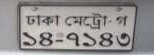

In [ ]:
saved_lpr = BangladeshLPR(
    LOCALIZATION_MODEL,
    CHARACTER_MODEL
)

test_path = FINAL_EVAL_IMAGES / "3.jfif"

saved_result = saved_lpr.recognize(test_path)

print("SAVED PIPELINE REAL TEST")
print("========================")
print("Image:", test_path.name)
print("Status:", saved_result["status"])
print("\nRecognized Plate:")
print(saved_result.get("text"))

print(
    "\nCharacter detections:",
    len(saved_result.get("characters", []))
)

if "crop" in saved_result:
    display(saved_result["crop"])

In [ ]:
INFO_FILE = PIPELINE_DIR / "pipeline_info.txt"

info = f"""
BANGLADESH LICENSE PLATE RECOGNITION
FINAL PIPELINE INFORMATION
====================================

Localization Model:
{LOCALIZATION_MODEL}

Character Recognition Model:
{CHARACTER_MODEL}

Localization Confidence:
0.05

Character Confidence:
0.10

Localization Image Size:
640

Character Image Size:
640

Plate Crop Horizontal Padding:
12%

Post-processing:
- Overlapping localization box merging
- Character duplicate/conflict filtering
- Two-row character reconstruction
- Left-to-right character ordering

Pipeline:
Vehicle Image
-> License Plate Localization
-> Plate Crop
-> Character Detection
-> Duplicate Filtering
-> Row Reconstruction
-> Final Plate Text

Saved Pipeline:
{PIPELINE_FILE}

Saved Pipeline Test:
PASS

Test Prediction:
dhaka metro ga
147143
"""

with open(INFO_FILE, "w", encoding="utf-8") as f:
    f.write(info.strip())

print("PIPELINE INFORMATION SAVED")
print("==========================")
print(INFO_FILE)

PIPELINE INFORMATION SAVED
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_pipeline/pipeline_info.txt


In [ ]:
IMPROVED_ZIP = (
    PROJECT_DRIVE
    / "localization_yolo_improved.zip"
)

print("IMPROVED LOCALIZATION DATASET")
print("=============================")
print("Path:", IMPROVED_ZIP)
print("Exists:", IMPROVED_ZIP.exists())

if IMPROVED_ZIP.exists():
    size_gb = IMPROVED_ZIP.stat().st_size / (1024 ** 3)
    print("Size:", round(size_gb, 2), "GB")

print("\nSTATUS:",
      "READY FOR FUTURE GPU TRAINING"
      if IMPROVED_ZIP.exists()
      else "MISSING")

IMPROVED LOCALIZATION DATASET
Path: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/localization_yolo_improved.zip
Exists: True
Size: 1.65 GB

STATUS: READY FOR FUTURE GPU TRAINING


In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/localization_yolo_improved.zip"
)

print("Exists:", zip_path.exists())

if zip_path.exists():
    print("Size (GB):", round(zip_path.stat().st_size / (1024**3), 2))

Exists: False


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/localization_yolo_improved.zip"
)

print("Exists:", zip_path.exists())

if zip_path.exists():
    print("Size (GB):", round(zip_path.stat().st_size / (1024**3), 2))

Exists: True
Size (GB): 1.65


In [5]:
import os
import shutil
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/localization_yolo_improved.zip"
)

extract_dir = Path("/content/localization_yolo_improved")

# Remove an old runtime copy if one exists
if extract_dir.exists():
    shutil.rmtree(extract_dir)

# Extract ZIP
shutil.unpack_archive(str(zip_path), str(extract_dir))

print("Extraction complete.")
print("Location:", extract_dir)

Extraction complete.
Location: /content/localization_yolo_improved


In [6]:
for split in ["train", "validation", "test"]:
    image_dir = extract_dir / "images" / split
    label_dir = extract_dir / "labels" / split

    print(
        split,
        "| images:", len(list(image_dir.glob("*"))),
        "| labels:", len(list(label_dir.glob("*.txt")))
    )

train | images: 5660 | labels: 5660
validation | images: 640 | labels: 640
test | images: 641 | labels: 641


In [7]:
from pathlib import Path

yaml_path = Path("/content/localization_yolo_improved/data.yaml")

print("Exists:", yaml_path.exists())
print("\n--- data.yaml ---")
print(yaml_path.read_text())

Exists: True

--- data.yaml ---
path: d:/Documents/Ml project/Bangladesh_License_Plate_Recognition/dataset/yolo/License Plate Localization
train: images/train
val: images/validation
test: images/test

names:
  0: license_plate



In [8]:
from pathlib import Path

yaml_path = Path("/content/localization_yolo_improved/data.yaml")

yaml_content = """path: /content/localization_yolo_improved
train: images/train
val: images/validation
test: images/test

names:
  0: license_plate
"""

yaml_path.write_text(yaml_content, encoding="utf-8")

print(yaml_path.read_text())

path: /content/localization_yolo_improved
train: images/train
val: images/validation
test: images/test

names:
  0: license_plate



In [9]:
!pip install -q ultralytics

import torch
from ultralytics import YOLO

print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 8.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
CUDA: True
GPU: Tesla T4


In [10]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/localization_yolo_improved/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    device=0,
    workers=2,
    project="/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results",
    name="localization_yolo11n_improved",
    exist_ok=True
)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/localization_yolo_improved/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=localization_yolo11n_improved, nbs=64, nms=N

In [11]:
from ultralytics import YOLO

improved_model_path = (
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/"
    "training_results/localization_yolo11n_improved/weights/best.pt"
)

improved_model = YOLO(improved_model_path)

test_results = improved_model.val(
    data="/content/localization_yolo_improved/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    plots=True,
    project="/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results",
    name="localization_improved_test",
    exist_ok=True
)

print("\n=== IMPROVED LOCALIZATION HELD-OUT TEST ===")
print("Precision:", test_results.box.mp)
print("Recall:", test_results.box.mr)
print("mAP50:", test_results.box.map50)
print("mAP50-95:", test_results.box.map)

Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 92.1±93.3 MB/s, size: 272.3 KB)
val: Scanning /content/localization_yolo_improved/labels/test... 641 images, 172 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 641/641 419.0it/s 1.5s
val: New cache created: /content/localization_yolo_improved/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 41/41 3.7it/s 11.1s
                   all        641        485      0.981      0.979      0.993      0.792
Speed: 1.6ms preprocess, 5.8ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_improved_test

=== IMPROVED LOCALIZATION HELD-OUT TEST ===
Precision: 0.9814056003102916
Recall: 0.9794159488746472
mAP50

In [12]:
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests"
)

print("Inference tests folder exists:", base.exists())

if base.exists():
    print("\nAvailable folders/files:")
    for p in sorted(base.iterdir()):
        print("-", p.name)

Inference tests folder exists: True

Available folders/files:
- final_pipeline_test
- localization_diagnosis.txt
- test_01
- test_02
- test_03_failure
- test_04_failure
- test_05_partial_success
- test_06_localization_weakness
- unseen_test_summary.txt


In [3]:
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests"
)

folders = [
    "test_03_failure",
    "test_04_failure",
    "test_05_partial_success",
    "test_06_localization_weakness"
]

for folder in folders:
    folder_path = base / folder

    print(f"\n=== {folder} ===")

    if not folder_path.exists():
        print("Folder not found")
        continue

    for p in sorted(folder_path.rglob("*")):
        if p.is_file():
            print(p.relative_to(folder_path))


=== test_03_failure ===
character_diagnostic.jpg
diagnostic.txt
manual_diagnostic_crop.jpg
original_image.jpg

=== test_04_failure ===
character_diagnostic.jpg
diagnostic.txt
manual_diagnostic_crop.jpg
original_image.jpg

=== test_05_partial_success ===
automatic_crop.jpg
character_detection.jpg
expanded_crop.jpg
original_image.jpg
recognition.txt

=== test_06_localization_weakness ===
character_detection.jpg
complete_diagnostic_crop.jpg
original_image.jpg
raw_automatic_crop.jpg
recognition.txt


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

baseline_model = (
    project /
    "training_results/localization_yolo11n/weights/best.pt"
)

improved_model = (
    project /
    "training_results/localization_yolo11n_improved/weights/best.pt"
)

test_base = project / "inference_tests"

test_images = {
    "Test 03": test_base / "test_03_failure/original_image.jpg",
    "Test 04": test_base / "test_04_failure/original_image.jpg",
    "Test 05": test_base / "test_05_partial_success/original_image.jpg",
    "Test 06": test_base / "test_06_localization_weakness/original_image.jpg",
}

print("Baseline model:", baseline_model.exists())
print("Improved model:", improved_model.exists())

print("\nDifficult unseen images:")
for name, path in test_images.items():
    print(name, ":", path.exists(), "|", path)

Baseline model: True
Improved model: True

Difficult unseen images:
Test 03 : True | /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/test_03_failure/original_image.jpg
Test 04 : True | /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/test_04_failure/original_image.jpg
Test 05 : True | /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/test_05_partial_success/original_image.jpg
Test 06 : True | /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/test_06_localization_weakness/original_image.jpg


In [7]:
!pip install -q ultralytics==8.4.177

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 21.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 6.6 MB/s eta 0:00:00


In [8]:
from ultralytics import YOLO

print("Ultralytics imported successfully ✅")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics imported successfully ✅


In [9]:
from ultralytics import YOLO

baseline = YOLO(str(baseline_model))
improved = YOLO(str(improved_model))

models = {
    "BASELINE": baseline,
    "IMPROVED": improved
}

conf_levels = [0.25, 0.05, 0.01]

for test_name, image_path in test_images.items():

    print("\n" + "=" * 70)
    print(test_name)
    print("=" * 70)

    for model_name, model in models.items():

        print(f"\n--- {model_name} ---")

        for conf in conf_levels:

            result = model.predict(
                source=str(image_path),
                conf=conf,
                iou=0.5,
                imgsz=640,
                device="cpu",
                verbose=False
            )[0]

            boxes = result.boxes

            print(f"\nConfidence >= {conf}")
            print("Detections:", len(boxes))

            if len(boxes) > 0:
                for i, box in enumerate(boxes):
                    xyxy = box.xyxy[0].cpu().tolist()
                    score = float(box.conf[0].cpu())

                    print(
                        f"  Box {i+1}: "
                        f"[{xyxy[0]:.1f}, {xyxy[1]:.1f}, "
                        f"{xyxy[2]:.1f}, {xyxy[3]:.1f}] "
                        f"| conf={score:.4f}"
                    )


Test 03

--- BASELINE ---

Confidence >= 0.25
Detections: 0

Confidence >= 0.05
Detections: 0

Confidence >= 0.01
Detections: 0

--- IMPROVED ---

Confidence >= 0.25
Detections: 0

Confidence >= 0.05
Detections: 0

Confidence >= 0.01
Detections: 0

Test 04

--- BASELINE ---

Confidence >= 0.25
Detections: 0

Confidence >= 0.05
Detections: 0

Confidence >= 0.01
Detections: 0

--- IMPROVED ---

Confidence >= 0.25
Detections: 0

Confidence >= 0.05
Detections: 0

Confidence >= 0.01
Detections: 0

Test 05

--- BASELINE ---

Confidence >= 0.25
Detections: 0

Confidence >= 0.05
Detections: 1
  Box 1: [123.6, 166.1, 372.4, 305.9] | conf=0.0802

Confidence >= 0.01
Detections: 1
  Box 1: [123.6, 166.1, 372.4, 305.9] | conf=0.0802

--- IMPROVED ---

Confidence >= 0.25
Detections: 1
  Box 1: [115.9, 156.7, 358.7, 298.8] | conf=0.6808

Confidence >= 0.05
Detections: 1
  Box 1: [115.9, 156.7, 358.7, 298.8] | conf=0.6808

Confidence >= 0.01
Detections: 1
  Box 1: [115.9, 156.7, 358.7, 298.8] | conf=

In [10]:
from pathlib import Path
from PIL import Image, ImageDraw

compare_dir = (
    project /
    "training_results/localization_improved_comparison"
)
compare_dir.mkdir(parents=True, exist_ok=True)

for test_name in ["Test 05", "Test 06"]:

    image_path = test_images[test_name]
    original = Image.open(image_path).convert("RGB")

    for model_name, model in {
        "baseline": baseline,
        "improved": improved
    }.items():

        result = model.predict(
            source=str(image_path),
            conf=0.01,
            iou=0.5,
            imgsz=640,
            device="cpu",
            verbose=False
        )[0]

        img = original.copy()
        draw = ImageDraw.Draw(img)

        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].cpu().tolist()
            conf = float(box.conf[0].cpu())

            draw.rectangle(
                [x1, y1, x2, y2],
                outline="red",
                width=3
            )

            draw.text(
                (x1, max(0, y1 - 15)),
                f"{conf:.3f}",
                fill="red"
            )

        output = compare_dir / (
            f"{test_name.lower().replace(' ', '_')}_{model_name}.jpg"
        )

        img.save(output)
        print("Saved:", output)

Saved: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_improved_comparison/test_05_baseline.jpg
Saved: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_improved_comparison/test_05_improved.jpg
Saved: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_improved_comparison/test_06_baseline.jpg
Saved: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_improved_comparison/test_06_improved.jpg



test_05_baseline.jpg


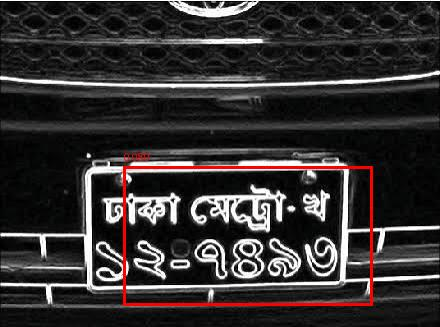


test_05_improved.jpg


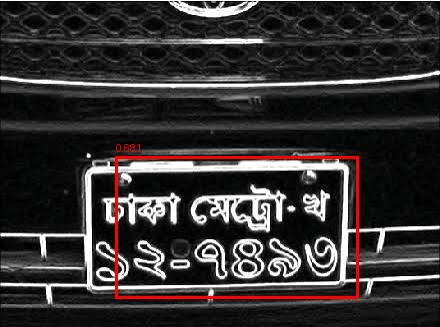


test_06_baseline.jpg


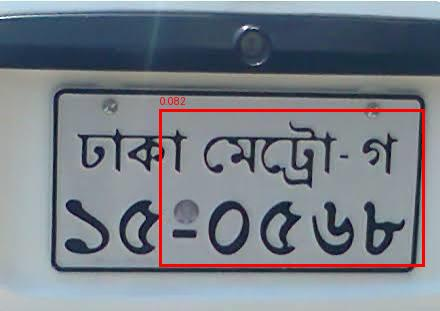


test_06_improved.jpg


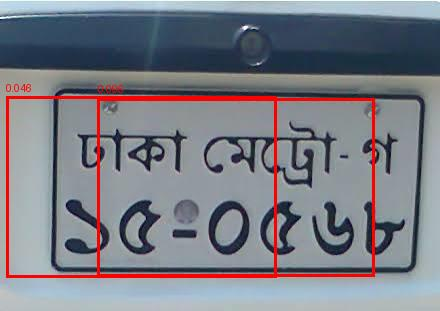

In [11]:
from IPython.display import display
from PIL import Image

files = [
    "test_05_baseline.jpg",
    "test_05_improved.jpg",
    "test_06_baseline.jpg",
    "test_06_improved.jpg",
]

for filename in files:
    path = compare_dir / filename

    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)

    display(Image.open(path))

In [12]:
from pathlib import Path

report_path = (
    project /
    "training_results/localization_improved_comparison/"
    "baseline_vs_improved_report.txt"
)

report = """Bangladesh License Plate Recognition
Localization Model Comparison
========================================

BASELINE HELD-OUT TEST
Images: 641
Instances: 485
Backgrounds: 172

Precision: 0.983
Recall: 0.971
mAP50: 0.991
mAP50-95: 0.788

IMPROVED HELD-OUT TEST
Images: 641
Instances: 485
Backgrounds: 172

Precision: 0.9814
Recall: 0.9794
mAP50: 0.9926
mAP50-95: 0.7920

DIFFICULT UNSEEN TESTS
Test 03:
Baseline: no detection
Improved: no detection
Result: unresolved

Test 04:
Baseline: no detection
Improved: no detection
Result: unresolved

Test 05:
Baseline confidence: 0.0802
Improved confidence: 0.6808
Result: major improvement

Test 06:
Baseline confidence: 0.0822
Improved best confidence: 0.0955
Result: localization remains weak

FINAL DECISION
The improved YOLO11n localization model is selected as the final
localization model.

Reasons:
1. Higher held-out test recall.
2. Higher held-out mAP50.
3. Higher held-out mAP50-95.
4. Major generalization improvement on difficult unseen Test 05.
5. Precision reduction is very small.

LIMITATION
The improved model does not fully solve difficult localization.
Tests 03 and 04 remain undetected, while Test 06 remains weak.
Additional diverse real-world training data would likely be required
to improve these domain-shifted cases further.
"""

report_path.write_text(report, encoding="utf-8")

print("Saved:", report_path)
print("Exists:", report_path.exists())

Saved: /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/localization_improved_comparison/baseline_vs_improved_report.txt
Exists: True


In [13]:
from pathlib import Path
import shutil

project = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

source_model = (
    project /
    "training_results/localization_yolo11n_improved/weights/best.pt"
)

final_model_dir = project / "models/localization"
final_model_dir.mkdir(parents=True, exist_ok=True)

final_model = final_model_dir / "localization_best.pt"

shutil.copy2(source_model, final_model)

print("Source exists:", source_model.exists())
print("Final model exists:", final_model.exists())

if final_model.exists():
    print("Final model size (MB):",
          round(final_model.stat().st_size / (1024**2), 2))

Source exists: True
Final model exists: True
Final model size (MB): 5.24


In [19]:
from pathlib import Path
import sys

project = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

pipeline_dir = project / "final_pipeline"
sys.path.insert(0, str(pipeline_dir))

from lpr_pipeline import BangladeshLPR

localization_model = project / "models/localization/localization_best.pt"
character_model = project / "models/character/character_best.pt"

lpr = BangladeshLPR(
    str(localization_model),
    str(character_model)
)

test_image = (
    project /
    "final_evaluation/images/3.jfif"
)

result = lpr.recognize(str(test_image))

print("Status:", result.get("status"))
print("Plate text:", result.get("plate_text"))
print("Localization box:", result.get("plate_box"))
print("Localization confidence:", result.get("localization_confidence"))
print("Character detections:", len(result.get("characters", [])))

Status: success
Plate text: None
Localization box: [58, 33, 215, 89]
Localization confidence: None
Character detections: 9


In [16]:
from pathlib import Path

project = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

matches = list(project.rglob("character_best.pt"))

print("character_best.pt matches:")
for p in matches:
    print("-", p)

print("\nCharacter training best.pt candidates:")
for p in project.rglob("best.pt"):
    if "character" in str(p).lower():
        print("-", p)

character_best.pt matches:

Character training best.pt candidates:
- /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/character_yolo11n/weights/best.pt
- /content/drive/MyDrive/Bangladesh_License_Plate_Recognition/training_results/character_sanity/weights/best.pt


In [17]:
from pathlib import Path
import shutil

project = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

source_character = (
    project /
    "training_results/character_yolo11n/weights/best.pt"
)

final_character_dir = project / "models/character"
final_character_dir.mkdir(parents=True, exist_ok=True)

final_character = final_character_dir / "character_best.pt"

shutil.copy2(source_character, final_character)

print("Source exists:", source_character.exists())
print("Final character model exists:", final_character.exists())

if final_character.exists():
    print(
        "Final model size (MB):",
        round(final_character.stat().st_size / (1024**2), 2)
    )

Source exists: True
Final character model exists: True
Final model size (MB): 5.26


In [18]:
from pathlib import Path
import sys

project = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

pipeline_dir = project / "final_pipeline"

if str(pipeline_dir) not in sys.path:
    sys.path.insert(0, str(pipeline_dir))

from lpr_pipeline import BangladeshLPR

localization_model = project / "models/localization/localization_best.pt"
character_model = project / "models/character/character_best.pt"

print("Localization model:", localization_model.exists())
print("Character model:", character_model.exists())

lpr = BangladeshLPR(
    str(localization_model),
    str(character_model)
)

test_image = project / "final_evaluation/images/3.jfif"

result = lpr.recognize(str(test_image))

print("\n=== FINAL PIPELINE TEST ===")
print("Status:", result.get("status"))
print("Plate text:", result.get("plate_text"))
print("Plate box:", result.get("plate_box"))
print("Localization confidence:", result.get("localization_confidence"))
print("Character detections:", len(result.get("characters", [])))

Localization model: True
Character model: True

=== FINAL PIPELINE TEST ===
Status: success
Plate text: None
Plate box: [58, 33, 215, 89]
Localization confidence: None
Character detections: 9


In [20]:
from pprint import pprint

print("=== RAW PIPELINE RESULT ===")
pprint(result)

=== RAW PIPELINE RESULT ===
{'characters': [{'confidence': 0.9007826447486877,
                 'h': 20.757591247558594,
                 'label': '4',
                 'w': 17.34783172607422,
                 'x': 108.55722045898438,
                 'y': 39.226593017578125},
                {'confidence': 0.894929826259613,
                 'h': 20.27594566345215,
                 'label': '1',
                 'w': 17.441329956054688,
                 'x': 91.44589233398438,
                 'y': 38.94291687011719},
                {'confidence': 0.8926355838775635,
                 'h': 19.821178436279297,
                 'label': 'metro',
                 'w': 45.985313415527344,
                 'x': 88.29023742675781,
                 'y': 20.08869171142578},
                {'confidence': 0.8906906247138977,
                 'h': 19.79383087158203,
                 'label': '3',
                 'w': 16.404266357421875,
                 'x': 125.30131530761719,
               

Recognized Plate:
dhaka metro ga
147143

Localization confidence: 0.8722


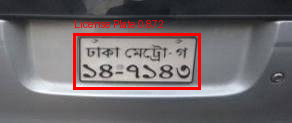

In [21]:
from PIL import Image, ImageDraw
from IPython.display import display

# Original image
img = Image.open(test_image).convert("RGB")
draw = ImageDraw.Draw(img)

# Final localization detection
det = result["localization_detections"][0]

x1, y1, x2, y2 = det["box"]
conf = det["confidence"]

# Draw localization box
draw.rectangle(
    [x1, y1, x2, y2],
    outline="red",
    width=3
)

draw.text(
    (x1, max(0, y1 - 15)),
    f"License Plate {conf:.3f}",
    fill="red"
)

print("Recognized Plate:")
print(result["text"])
print(f"\nLocalization confidence: {conf:.4f}")

display(img)

Recognized Plate:
dhaka metro ga
147143

Localization confidence: 0.8722

Saved to:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/final_evaluation/results/final_improved_model_detection.jpg
Exists: True


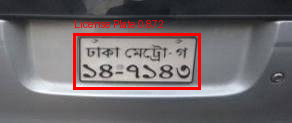

In [22]:
from PIL import Image, ImageDraw
from IPython.display import display
from pathlib import Path

# Load original image
img = Image.open(test_image).convert("RGB")
draw = ImageDraw.Draw(img)

# Localization detection
det = result["localization_detections"][0]

x1, y1, x2, y2 = det["box"]
conf = det["confidence"]

# Draw bounding box
draw.rectangle(
    [x1, y1, x2, y2],
    outline="red",
    width=3
)

draw.text(
    (x1, max(0, y1 - 15)),
    f"License Plate {conf:.3f}",
    fill="red"
)

# Save to Google Drive
save_dir = project / "final_evaluation/results"
save_dir.mkdir(parents=True, exist_ok=True)

save_path = save_dir / "final_improved_model_detection.jpg"

img.save(save_path, quality=95)

print("Recognized Plate:")
print(result["text"])

print(f"\nLocalization confidence: {conf:.4f}")
print("\nSaved to:")
print(save_path)
print("Exists:", save_path.exists())

# Display
display(img)

In [23]:
from google.colab import files

uploaded = files.upload()

Saving test_vehicle.jpg to test_vehicle.jpg


Image exists: True
Localization model: True
Character model: True

=== NEW UNSEEN IMAGE TEST ===
Status: success

Recognized Plate:
dhaka metro ga
144662

Characters detected: 9

Localization confidence: 0.8879
Final crop box: [119, 218, 203, 255]

Detection image saved:
/content/drive/MyDrive/Bangladesh_License_Plate_Recognition/inference_tests/final_new_image_test/test_vehicle_detected.jpg
Saved: True

=== DETECTION IMAGE ===


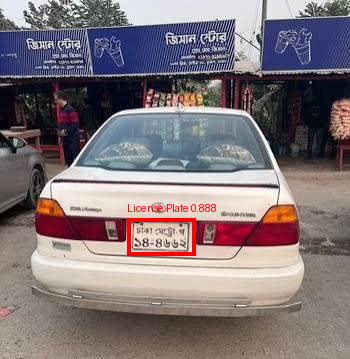


=== DETECTED PLATE CROP ===


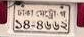

In [24]:
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display
import sys

# --------------------------------------------------
# Paths
# --------------------------------------------------
project = Path(
    "/content/drive/MyDrive/Bangladesh_License_Plate_Recognition"
)

pipeline_dir = project / "final_pipeline"

if str(pipeline_dir) not in sys.path:
    sys.path.insert(0, str(pipeline_dir))

from lpr_pipeline import BangladeshLPR

localization_model = project / "models/localization/localization_best.pt"
character_model = project / "models/character/character_best.pt"

# Newly uploaded unseen image
test_image_new = Path("/content/test_vehicle.jpg")

print("Image exists:", test_image_new.exists())
print("Localization model:", localization_model.exists())
print("Character model:", character_model.exists())

# --------------------------------------------------
# Load final pipeline
# --------------------------------------------------
lpr = BangladeshLPR(
    str(localization_model),
    str(character_model)
)

# Run recognition
result_new = lpr.recognize(str(test_image_new))

print("\n=== NEW UNSEEN IMAGE TEST ===")
print("Status:", result_new.get("status"))

if result_new.get("status") == "success":

    print("\nRecognized Plate:")
    print(result_new.get("text"))

    print("\nCharacters detected:",
          len(result_new.get("characters", [])))

    # --------------------------------------------------
    # Draw detection on ORIGINAL image
    # --------------------------------------------------
    img = Image.open(test_image_new).convert("RGB")
    draw = ImageDraw.Draw(img)

    detections = result_new.get(
        "localization_detections", []
    )

    for det in detections:

        x1, y1, x2, y2 = det["box"]
        conf = det["confidence"]

        draw.rectangle(
            [x1, y1, x2, y2],
            outline="red",
            width=4
        )

        draw.text(
            (x1, max(0, y1 - 16)),
            f"License Plate {conf:.3f}",
            fill="red"
        )

        print(
            f"\nLocalization confidence: {conf:.4f}"
        )

    print(
        "Final crop box:",
        result_new.get("plate_box")
    )

    # --------------------------------------------------
    # Save detection image to Drive
    # --------------------------------------------------
    save_dir = (
        project /
        "inference_tests/final_new_image_test"
    )

    save_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    save_path = (
        save_dir /
        "test_vehicle_detected.jpg"
    )

    img.save(save_path, quality=95)

    print("\nDetection image saved:")
    print(save_path)
    print("Saved:", save_path.exists())

    # --------------------------------------------------
    # Display detection image
    # --------------------------------------------------
    print("\n=== DETECTION IMAGE ===")
    display(img)

    # --------------------------------------------------
    # Display plate crop
    # --------------------------------------------------
    print("\n=== DETECTED PLATE CROP ===")

    crop = result_new.get("crop")

    if crop is not None:
        display(crop)

else:
    print("\nNo successful plate recognition.")
    print("Full result:")
    print(result_new)